In [1]:
import pandas as pd
import numpy as np
!pip install tweet-preprocessor
import preprocessor as p

import seaborn as sns
import matplotlib.pyplot as plt
from datetime import date

# **Impor Data**

In [2]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
df = pd.read_csv('dataset_efisiensi_energi.csv')
display(df.head())

Saving dataset_efisiensi_energi.csv to dataset_efisiensi_energi.csv


,videoWebUrl,submittedVideoUrl,input,cid,createTime,createTimeISO,text,diggCount,likedByAuthor,pinnedByAuthor,repliesToId,replyCommentTotal,uid,uniqueId,avatarThumbnail,mentions,detailedMentions
0,https://www.tiktok.com/@detikcom/video/7623419...,https://vt.tiktok.com/ZSC8VgcA2/,https://vt.tiktok.com/ZSC8VgcA2/,7623427729807557384,1774967597,2026-03-31T14:33:17.000Z,kenapa ga aturan nya tiap hari Jumat ASN pake ...,30106,False,False,NaN,89,7183831275832361986,tyna3470,https://p16-common-sign.tiktokcdn-us.com/tos-a...,[],[]
1,https://www.tiktok.com/@detikcom/video/7623419...,https://vt.tiktok.com/ZSC8VgcA2/,https://vt.tiktok.com/ZSC8VgcA2/,7623435502514570004,1774969407,2026-03-31T15:03:27.000Z,WFH itu hari Rabu jadi ga dipake buat jalan2 🤣...,11344,False,False,NaN,93,6926761824068568066,buweva,https://p16-common-sign.tiktokcdn-us.com/tos-u...,[],[]
2,https://www.tiktok.com/@detikcom/video/7623419...,https://vt.tiktok.com/ZSC8VgcA2/,https://vt.tiktok.com/ZSC8VgcA2/,7623434122069951250,1774969086,2026-03-31T14:58:06.000Z,Berhentiin aja mbg. Semua jadi naik,5974,False,False,NaN,91,6627050108205350913,tandanayu,https://p19-common-sign.tiktokcdn-us.com/tos-a...,[],[]
3,https://www.tiktok.com/@detikcom/video/7623419...,https://vt.tiktok.com/ZSC8VgcA2/,https://vt.tiktok.com/ZSC8VgcA2/,7623422283642176263,1774966325,2026-03-31T14:12:05.000Z,"normal aja males kerja,apalagi WFH 😂",2138,False,False,NaN,8,7242678785937441799,umbrella.shady,https://p19-common-sign.tiktokcdn-us.com/tos-a...,[],[]
4,https://www.tiktok.com/@detikcom/video/7623419...,https://vt.tiktok.com/ZSC8VgcA2/,https://vt.tiktok.com/ZSC8VgcA2/,7623436449141310226,1774969625,2026-03-31T15:07:05.000Z,“Kita pilih hari jumat kan karena eeeeee….” (B...,1197,False,False,NaN,11,7051342845916333082,sukabobo79,https://p16-common-sign.tiktokcdn-us.com/tos-a...,[],[]


# **Statistik Deskriptif Jumlah Kata Sebelum Processing**

STATISTIK DESKRIPTIF JUMLAH KATA
Jumlah komentar            : 7187
Total kata                 : 79234
Rata-rata kata/komentar    : 11.02
Median                     : 8.0
Minimum                    : 1
Maksimum                   : 176
Standar deviasi            : 10.16

Statistik Lengkap:
count    7187.000000
mean       11.024628
std        10.159229
min         1.000000
25%         5.000000
50%         8.000000
75%        14.000000
max       176.000000
Name: jumlah_kata, dtype: float64


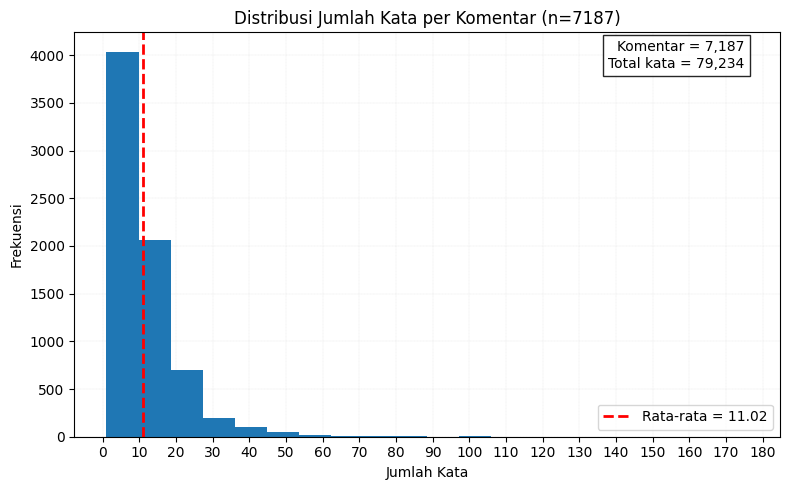

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# HITUNG JUMLAH KATA PER KOMENTAR
# =====================================================
df['jumlah_kata'] = df['text'].astype(str).str.split().str.len()

# =====================================================
# STATISTIK DESKRIPTIF
# =====================================================
jumlah_komentar = len(df)
total_kata = df['jumlah_kata'].sum()
rata2_kata = df['jumlah_kata'].mean()
median_kata = df['jumlah_kata'].median()
min_kata = df['jumlah_kata'].min()
max_kata = df['jumlah_kata'].max()
std_kata = df['jumlah_kata'].std()

print("="*50)
print("STATISTIK DESKRIPTIF JUMLAH KATA")
print("="*50)
print(f"Jumlah komentar            : {jumlah_komentar}")
print(f"Total kata                 : {total_kata}")
print(f"Rata-rata kata/komentar    : {rata2_kata:.2f}")
print(f"Median                     : {median_kata}")
print(f"Minimum                    : {min_kata}")
print(f"Maksimum                   : {max_kata}")
print(f"Standar deviasi            : {std_kata:.2f}")
print("="*50)

# Statistik lengkap
print("\nStatistik Lengkap:")
print(df['jumlah_kata'].describe())

# =====================================================
# HISTOGRAM DISTRIBUSI JUMLAH KATA
# =====================================================
plt.figure(figsize=(8,5))

plt.hist(df['jumlah_kata'], bins=20)

# Garis rata-rata
plt.axvline(
    rata2_kata,
    color='red',
    linestyle='dashed',
    linewidth=2,
    label=f'Rata-rata = {rata2_kata:.2f}'
)

# Grid
plt.grid(
    True,
    linestyle='--',
    linewidth=0.2,
    alpha=0.5
)

plt.gca().set_axisbelow(True)

# Interval sumbu x setiap 5 kata
plt.xticks(np.arange(0, max_kata + 10, 10))

# Informasi dataset pada grafik
plt.text(
    0.95,
    0.98,
    f'Komentar = {jumlah_komentar:,}\nTotal kata = {total_kata:,}',
    transform=plt.gca().transAxes,
    ha='right',
    va='top',
    bbox=dict(facecolor='white', alpha=0.85)
)

plt.title(f'Distribusi Jumlah Kata per Komentar (n={jumlah_komentar})')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_2017/3859488514.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['bulan'] = df['datetime'].dt.to_period('M').astype(str)


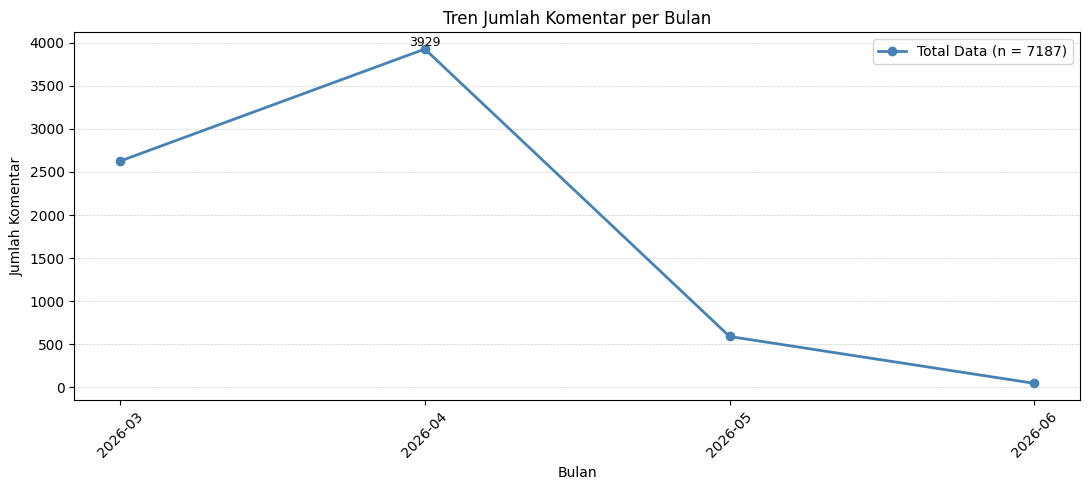

In [ ]:
# ==========================================
# Tren Jumlah Komentar per Bulan (RAW DATA)
# ==========================================
import matplotlib.pyplot as plt
import pandas as pd

# Convert datetime dari data mentah (sebelum preprocessing)
df['datetime'] = pd.to_datetime(df['createTimeISO'], errors='coerce', utc=True)

# Ambil periode bulan
df['bulan'] = df['datetime'].dt.to_period('M').astype(str)

# Hitung jumlah komentar per bulan
tweet_per_bulan = df.groupby('bulan').size().sort_index()

# Total data
total_tweet = len(df)

# ======================
# PLOT
# ======================
plt.figure(figsize=(11,5))
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.6)

plt.plot(tweet_per_bulan.index,
         tweet_per_bulan.values,
         linewidth=2,
         color='steelblue',
         marker='o')

# ======================
# LABEL PUNCAK
# ======================
max_bulan = tweet_per_bulan.idxmax()
plt.text(max_bulan,
         tweet_per_bulan[max_bulan],
         str(tweet_per_bulan[max_bulan]),
         ha='center',
         va='bottom',
         fontsize=9)

# ======================
# FINAL STYLE
# ======================
plt.title('Tren Jumlah Komentar per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=45)

plt.legend([f'Total Data (n = {total_tweet})'], loc='upper right')

plt.tight_layout()
plt.show()

# **Processing**

# 1. Cleaning

In [ ]:
import preprocessor as p
import re

def clean_text(text):
    # Menghapus URL, mention, hashtag
    p.set_options(p.OPT.URL, p.OPT.MENTION, p.OPT.HASHTAG)
    text = p.clean(str(text))

    # Ganti karakter unicode pemisah menjadi spasi
    text = re.sub(r'[–—…•]', ' ', text)

    # Hapus emoji dan karakter non-ascii
    text = text.encode('ascii', 'ignore').decode('ascii')

    # Hapus angka
    text = re.sub(r'\d+', ' ', text)

    # Hapus tanda baca dan karakter khusus
    text = re.sub(r'[^A-Za-z\s]', ' ', text)

    # Rapikan spasi
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['cleaning'] = df['text'].apply(clean_text)
display(df[['createTimeISO','text', 'cleaning']])

,createTimeISO,text,cleaning
0,2026-03-31T14:33:17.000Z,kenapa ga aturan nya tiap hari Jumat ASN pake ...,kenapa ga aturan nya tiap hari Jumat ASN pake ...
1,2026-03-31T15:03:27.000Z,WFH itu hari Rabu jadi ga dipake buat jalan2 🤣...,WFH itu hari Rabu jadi ga dipake buat jalan WF...
2,2026-03-31T14:58:06.000Z,Berhentiin aja mbg. Semua jadi naik,Berhentiin aja mbg Semua jadi naik
3,2026-03-31T14:12:05.000Z,"normal aja males kerja,apalagi WFH 😂",normal aja males kerja apalagi WFH
4,2026-03-31T15:07:05.000Z,“Kita pilih hari jumat kan karena eeeeee….” (B...,Kita pilih hari jumat kan karena eeeeee BIAR B...
...,...,...,...
7182,2026-04-01T00:18:26.000Z,wfh tp bmg ada trs ngambil bmg sm aja keluar.....,wfh tp bmg ada trs ngambil bmg sm aja keluar k...
7183,2026-04-01T00:25:58.000Z,ini mah pemerintah gengsi aja.. disaat negara ...,ini mah pemerintah gengsi aja disaat negara la...
7184,2026-03-31T15:52:27.000Z,Efisiensi bagi daerah pusat tidak mala menamba...,Efisiensi bagi daerah pusat tidak mala menamba...
7185,2026-04-01T03:05:58.000Z,jossss gandosss,jossss gandosss


# 2. Case Folding

In [ ]:
import pandas as pd

# Pra-pemrosesan teks (Case Folding)
def preprocess_text(text):
    # Case folding (mengonversi huruf menjadi huruf kecil)
    if pd.isna(text):
        return text
    return str(text).lower()

# Terapkan case folding pada kolom 'cleaning' di DataFrame 'df'
df['case_folding'] = df['cleaning'].apply(preprocess_text)

# Menampilkan hasil dari DataFrame 'df' setelah case folding
display(df[['createTimeISO','cleaning', 'case_folding']])

,createTimeISO,cleaning,case_folding
0,2026-03-31T14:33:17.000Z,kenapa ga aturan nya tiap hari Jumat ASN pake ...,kenapa ga aturan nya tiap hari jumat asn pake ...
1,2026-03-31T15:03:27.000Z,WFH itu hari Rabu jadi ga dipake buat jalan WF...,wfh itu hari rabu jadi ga dipake buat jalan wf...
2,2026-03-31T14:58:06.000Z,Berhentiin aja mbg Semua jadi naik,berhentiin aja mbg semua jadi naik
3,2026-03-31T14:12:05.000Z,normal aja males kerja apalagi WFH,normal aja males kerja apalagi wfh
4,2026-03-31T15:07:05.000Z,Kita pilih hari jumat kan karena eeeeee BIAR B...,kita pilih hari jumat kan karena eeeeee biar b...
...,...,...,...
7182,2026-04-01T00:18:26.000Z,wfh tp bmg ada trs ngambil bmg sm aja keluar k...,wfh tp bmg ada trs ngambil bmg sm aja keluar k...
7183,2026-04-01T00:25:58.000Z,ini mah pemerintah gengsi aja disaat negara la...,ini mah pemerintah gengsi aja disaat negara la...
7184,2026-03-31T15:52:27.000Z,Efisiensi bagi daerah pusat tidak mala menamba...,efisiensi bagi daerah pusat tidak mala menamba...
7185,2026-04-01T03:05:58.000Z,jossss gandosss,jossss gandosss


# 3. Normaliasi

In [ ]:
import pandas as pd
import re

# 1. Load Kamus Normalisasi
kamus_df = pd.read_excel("daftar_normalisasi1.xlsx")

#  Konversi menjadi dictionary: before → after
normalisasi_dict = dict(
    zip(
        kamus_df["before"].astype(str).str.lower(),
        kamus_df["after"].astype(str).str.lower()
    )
)

# 2. Normalisasi berbasis kamus
def normalize_by_dictionary(text):
    tokens = text.split()
    normalized = [normalisasi_dict.get(word, word) for word in tokens]
    return " ".join(normalized)

# 3. Fungsi normalisasi lengkap
def normalize_text(text):
    # Pastikan bertipe string
    text = str(text).lower()

    # ==========================================
    # A. Cleaning
    # ==========================================
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    # reduksi huruf berulang: "parahhh" → "parah"
    text = re.sub(r'(.)\1{2,}', r'\1', text)

    # Hapus filler satu huruf hasil reduksi
    text = re.sub(r'\b[euoa]\b', ' ', text)

    # ==========================================
    # B. Normalisasi Ekspresi Tertawa
    # Semua variasi menjadi "haha"
    # ==========================================
    laughter_patterns = [

        r'\bw[kw]{2,}[a-z]*\b',
        r'\b(?:ha){2,}[a-z]*\b',
        r'\b(?:he){2,}[a-z]*\b',
        r'\b(?:hi){2,}[a-z]*\b',
        r'\b(?:hu){2,}[a-z]*\b',
        r'\ba(?:ha){2,}[a-z]*\b',
        r'\bbwa(?:ha)+[a-z]*\b',
        r'\bwaka(?:ka)+[a-z]*\b',
        r'\bawo?k(?:wo?k)+[a-z]*\b',
        r'\bakw[kwa]*\b',
        r'\b(?:xi){2,}[a-z]*\b'

    ]

    for pattern in laughter_patterns:
        text = re.sub(pattern, " haha ", text)

    # ==========================================
    # C. Normalisasi Ekspresi Tangis
    # ==========================================
    crying_patterns = [

        r'\bhiks+\b',
        r'\bhik+s+\b',
        r'\bhuhu+\b',
        r'\bhu+hu+\b',
        r'\buhuk+\b'

    ]

    for pattern in crying_patterns:
        text = re.sub(pattern, " huhu ", text)

    # ==========================================
    # D. Normalisasi Berdasarkan Kamus
    # ==========================================
    text = normalize_by_dictionary(text)
    return text

    # ==========================================
    # E. Rapikan Spasi
    # ==========================================
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Terapkan Normalisasi
df["normalized_text"] = df["case_folding"].apply(normalize_text)

# Lihat hasil
display(df[["createTimeISO", "case_folding", "normalized_text"]])

,createTimeISO,case_folding,normalized_text
0,2026-03-31T14:33:17.000Z,kenapa ga aturan nya tiap hari jumat asn pake ...,kenapa tidak aturan nya tiap hari jumat asn pa...
1,2026-03-31T15:03:27.000Z,wfh itu hari rabu jadi ga dipake buat jalan wf...,wfh itu hari rabu jadi tidak dipakai buat jala...
2,2026-03-31T14:58:06.000Z,berhentiin aja mbg semua jadi naik,berhentikan saja mbg semua jadi naik
3,2026-03-31T14:12:05.000Z,normal aja males kerja apalagi wfh,normal saja malas kerja apalagi wfh
4,2026-03-31T15:07:05.000Z,kita pilih hari jumat kan karena eeeeee biar b...,kita pilih hari jumat kan karena biar bisa pan...
...,...,...,...
7182,2026-04-01T00:18:26.000Z,wfh tp bmg ada trs ngambil bmg sm aja keluar k...,wfh tetapi mbg ada terus mengambil mbg sama sa...
7183,2026-04-01T00:25:58.000Z,ini mah pemerintah gengsi aja disaat negara la...,ini mah pemerintah gengsi saja disaat negara l...
7184,2026-03-31T15:52:27.000Z,efisiensi bagi daerah pusat tidak mala menamba...,efisiensi bagi daerah pusat tidak malah menamb...
7185,2026-04-01T03:05:58.000Z,jossss gandosss,jos gandos


# 3. Tokenisasi

In [ ]:
!pip install nltk
!pip install langid

import nltk
from nltk.tokenize import word_tokenize
from nltk.tokenize import TweetTokenizer
import langid

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 61.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langid: filename=langid-1.1.6-py3-none-any.whl size=1941171 sha256=a980441e6579b074283cbcd493ab68fea984c908e815cd1f50a473feabef96f2
  Stored in directory: /root/.cache/pip/wheels/3c/bc/9d/266e27289b9019680d65d9b608c37bff1eff565b001c977ec5
Successfully built langid


In [ ]:
nltk.download('punkt', quiet=True)

True

In [ ]:
# Inisialisasi TweetTokenizer
tt = TweetTokenizer(strip_handles=False, reduce_len=True)

def safe_tokenize(text):
    if pd.isna(text):
        return []
    return tt.tokenize(str(text))

# Tokenisasi data
df['text'] = df['text'].fillna('').astype(str)
df['tokens'] = df['normalized_text'].apply(safe_tokenize)

# Cek hasil
display(df[["createTimeISO","normalized_text",'tokens']])

,createTimeISO,normalized_text,tokens
0,2026-03-31T14:33:17.000Z,kenapa tidak aturan nya tiap hari jumat asn pa...,"[kenapa, tidak, aturan, nya, tiap, hari, jumat..."
1,2026-03-31T15:03:27.000Z,wfh itu hari rabu jadi tidak dipakai buat jala...,"[wfh, itu, hari, rabu, jadi, tidak, dipakai, b..."
2,2026-03-31T14:58:06.000Z,berhentikan saja mbg semua jadi naik,"[berhentikan, saja, mbg, semua, jadi, naik]"
3,2026-03-31T14:12:05.000Z,normal saja malas kerja apalagi wfh,"[normal, saja, malas, kerja, apalagi, wfh]"
4,2026-03-31T15:07:05.000Z,kita pilih hari jumat kan karena biar bisa pan...,"[kita, pilih, hari, jumat, kan, karena, biar, ..."
...,...,...,...
7182,2026-04-01T00:18:26.000Z,wfh tetapi mbg ada terus mengambil mbg sama sa...,"[wfh, tetapi, mbg, ada, terus, mengambil, mbg,..."
7183,2026-04-01T00:25:58.000Z,ini mah pemerintah gengsi saja disaat negara l...,"[ini, mah, pemerintah, gengsi, saja, disaat, n..."
7184,2026-03-31T15:52:27.000Z,efisiensi bagi daerah pusat tidak malah menamb...,"[efisiensi, bagi, daerah, pusat, tidak, malah,..."
7185,2026-04-01T03:05:58.000Z,jos gandos,"[jos, gandos]"


# 4. Stopword Removal

In [ ]:
!pip install nltk
import nltk
from nltk.corpus import stopwords

# Download stopwords bahasa Indonesia
nltk.download('stopwords')
nltk.download('popular')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/cmudict.zip.
[nltk_data]    | Downloading package gazetteers to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gazetteers.zip.
[nltk_data]    | Downloading package genesis to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/genesis.zip.
[nltk_data]    | Downloading package gutenberg to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gutenberg.zip.
[nltk_data]    | Downloading package inaugural to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/inaugural.zip.
[nltk_data]    | Downloading package movie_reviews to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping corpora/movie_reviews.zip.
[nltk_data]    | Downloading package names to /root/nltk_data...
[nltk_data] 

True

In [ ]:
from nltk.corpus import stopwords

# =====================================
# Stopword bawaan NLTK
# =====================================
indonesian_stop = set(stopwords.words('indonesian')) # Convert to set for set operations

print("Jumlah stopword awal :", len(indonesian_stop))

# =====================================
# Kata yang dipertahankan
# (karena termasuk stopword NLTK tetapi
# penting untuk analisis sentimen)
# =====================================
kata_pertahankan = {

    # Negasi
    'tidak','tak','bukan',
    'jangan','belum','tanpa',

    # Intensitas
    'sangat','amat','sekali',
    'terlalu','lebih','kurang',
    'paling',

    # Sentimen
    'baik','jelas', 'masalah',
}

# =====================================
# Keluarkan kata tersebut dari stopword
# =====================================
indonesian_stop = indonesian_stop - kata_pertahankan

print("Jumlah stopword setelah modifikasi :", len(indonesian_stop))

# =====================================
# Tambahkan singkatan penting (placeholder jika belum ada)
# =====================================
singkatan_pertahankan = set() # Define singkatan_pertahankan to prevent NameError

# =====================================
# Fungsi Stopword Removal
# =====================================
def remove_stopwords(tokens):

    hasil = []

    for token in tokens:

        token = token.lower()

        # ----------------------------------
        # Pertahankan singkatan penting
        # ----------------------------------
        if token in singkatan_pertahankan:
            hasil.append(token)
            continue

        # ----------------------------------
        # Hapus token 1 huruf
        # ----------------------------------
        if len(token) == 1:
            continue

        # ----------------------------------
        # Hapus token 2 huruf
        # (kecuali singkatan penting)
        # ----------------------------------
        if len(token) == 2:
            continue

        # ----------------------------------
        # Hapus stopword
        # ----------------------------------
        if token in indonesian_stop:
            continue

        hasil.append(token)

    return hasil

# =====================================
# Terapkan
# =====================================
df["stop_tokens"] = df["tokens"].apply(remove_stopwords)

display(df[["createTimeISO","tokens","stop_tokens"]])

Jumlah stopword awal : 757
Jumlah stopword setelah modifikasi : 741


,createTimeISO,tokens,stop_tokens
0,2026-03-31T14:33:17.000Z,"[kenapa, tidak, aturan, nya, tiap, hari, jumat...","[tidak, aturan, nya, jumat, asn, pakai, sepeda..."
1,2026-03-31T15:03:27.000Z,"[wfh, itu, hari, rabu, jadi, tidak, dipakai, b...","[wfh, rabu, tidak, dipakai, jalan, wfh, jumat,..."
2,2026-03-31T14:58:06.000Z,"[berhentikan, saja, mbg, semua, jadi, naik]","[berhentikan, mbg]"
3,2026-03-31T14:12:05.000Z,"[normal, saja, malas, kerja, apalagi, wfh]","[normal, malas, kerja, wfh]"
4,2026-03-31T15:07:05.000Z,"[kita, pilih, hari, jumat, kan, karena, biar, ...","[pilih, jumat, biar, pekan, pekan, repot]"
...,...,...,...
7182,2026-04-01T00:18:26.000Z,"[wfh, tetapi, mbg, ada, terus, mengambil, mbg,...","[wfh, mbg, mengambil, mbg, wfh, kasih, pembata..."
7183,2026-04-01T00:25:58.000Z,"[ini, mah, pemerintah, gengsi, saja, disaat, n...","[mah, pemerintah, gengsi, disaat, negara, meng..."
7184,2026-03-31T15:52:27.000Z,"[efisiensi, bagi, daerah, pusat, tidak, malah,...","[efisiensi, daerah, pusat, tidak, menambah, be..."
7185,2026-04-01T03:05:58.000Z,"[jos, gandos]","[jos, gandos]"


# 5. Stemming

In [ ]:
!pip install Sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 10.1 MB/s eta 0:00:00


In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Buat stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Define exception words
exception_words = kata_pertahankan # Using words from stopword removal as exceptions for stemming

# Fungsi stemming
def apply_stemming(tokens):
    if not isinstance(tokens, list):
        return []

    hasil = []

    for token in tokens:
        if token.lower() in exception_words:
            hasil.append(token)
        else:
            hasil.append(stemmer.stem(token))

    return hasil

# Terapkan
df['stem_tokens'] = df['stop_tokens'].apply(apply_stemming)

# Hasil
display(df[['createTimeISO','stop_tokens', 'stem_tokens']])

,createTimeISO,stop_tokens,stem_tokens
0,2026-03-31T14:33:17.000Z,"[tidak, aturan, nya, jumat, asn, pakai, sepeda...","[tidak, atur, nya, jumat, asn, pakai, sepeda, ..."
1,2026-03-31T15:03:27.000Z,"[wfh, rabu, tidak, dipakai, jalan, wfh, jumat,...","[wfh, rabu, tidak, pakai, jalan, wfh, jumat, s..."
2,2026-03-31T14:58:06.000Z,"[berhentikan, mbg]","[henti, mbg]"
3,2026-03-31T14:12:05.000Z,"[normal, malas, kerja, wfh]","[normal, malas, kerja, wfh]"
4,2026-03-31T15:07:05.000Z,"[pilih, jumat, biar, pekan, pekan, repot]","[pilih, jumat, biar, pekan, pekan, repot]"
...,...,...,...
7182,2026-04-01T00:18:26.000Z,"[wfh, mbg, mengambil, mbg, wfh, kasih, pembata...","[wfh, mbg, ambil, mbg, wfh, kasih, batas, miny..."
7183,2026-04-01T00:25:58.000Z,"[mah, pemerintah, gengsi, disaat, negara, meng...","[mah, perintah, gengsi, saat, negara, umum, kr..."
7184,2026-03-31T15:52:27.000Z,"[efisiensi, daerah, pusat, tidak, menambah, be...","[efisiensi, daerah, pusat, tidak, tambah, beba..."
7185,2026-04-01T03:05:58.000Z,"[jos, gandos]","[jos, gandos]"


In [ ]:
# Menggabungkan kata stem
df['data_clean'] = df['stem_tokens'].apply(lambda x: ' '.join(x))
df['date_only'] = pd.to_datetime(df['createTimeISO']).dt.date
display(df[['date_only', 'stem_tokens', 'data_clean']])

,date_only,stem_tokens,data_clean
0,2026-03-31,"[tidak, atur, nya, jumat, asn, pakai, sepeda, ...",tidak atur nya jumat asn pakai sepeda lebih ba...
1,2026-03-31,"[wfh, rabu, tidak, pakai, jalan, wfh, jumat, s...",wfh rabu tidak pakai jalan wfh jumat sabtu min...
2,2026-03-31,"[henti, mbg]",henti mbg
3,2026-03-31,"[normal, malas, kerja, wfh]",normal malas kerja wfh
4,2026-03-31,"[pilih, jumat, biar, pekan, pekan, repot]",pilih jumat biar pekan pekan repot
...,...,...,...
7182,2026-04-01,"[wfh, mbg, ambil, mbg, wfh, kasih, batas, miny...",wfh mbg ambil mbg wfh kasih batas minyak bbm s...
7183,2026-04-01,"[mah, perintah, gengsi, saat, negara, umum, kr...",mah perintah gengsi saat negara umum krisis en...
7184,2026-03-31,"[efisiensi, daerah, pusat, tidak, tambah, beba...",efisiensi daerah pusat tidak tambah beban apbn...
7185,2026-04-01,"[jos, gandos]",jos gandos


# 6. Hapus Data Kosong dan Duplikat

In [ ]:
# Hapus data kosong
df = df.dropna(subset=['data_clean'])

# Hapus komentar yang hanya berisi spasi
df = df[df['data_clean'].str.strip() != '']

# Hapus komentar duplikat
df = df.drop_duplicates(subset=['data_clean'])

# Reset indeks
df = df.reset_index(drop=True)

display(df[['date_only', 'text', 'data_clean']])

,date_only,text,data_clean
0,2026-03-31,kenapa ga aturan nya tiap hari Jumat ASN pake ...,tidak atur nya jumat asn pakai sepeda lebih ba...
1,2026-03-31,WFH itu hari Rabu jadi ga dipake buat jalan2 🤣...,wfh rabu tidak pakai jalan wfh jumat sabtu min...
2,2026-03-31,Berhentiin aja mbg. Semua jadi naik,henti mbg
3,2026-03-31,"normal aja males kerja,apalagi WFH 😂",normal malas kerja wfh
4,2026-03-31,“Kita pilih hari jumat kan karena eeeeee….” (B...,pilih jumat biar pekan pekan repot
...,...,...,...
6395,2026-04-01,atur ajalah bapak² terhormat gimana baiknya ne...,atur hormat baik negara indonesia versi negara...
6396,2026-04-01,wfh tp bmg ada trs ngambil bmg sm aja keluar.....,wfh mbg ambil mbg wfh kasih batas minyak bbm s...
6397,2026-04-01,ini mah pemerintah gengsi aja.. disaat negara ...,mah perintah gengsi saat negara umum krisis en...
6398,2026-03-31,Efisiensi bagi daerah pusat tidak mala menamba...,efisiensi daerah pusat tidak tambah beban apbn...


# **Visualisasi Data**





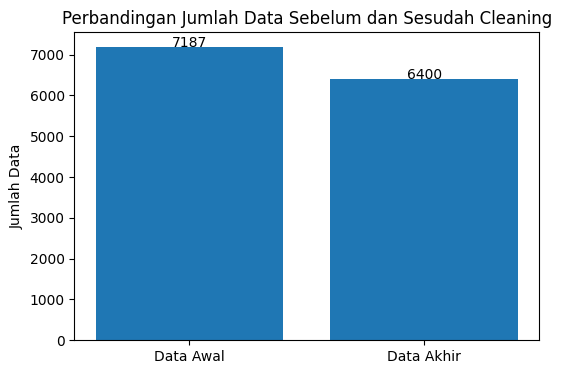

In [ ]:
# Total data sesudah dan sebelum processing

import matplotlib.pyplot as plt

kategori = ['Data Awal', 'Data Akhir']
# Use the initial count from the original df load and the current df length
initial_data_count = 7187 # Based on the original df loaded in cell GTV-hn0bZ27d
final_data_count = len(df) # Current df reflects the cleaned data

jumlah = [initial_data_count, final_data_count]

plt.figure(figsize=(6,4))
bars = plt.bar(kategori, jumlah)

plt.ylabel('Jumlah Data')
plt.title('Perbandingan Jumlah Data Sebelum dan Sesudah Cleaning')

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x()+bar.get_width()/2, y+5, int(y), ha='center')

plt.show()

/tmp/ipykernel_504/3859488514.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['bulan'] = df['datetime'].dt.to_period('M').astype(str)


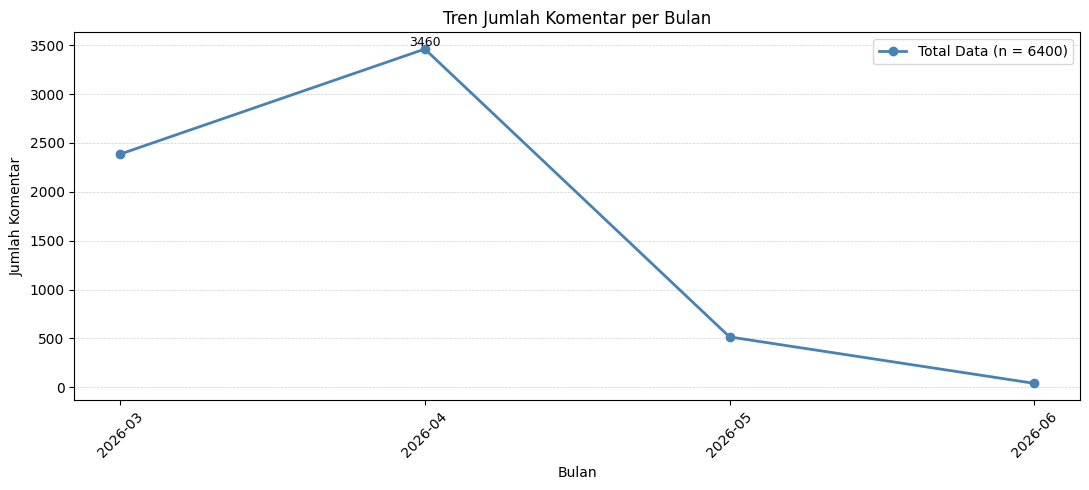

In [ ]:
# ==========================================
# Tren Jumlah Komentar per Bulan (RAW DATA)
# ==========================================
import matplotlib.pyplot as plt
import pandas as pd

# Convert datetime dari data mentah (sebelum preprocessing)
df['datetime'] = pd.to_datetime(df['createTimeISO'], errors='coerce', utc=True)

# Ambil periode bulan
df['bulan'] = df['datetime'].dt.to_period('M').astype(str)

# Hitung jumlah komentar per bulan
tweet_per_bulan = df.groupby('bulan').size().sort_index()

# Total data
total_tweet = len(df)

# ======================
# PLOT
# ======================
plt.figure(figsize=(11,5))
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.6)

plt.plot(tweet_per_bulan.index,
         tweet_per_bulan.values,
         linewidth=2,
         color='steelblue',
         marker='o')

# ======================
# LABEL PUNCAK
# ======================
max_bulan = tweet_per_bulan.idxmax()
plt.text(max_bulan,
         tweet_per_bulan[max_bulan],
         str(tweet_per_bulan[max_bulan]),
         ha='center',
         va='bottom',
         fontsize=9)

# ======================
# FINAL STYLE
# ======================
plt.title('Tren Jumlah Komentar per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=45)

plt.legend([f'Total Data (n = {total_tweet})'], loc='upper right')

plt.tight_layout()
plt.show()

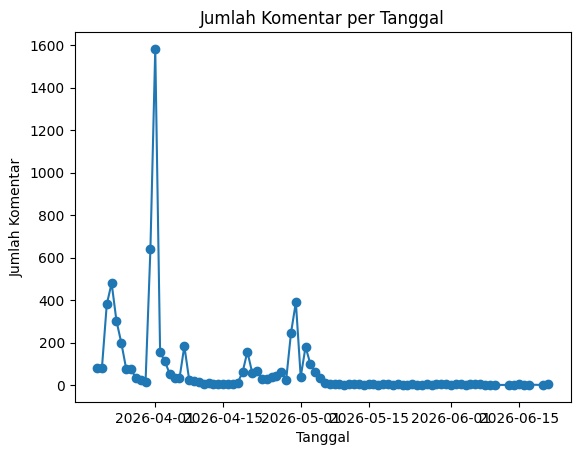

In [ ]:
df['tanggal'] = pd.to_datetime(
    df['createTimeISO']
).dt.date

df['tanggal'].value_counts().sort_index().plot(
    kind='line',
    marker='o'
)

plt.title('Jumlah Komentar per Tanggal')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Komentar')
plt.show()

# **Statistik Deskriptif Setelah processing**

STATISTIK DESKRIPTIF JUMLAH KATA
Jumlah komentar            : 6400
Total kata                 : 44520
Rata-rata kata/komentar    : 6.96
Median                     : 5.0
Minimum                    : 1
Maksimum                   : 92
Standar deviasi            : 5.89

Statistik Lengkap:
count    6400.000000
mean        6.956250
std         5.894973
min         1.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        92.000000
Name: jumlah_kata, dtype: float64


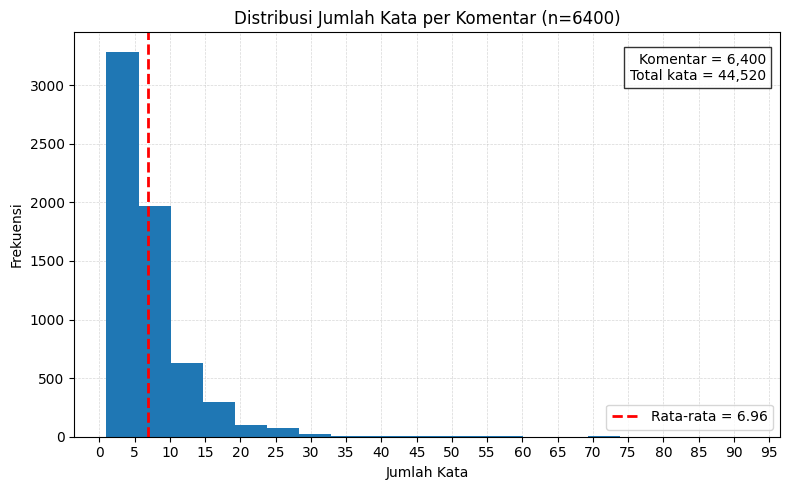

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# HITUNG JUMLAH KATA PER KOMENTAR
# =====================================================
df['jumlah_kata'] = df['data_clean'].astype(str).str.split().str.len()

# =====================================================
# STATISTIK DESKRIPTIF
# =====================================================
jumlah_komentar = len(df)
total_kata = df['jumlah_kata'].sum()
rata2_kata = df['jumlah_kata'].mean()
median_kata = df['jumlah_kata'].median()
min_kata = df['jumlah_kata'].min()
max_kata = df['jumlah_kata'].max()
std_kata = df['jumlah_kata'].std()

print("="*50)
print("STATISTIK DESKRIPTIF JUMLAH KATA")
print("="*50)
print(f"Jumlah komentar            : {jumlah_komentar}")
print(f"Total kata                 : {total_kata}")
print(f"Rata-rata kata/komentar    : {rata2_kata:.2f}")
print(f"Median                     : {median_kata}")
print(f"Minimum                    : {min_kata}")
print(f"Maksimum                   : {max_kata}")
print(f"Standar deviasi            : {std_kata:.2f}")
print("="*50)

# Statistik lengkap
print("\nStatistik Lengkap:")
print(df['jumlah_kata'].describe())

# =====================================================
# HISTOGRAM DISTRIBUSI JUMLAH KATA
# =====================================================
plt.figure(figsize=(8,5))

plt.hist(df['jumlah_kata'], bins=20)

# Garis rata-rata
plt.axvline(
    rata2_kata,
    color='red',
    linestyle='dashed',
    linewidth=2,
    label=f'Rata-rata = {rata2_kata:.2f}'
)

# Grid
plt.grid(
    True,
    linestyle='--',
    linewidth=0.5,
    alpha=0.5
)

plt.gca().set_axisbelow(True)

# Interval sumbu x setiap 5 kata
plt.xticks(np.arange(0, max_kata + 5, 5))

# Informasi dataset pada grafik
plt.text(
    0.98,
    0.95,
    f'Komentar = {jumlah_komentar:,}\nTotal kata = {total_kata:,}',
    transform=plt.gca().transAxes,
    ha='right',
    va='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.title(f'Distribusi Jumlah Kata per Komentar (n={jumlah_komentar})')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# KATA YANG SERING MUNCUL
from collections import Counter
import pandas as pd

all_words = ' '.join(df['data_clean']).split()

top_words = Counter(all_words).most_common(10)

print('='*10, '10 Kata yang Paling Sering Muncul', '='*10)

for kata, frekuensi in top_words:
    print(f'{kata}: {frekuensi}')

========== 10 Kata yang Paling Sering Muncul ==========
tidak: 2159
wfh: 836
kerja: 787
bbm: 662
nya: 653
liter: 639
libur: 614
jalan: 603
mbg: 599
atur: 568


#  **Visualisasi Kata yang sering muncul**

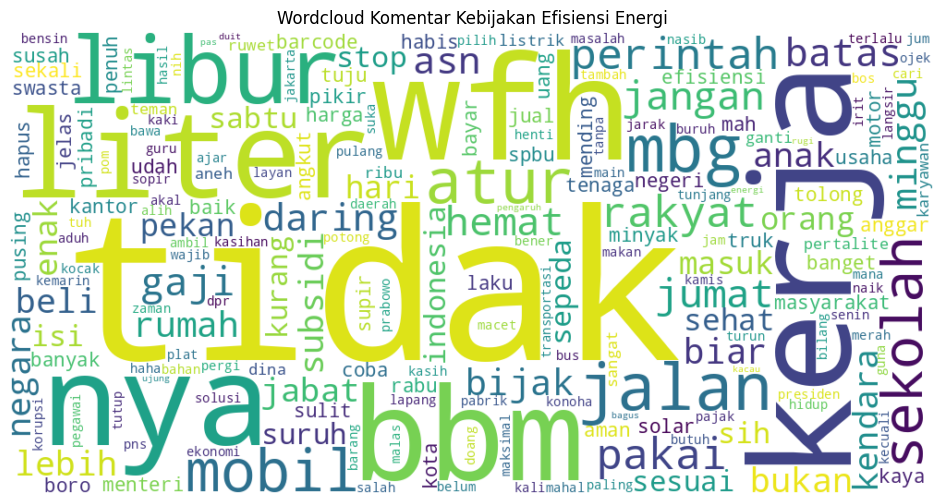

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Gabungkan seluruh komentar
text = " ".join(df['data_clean'].astype(str))

# Buat wordcloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    collocations=False
).generate(text)

# Tampilkan
plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Wordcloud Komentar Kebijakan Efisiensi Energi')
plt.show()

# **Pelabelan dengan VADER**

In [ ]:
!pip install vaderSentiment
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# =========================
# 1. Load leksikon InSet
# =========================
positif_url = "https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv"
negatif_url = "https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv"

# Membaca kamus
positif_lexicon = set(pd.read_csv(positif_url, sep='\t', header=None)[0])
negatif_lexicon = set(pd.read_csv(negatif_url, sep='\t', header=None)[0])

# =========================
# 2. Inisialisasi VADER
# =========================
# kelas utama pada VADER yang digunakan untuk menghitung skor sentimen suatu teks.
analyzer = SentimentIntensityAnalyzer()

# =========================
# 3. Update lexicon (kalibrasi -2 sampai +2)
# =========================
# membuat kamus kosong
lexicon = {}

for w in positif_lexicon:
    lexicon[w] = 2.0   # skor positif (konservatif)

for w in negatif_lexicon:
    lexicon[w] = -2.0  # skor negatif (konservatif)

# Kamus bawaan VADER diperbarui dengan kosakata bahasa Indonesia.
analyzer.lexicon.update(lexicon)

# =========================
# 4. Hitung skor sentimen
# =========================
def vader_score(text):
    scores = analyzer.polarity_scores(text)
    return scores['compound']

df['nilai_sentimen'] = df['data_clean'].apply(vader_score)

# =========================
# 5. Pelabelan sentimen
# =========================
def label_sentiment(score):
    if score >= 0.05:
        return 'positif'
    elif score <= -0.05:
        return 'negatif'
    else:
        return 'netral'

df['sentimen'] = df['nilai_sentimen'].apply(label_sentiment)

# =========================
# 6. Tampilkan hasil
# =========================
df[['data_clean', 'nilai_sentimen', 'sentimen']]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.8 MB/s eta 0:00:00


,data_clean,nilai_sentimen,sentimen
0,tidak atur nya jumat asn pakai sepeda lebih ba...,0.0000,netral
1,wfh rabu tidak pakai jalan wfh jumat sabtu min...,0.7184,positif
2,henti mbg,-0.4588,negatif
3,normal malas kerja wfh,0.4588,positif
4,pilih jumat biar pekan pekan repot,-0.7184,negatif
...,...,...,...
6395,atur hormat baik negara indonesia versi negara...,-0.4588,negatif
6396,wfh mbg ambil mbg wfh kasih batas minyak bbm s...,-0.8402,negatif
6397,mah perintah gengsi saat negara umum krisis en...,0.0000,netral
6398,efisiensi daerah pusat tidak tambah beban apbn...,-0.7184,negatif


In [ ]:
# Distribusi sentimen
sentimen_count = df['sentimen'].value_counts()

print(sentimen_count)

sentimen
negatif    4166
netral     1297
positif     937
Name: count, dtype: int64


# Visualisasi Distribusi Sentimen

          Jumlah  Persentase (%)
sentimen                        
negatif     4166           65.09
netral      1297           20.27
positif      937           14.64


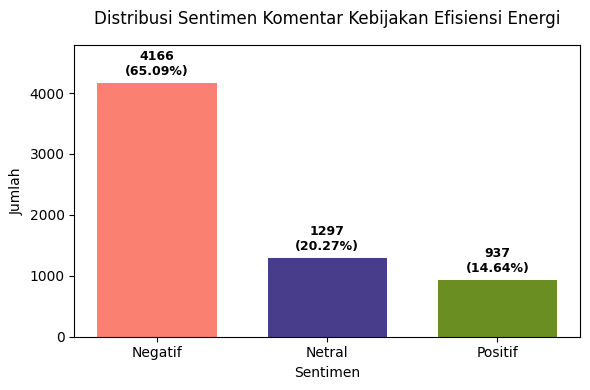

In [ ]:
# VISUALISASI DISTRIBUSI SENTIMEN SELURUH DATA

import pandas as pd
import matplotlib.pyplot as plt

# Hitung jumlah dan persentase
jumlah = df['sentimen'].value_counts()

# Urutan label
jumlah = jumlah.reindex(['negatif', 'netral', 'positif'])

persentase = (jumlah / jumlah.sum()) * 100

print(pd.DataFrame({
    'Jumlah': jumlah,
    'Persentase (%)': persentase.round(2)
}))

# Warna
colors = ['salmon', 'darkslateblue', 'olivedrab']

plt.figure(figsize=(6,4))

bars = plt.bar(
    jumlah.index.str.capitalize(),
    jumlah.values,
    color=colors,
    width=0.7
)

plt.xlabel('Sentimen')
plt.ylabel('Jumlah')
plt.title('Distribusi Sentimen Komentar Kebijakan Efisiensi Energi', pad=15)

# Beri ruang di atas batang agar tulisan tidak mentok
plt.ylim(0, jumlah.max() * 1.15)

# Menampilkan jumlah dan persentase
for bar, jml, prs in zip(bars, jumlah.values, persentase.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + jumlah.max()*0.02,
        f'{jml}\n({prs:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

# **pembobotan TF-IDF**

In [ ]:
!pip install scikit-learn pandas
from sklearn.feature_extraction.text import TfidfVectorizer
import re

In [ ]:
# ==========================================
# Inisialisasi TF-IDF
# ==========================================
tfidf_vectorizer = TfidfVectorizer()

# Transformasi data
tfidf_matrix_full = tfidf_vectorizer.fit_transform(df['data_clean'])

# Ambil nama fitur (URUTAN DEFAULT)
feature_names = tfidf_vectorizer.get_feature_names_out()

# ==========================================
# 1. TAMPILAN DEFAULT (sesuai TF-IDF bawaan)
# ==========================================
tfidf_df_default = pd.DataFrame(
    tfidf_matrix_full.toarray(),
    columns=feature_names
)

# Tambahkan kolom label (Y)
tfidf_df_default['sentimen'] = df['sentimen'].values

print('TAMPILAN DEFAULT (10 DATA AWAL & 10 DATA AKHIR)')

tfidf_default_preview = pd.concat([
    tfidf_df_default.head(10),
    tfidf_df_default.tail(10)
])

display(tfidf_default_preview)


# ==========================================
# 2. URUT BERDASARKAN TOTAL KONTRIBUSI TF-IDF
# ==========================================

# Hitung total bobot tiap fitur
tfidf_sum = np.array(tfidf_matrix_full.sum(axis=0)).flatten()

# DataFrame feature importance
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'total_tfidf': tfidf_sum
}).sort_values(by='total_tfidf', ascending=False)

# Susun ulang kolom berdasarkan kontribusi
tfidf_df_sorted = tfidf_df_default[
    list(feature_importance['feature'])
]

print('URUT BERDASARKAN TOTAL KONTRIBUSI TF-IDF (10 DATA AWAL & 10 DATA AKHIR)')

tfidf_sorted_preview = pd.concat([
    tfidf_df_sorted.head(10),
    tfidf_df_sorted.tail(10)
])

display(tfidf_sorted_preview)

TAMPILAN DEFAULT (10 DATA AWAL & 10 DATA AKHIR)


,abadi,abdi,absen,absensi,absurd,acak,acara,aceh,across,acu,...,yudhi,yuk,zaitun,zaman,zenix,zolim,zonasi,zonk,zoom,sentimen
0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,netral
1,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,positif
2,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,negatif
3,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,positif
4,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,negatif
5,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,netral
6,0.0,0.0,0.575123,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,negatif
7,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,negatif
8,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,negatif
9,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,negatif


URUT BERDASARKAN TOTAL KONTRIBUSI TF-IDF (10 DATA AWAL & 10 DATA AKHIR)


,tidak,wfh,kerja,mbg,liter,libur,atur,jalan,bbm,nya,...,batalin,rantau,sok,koreksi,panggul,cenderung,caf,krusial,counter,gubernur
0,0.124331,0.171665,0.000000,0.000000,0.000000,0.190998,0.192597,0.385411,0.000000,0.187440,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.152925,0.422290,0.000000,0.000000,0.000000,0.469847,0.000000,0.237024,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.000000,0.000000,0.543418,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000000,0.305471,0.321227,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.000000,0.309979,0.000000,0.000000,0.000000,0.000000,0.000000,0.695943,0.332266,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.280894,0.000000,0.283405,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.058527,0.000000,0.254928,0.000000,0.000000,0.000000,0.000000,0.090713,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.000000,0.288508,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# **Pembagian Data**

# **90:10**

In [ ]:
# ==========================================================
# PEMBAGIAN DATA 90:10
# RANDOM STATE = 42
# ==========================================================

import pandas as pd
from sklearn.model_selection import train_test_split



# Membagi data menjadi data latih dan data uji
X_train_9010_42, X_test_9010_42, y_train_9010_42, y_test_9010_42 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.10,
    random_state=42,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_9010_42 = tfidf_vectorizer.transform(X_train_9010_42)
X_test_tfidf_9010_42 = tfidf_vectorizer.transform(X_test_9010_42)

print("="*70)
print("PEMBAGIAN DATA RASIO 90:10 | RANDOM STATE = 42")
print("="*70)

print("Jumlah data latih :", len(X_train_9010_42))
print("Jumlah data uji   :", len(X_test_9010_42))
print("Jumlah fitur TF-IDF :", X_train_tfidf_9010_42.shape[1])

# Distribusi sentimen
distribusi_9010_42 = pd.DataFrame({
    "Training": y_train_9010_42.value_counts().reindex(
        ['negatif','netral','positif']
    ),
    "Testing": y_test_9010_42.value_counts().reindex(
        ['negatif','netral','positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN ====")
display(distribusi_9010_42)

# DataFrame Training
train_9010_42 = pd.DataFrame({
    "Komentar": X_train_9010_42,
    "Sentimen": y_train_9010_42
})

print("\n===== DATA TRAINING ====")
display(train_9010_42)

# DataFrame Testing
test_9010_42 = pd.DataFrame({
    "Komentar": X_test_9010_42,
    "Sentimen": y_test_9010_42
})

print("\n===== DATA TESTING ====")
display(test_9010_42)

PEMBAGIAN DATA RASIO 90:10 | RANDOM STATE = 42
Jumlah data latih : 5760
Jumlah data uji   : 640
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN ====


,Training,Testing
sentimen,,
negatif,3750,416
netral,1167,130
positif,843,94



===== DATA TRAINING ====


,Komentar,Sentimen
3492,kirain jabat otak pintar yah usaha milik pabri...,negatif
48,keluar bbm lebih pilih sekolah antre anak ajar...,negatif
5724,lebih harga air mineral airlangga hartarto ora...,positif
2661,wfh kerja rumah jalan segar enak libur,positif
1606,bilang ken libur udah jelas tidak wfh udah anggur,negatif
...,...,...
876,sekolah tidak daring setup jumat,positif
2341,rakyat suruh efiensi jabat aduh maksa banget,negatif
763,untung sekali,negatif
3677,maksimal liter hari nih pakai mobil paling sek...,negatif



===== DATA TESTING ====


,Komentar,Sentimen
1721,wfh laksana nya perintah ketidakpercayaan laks...,netral
5862,suka kelen,negatif
1257,tolong anak sekolah jangan daring kacau daring,negatif
773,enak banget ngomong tidak kerja pecat tutup ti...,negatif
4659,kocak nih perintah tidak atur beli bensin lite...,negatif
...,...,...
5988,atur nya tidak jelas tai atur susah supir eksp...,negatif
1675,layan hotel restoran ajak tidak,negatif
3393,cabut alokasi mobil dinas,netral
4196,tidak akal nya perintah,negatif


In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 90:10
# RANDOM STATE = 123
# ==========================================================

# Membagi data menjadi data latih dan data uji
X_train_9010_123, X_test_9010_123, y_train_9010_123, y_test_9010_123 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.10,
    random_state=123,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_9010_123 = tfidf_vectorizer.transform(X_train_9010_123)
X_test_tfidf_9010_123 = tfidf_vectorizer.transform(X_test_9010_123)

# Informasi pembagian data
print("="*70)
print("PEMBAGIAN DATA RASIO 90:10 | RANDOM STATE = 123")
print("="*70)

print("Jumlah data latih :", len(X_train_9010_123))
print("Jumlah data uji   :", len(X_test_9010_123))
print("Jumlah fitur TF-IDF :", X_train_tfidf_9010_123.shape[1])

# Distribusi sentimen
distribusi_9010_42 = pd.DataFrame({
    "Training": y_train_9010_123.value_counts().reindex(
        ['negatif','netral','positif']
    ),
    "Testing": y_test_9010_123.value_counts().reindex(
        ['negatif','netral','positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN =====")
display(distribusi_9010_42)

# DataFrame Training
train_9010_123 = pd.DataFrame({
    "Komentar": X_train_9010_123,
    "Sentimen": y_train_9010_123
})

print("\n===== DATA TRAINING =====")
display(train_9010_123)

# DataFrame Testing
test_9010_123 = pd.DataFrame({
    "Komentar": X_test_9010_123,
    "Sentimen": y_test_9010_123
})

print("\n===== DATA TESTING =====")
display(test_9010_123)



PEMBAGIAN DATA RASIO 90:10 | RANDOM STATE = 123
Jumlah data latih : 5760
Jumlah data uji   : 640
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN =====


,Training,Testing
sentimen,,
negatif,3750,416
netral,1167,130
positif,843,94



===== DATA TRAINING =====


,Komentar,Sentimen
2363,sekolah libur tidak tidak,netral
2409,mbg batas anggar negara jaga,negatif
774,cocok rumah kerja,positif
5971,perintah bedull,netral
5208,pertalite batas ribu ribu pateen,negatif
...,...,...
4843,atur nih,negatif
5096,amat kasih ajar hemat,negatif
4664,tolong warung pingir jalan jangan beli bbm gil...,negatif
6165,pangkas efisiensi jalan negeri jalan negeri am...,negatif



===== DATA TESTING =====


,Komentar,Sentimen
5163,tidak jelas arah perintah mobil truk trayek wo...,negatif
874,stop mbg alih urgensi didik sehat wfh tidak ef...,negatif
4929,truk ekspedisi liter jakarta,netral
6366,batas tunjang menteri dpr jabat nya,negatif
3637,konsumsi bbm setir wajar hari tidak kemarin de...,negatif
...,...,...
6215,kurang mbg,negatif
4063,jakarta surabaya,netral
457,opsi sepeda becak delman delman daerah kendara...,netral
5995,susah susah susah rezim,negatif


In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 90:10
# RANDOM STATE = 999
# ==========================================================

# Membagi data menjadi data latih dan data uji
X_train_9010_999, X_test_9010_999, y_train_9010_999, y_test_9010_999 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.10,
    random_state=999,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_9010_999 = tfidf_vectorizer.transform(X_train_9010_999)
X_test_tfidf_9010_999 = tfidf_vectorizer.transform(X_test_9010_999)

print("="*70)
print("PEMBAGIAN DATA RASIO 90:10 | RANDOM STATE = 999")
print("="*70)

print("Jumlah data latih :", len(X_train_9010_999))
print("Jumlah data uji   :", len(X_test_9010_999))
print("Jumlah fitur TF-IDF :", X_train_tfidf_9010_999.shape[1])

# Distribusi data

distribusi_9010_42 = pd.DataFrame({
    "Training": y_train_9010_42.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_9010_42.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN DATA  =====")
display(distribusi_9010_42)


# DataFrame Training
train_9010_999 = pd.DataFrame({
    "Komentar": X_train_9010_999,
    "Sentimen": y_train_9010_999
})

print("\n===== DATA TRAINING =====")
display(train_9010_999)

# DataFrame Testing
test_9010_999 = pd.DataFrame({
    "Komentar": X_test_9010_999,
    "Sentimen": y_test_9010_999
})

print("\n===== DATA TESTING =====")
display(test_9010_999)

PEMBAGIAN DATA RASIO 90:10 | RANDOM STATE = 999
Jumlah data latih : 5760
Jumlah data uji   : 640
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN DATA  =====


,Training,Testing
sentimen,,
negatif,3750,416
netral,1167,130
positif,843,94



===== DATA TRAINING =====


,Komentar,Sentimen
2734,enak banget buruh pabrik masuk sabtu sip kerja...,negatif
1351,pekan libur,positif
3833,solar tidak batas,negatif
1444,hemat guru mbg henti,negatif
4489,pertalite ketap,netral
...,...,...
5713,aman man masyarakat tidak liar,negatif
3860,sopir truk alamat inap jalan bijak,netral
5369,anggota dpr angkot,negatif
5559,antre macet parah distribusi butuh pokok hamba...,negatif



===== DATA TESTING =====


,Komentar,Sentimen
38,tolong jangan bilang anak sekolah ajar daring ...,negatif
4439,liter kendara tidak laku kendara truk plat hit...,negatif
930,aduh hemat bbm stop jual kendara,negatif
3196,jujur jujuran jabat konyol,negatif
111,bijak tidak bijak,negatif
...,...,...
4948,kalang kabut,negatif
469,hemat laku mobil minimal orang liburin jalan j...,negatif
4419,terlalu atur bijak kabinet susah masyarakat pa...,negatif
3720,suami supir lintas jawa sumatera gaji tim alok...,negatif


# 80:20

In [ ]:
# ==========================================================
# PEMBAGIAN DATA 80:20
# RANDOM STATE = 42
# ==========================================================

import pandas as pd
from sklearn.model_selection import train_test_split

# Membagi data menjadi data latih dan data uji
X_train_8020_42, X_test_8020_42, y_train_8020_42, y_test_8020_42 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.20,
    random_state=42,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_8020_42 = tfidf_vectorizer.transform(X_train_8020_42)
X_test_tfidf_8020_42 = tfidf_vectorizer.transform(X_test_8020_42)

print("="*70)
print("PEMBAGIAN DATA RASIO 80:20 | RANDOM STATE = 42")
print("="*70)

print("Jumlah data latih :", len(X_train_8020_42))
print("Jumlah data uji   :", len(X_test_8020_42))
print("Jumlah fitur TF-IDF :", X_train_tfidf_8020_42.shape[1])

# Distribusi data
distribusi_8020_42 = pd.DataFrame({
    "Training": y_train_8020_42.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_8020_42.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN DATA  =====")
display(distribusi_8020_42)

# DataFrame Training
train_8020_42 = pd.DataFrame({
    "Komentar": X_train_8020_42,
    "Sentimen": y_train_8020_42
})

print("\n===== DATA TRAINING =====")
display(train_8020_42)


# DataFrame Testing
test_8020_42 = pd.DataFrame({
    "Komentar": X_test_8020_42,
    "Sentimen": y_test_8020_42
})

print("\n===== DATA TRAINING =====")
display(test_8020_42)



PEMBAGIAN DATA RASIO 80:20 | RANDOM STATE = 42
Jumlah data latih : 5120
Jumlah data uji   : 1280
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN DATA  =====


,Training,Testing
sentimen,,
negatif,3333,833
netral,1038,259
positif,749,188



===== DATA TRAINING =====


,Komentar,Sentimen
1172,indonesia,netral
2702,turun pajak presiden pro rakyat,negatif
4620,kaltim samarinda pakai barcode batas pertalite,negatif
35,mbg lanjut,negatif
3323,anggota menteri dpr siap bus argamas gedung dp...,netral
...,...,...
3224,wfa lumayan anggar mbg minggu jelas perang man...,negatif
2341,rakyat suruh efiensi jabat aduh maksa banget,negatif
763,untung sekali,negatif
3677,maksimal liter hari nih pakai mobil paling sek...,negatif



===== DATA TRAINING =====


,Komentar,Sentimen
993,wfh kerja pakai komputer laptop teman teman,positif
4493,liter tidak mobil pribadi,netral
3082,tidak daring ibu daring,positif
2021,tolong pengaruh kurang paham butuh jelas perinci,negatif
1123,bumc tidak min,negatif
...,...,...
2828,jangan hak karyawan doang bos hak usaha langsu...,negatif
4248,tambah geopolitik tidak sesuai dampak indonesi...,negatif
4519,panik,negatif
5907,kota aduh kasihan bos,negatif


In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 80:20
# RANDOM STATE = 123
# ==========================================================

# Membagi data menjadi data latih dan data uji
X_train_8020_123, X_test_8020_123, y_train_8020_123, y_test_8020_123 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.20,
    random_state=123,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_8020_123 = tfidf_vectorizer.transform(X_train_8020_123)
X_test_tfidf_8020_123 = tfidf_vectorizer.transform(X_test_8020_123)

print("="*70)
print("PEMBAGIAN DATA RASIO 80:20 | RANDOM STATE = 123")
print("="*70)

print("Jumlah data latih :", len(X_train_8020_123))
print("Jumlah data uji   :", len(X_test_8020_123))
print("Jumlah fitur TF-IDF :", X_train_tfidf_8020_123.shape[1])

# Distribusi data
# Distribusi data
distribusi_8020_123 = pd.DataFrame({
    "Training": y_train_8020_123.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_8020_123.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN DATA  =====")
display(distribusi_8020_123)

# DataFrame Training
train_8020_123 = pd.DataFrame({
    "Komentar": X_train_8020_123,
    "Sentimen": y_train_8020_123
})

print("\n===== DATA TRAINING =====")
display(train_8020_123)

# DataFrame Testing
test_8020_123 = pd.DataFrame({
    "Komentar": X_test_8020_123,
    "Sentimen": y_test_8020_123
})

print("\n===== DATA TESTING =====")
display(test_8020_123)


PEMBAGIAN DATA RASIO 80:20 | RANDOM STATE = 123
Jumlah data latih : 5120
Jumlah data uji   : 1280
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN DATA  =====


,Training,Testing
sentimen,,
negatif,3333,833
netral,1038,259
positif,749,188



===== DATA TRAINING =====


,Komentar,Sentimen
5735,prabowo hebat,netral
2737,offgun,netral
6116,bangga presiden menteri pintar biar negara maju,positif
2664,orang senang jalan jalan keliling hemat bbm,negatif
3550,kerja mekanik bengkel mobil resmi,positif
...,...,...
4843,atur nih,negatif
5096,amat kasih ajar hemat,negatif
4664,tolong warung pingir jalan jangan beli bbm gil...,negatif
6165,pangkas efisiensi jalan negeri jalan negeri am...,negatif



===== DATA TESTING =====


,Komentar,Sentimen
948,heh jumat tanggal tanggal rabu,negatif
5407,amburadul era prabowo angel,negatif
1434,sticker stres stres,negatif
358,maaf tidak efektif wfh mending pagawai anjur b...,negatif
4058,banyak atur,negatif
...,...,...
784,malas gebrak konyol,negatif
3748,halah halah,negatif
4020,susah orang,negatif
3924,ibu ribu atur masalah minyak tidak mempan konoha,negatif


In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 80:20
# RANDOM STATE = 999
# ==========================================================

# Membagi data menjadi data latih dan data uji
X_train_8020_999, X_test_8020_999, y_train_8020_999, y_test_8020_999 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.20,
    random_state=999,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_8020_999 = tfidf_vectorizer.transform(X_train_8020_999)
X_test_tfidf_8020_999 = tfidf_vectorizer.transform(X_test_8020_999)

print("="*70)
print("PEMBAGIAN DATA RASIO 80:20 | RANDOM STATE = 999")
print("="*70)

print("Jumlah data latih :", len(X_train_8020_999))
print("Jumlah data uji   :", len(X_test_8020_999))
print("Jumlah fitur TF-IDF :", X_train_tfidf_8020_999.shape[1])


# Distribusi data
distribusi_8020_999 = pd.DataFrame({
    "Training": y_train_8020_999.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_8020_999.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN DATA  =====")
display(distribusi_8020_999)

# DataFrame Training
train_8020_999 = pd.DataFrame({
    "Komentar": X_train_8020_999,
    "Sentimen": y_train_8020_999
})

print("\n===== DATA TRAINING =====")
display(train_8020_999)

# DataFrame Testing
test_8020_999 = pd.DataFrame({
    "Komentar": X_test_8020_999,
    "Sentimen": y_test_8020_999
})


print("\n===== DATA TESTING =====")
display(test_8020_999)

PEMBAGIAN DATA RASIO 80:20 | RANDOM STATE = 999
Jumlah data latih : 5120
Jumlah data uji   : 1280
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN DATA  =====


,Training,Testing
sentimen,,
negatif,3333,833
netral,1038,259
positif,749,188



===== DATA TRAINING =====


,Komentar,Sentimen
3112,buruh hari lepas,negatif
730,mari liat jalur puncak pekan,negatif
4624,ekspedisi jawa sumatera pusing tidak sesuai se...,netral
3312,tidak tuju daring mbg stop anggar bbm,negatif
6157,jangan lupa laku efisiensi dprd dpr dpd anggar...,negatif
...,...,...
3443,miris mbg evaluasi gizi masalah minyak mbg jal...,negatif
5713,aman man masyarakat tidak liar,negatif
3523,madesu banget negara nyala,netral
5369,anggota dpr angkot,negatif



===== DATA TESTING =====


,Komentar,Sentimen
2978,libur ayo jogja,positif
3346,bodoh amat,positif
643,pret,netral
3994,segitu hancur negeri,negatif
1967,lalap lapor mana lapor mana kantor kalian tida...,positif
...,...,...
2160,anak asn lebaran piket libur masuk jaga,negatif
2738,ketemu guru langsung belum maksimal zaman covi...,positif
4260,mbg stop bukan rakyat atur,negatif
3509,tim operasional layan jasa wfh kecuali staf ka...,negatif


# **70:30**

In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 70:30
# RANDOM STATE = 42
# ==========================================================

import pandas as pd
from sklearn.model_selection import train_test_split

# Membagi data menjadi data latih dan data uji
X_train_7030_42, X_test_7030_42, y_train_7030_42, y_test_7030_42 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.30,
    random_state=42,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_7030_42 = tfidf_vectorizer.transform(X_train_7030_42)
X_test_tfidf_7030_42 = tfidf_vectorizer.transform(X_test_7030_42)

print("="*70)
print("PEMBAGIAN DATA RASIO 70:30 | RANDOM STATE = 42")
print("="*70)

print("Jumlah data latih :", len(X_train_7030_42))
print("Jumlah data uji   :", len(X_test_7030_42))
print("Jumlah fitur TF-IDF :", X_train_tfidf_7030_42.shape[1])

# Distribusi Data
distribusi_7030_42 = pd.DataFrame({
    "Training": y_train_7030_42.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_7030_42.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

print("\n===== DISTRIBUSI SENTIMEN DATA  =====")
display(distribusi_7030_42)

# DataFrame Training
train_7030_42 = pd.DataFrame({
    "Komentar": X_train_7030_42,
    "Sentimen": y_train_7030_42
})

print("\n===== DATA TRAINING =====")
display(train_7030_42)

# DataFrame Testing
test_7030_42 = pd.DataFrame({
    "Komentar": X_test_7030_42,
    "Sentimen": y_test_7030_42
})

print("\n===== DATA TESTING =====")
display(test_7030_42)

PEMBAGIAN DATA RASIO 70:30 | RANDOM STATE = 42
Jumlah data latih : 4480
Jumlah data uji   : 1920
Jumlah fitur TF-IDF : 3719

===== DISTRIBUSI SENTIMEN DATA  =====


,Training,Testing
sentimen,,
negatif,2916,1250
netral,908,389
positif,656,281



===== DATA TRAINING =====


,Komentar,Sentimen
5400,tolak bijak supir lintas liter barcode hari is...,negatif
1544,dengar senang karyawan gantung usaha dampak phk,negatif
3485,tolong ojek online suruh wfh,negatif
5831,mafia bebas beli solar bos,negatif
3560,kasih surat edar kirim usaha jangan koar doang,negatif
...,...,...
5529,bbm mana kosong,negatif
3224,wfa lumayan anggar mbg minggu jelas perang man...,negatif
2341,rakyat suruh efiensi jabat aduh maksa banget,negatif
763,untung sekali,negatif



===== DATA TESTING =====


,Komentar,Sentimen
468,biar lebih hemat bbm,negatif
2799,peh cek enak,negatif
290,pekan puncak macet,negatif
6147,liter bos orang enggan angkat tidak menteri,netral
4557,nasib travel pribadi,netral
...,...,...
6136,cek lapang butuh bbm mobil distribusi butuh pa...,netral
2456,bijak tidak data sembarang,negatif
3302,aduh mbg stop,negatif
3706,aneh liter pulang crbn surabaya,negatif


In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 70:30
# RANDOM STATE = 123
# ==========================================================

# Membagi data menjadi data latih dan data uji
X_train_7030_123, X_test_7030_123, y_train_7030_123, y_test_7030_123 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.30,
    random_state=123,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_7030_123 = tfidf_vectorizer.transform(X_train_7030_123)
X_test_tfidf_7030_123 = tfidf_vectorizer.transform(X_test_7030_123)

print("="*70)
print("PEMBAGIAN DATA RASIO 70:30 | RANDOM STATE = 123")
print("="*70)

print("Jumlah data latih :", len(X_train_7030_123))
print("Jumlah data uji   :", len(X_test_7030_123))
print("Jumlah fitur TF-IDF :", X_train_tfidf_7030_123.shape[1])

# Distribusi Data
distribusi_7030_123 = pd.DataFrame({
    "Training": y_train_7030_123.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_7030_123.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

# DataFrame Training
train_7030_123 = pd.DataFrame({
    "Komentar": X_train_7030_123,
    "Sentimen": y_train_7030_123
})

print("\n===== DATA TRAINING =====")
display(train_7030_123)

# DataFrame Testing
test_7030_123 = pd.DataFrame({
    "Komentar": X_test_7030_123,
    "Sentimen": y_test_7030_123
})

print("\n===== DATA TESTING =====")
display(test_7030_123)

PEMBAGIAN DATA RASIO 70:30 | RANDOM STATE = 123
Jumlah data latih : 4480
Jumlah data uji   : 1920
Jumlah fitur TF-IDF : 3719

===== DATA TRAINING =====


,Komentar,Sentimen
3458,buruk alami hidup warga konoha,negatif
5852,maksud kendara hari bulan,negatif
1633,sekolah daring mbh jalan ambil sekolah bohong ...,negatif
3564,efisiensi anggota dpr jangan mobil,negatif
1524,wfh jamin kerja tidak pakai jalan jalan pekan ...,negatif
...,...,...
4843,atur nih,negatif
5096,amat kasih ajar hemat,negatif
4664,tolong warung pingir jalan jangan beli bbm gil...,negatif
6165,pangkas efisiensi jalan negeri jalan negeri am...,negatif



===== DATA TESTING =====


,Komentar,Sentimen
5442,terlalu atur,negatif
1357,asn tenaga sehat guru tidak teman teman,netral
3704,lebih mbg bbm,positif
921,naa pusing akibat apbn tidak hitung valid,negatif
5618,perintah asal kendara niaga tempuh jalan perin...,negatif
...,...,...
5559,antre macet parah distribusi butuh pokok hamba...,negatif
4809,mobil guna pribadi non subsidi pertamax mobil ...,positif
3366,tidak kerja keluyur sih perintah,netral
6168,moga realisasi,netral


In [ ]:
from sklearn.model_selection import train_test_split

# ==========================================================
# PEMBAGIAN DATA 70:30
# RANDOM STATE = 999
# ==========================================================

# Membagi data menjadi data latih dan data uji
X_train_7030_999, X_test_7030_999, y_train_7030_999, y_test_7030_999 = train_test_split(
    df['data_clean'],
    df['sentimen'],
    test_size=0.30,
    random_state=999,
    stratify=df['sentimen']
)

# Transformasi TF-IDF
X_train_tfidf_7030_999 = tfidf_vectorizer.transform(X_train_7030_999)
X_test_tfidf_7030_999 = tfidf_vectorizer.transform(X_test_7030_999)

print("="*70)
print("PEMBAGIAN DATA RASIO 70:30 | RANDOM STATE = 999")
print("="*70)

print("Jumlah data latih :", len(X_train_7030_999))
print("Jumlah data uji   :", len(X_test_7030_999))
print("Jumlah fitur TF-IDF :", X_train_tfidf_7030_999.shape[1])

# Distribusi Data
distribusi_7030_999 = pd.DataFrame({
    "Training": y_train_7030_999.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    ),
    "Testing": y_test_7030_999.value_counts().reindex(
        ['negatif', 'netral', 'positif']
    )
})

# DataFrame Training
train_7030_999 = pd.DataFrame({
    "Komentar": X_train_7030_999,
    "Sentimen": y_train_7030_999
})

print("\n===== DATA TRAINING =====")
display(train_7030_999)

# DataFrame Testing
test_7030_999 = pd.DataFrame({
    "Komentar": X_test_7030_999,
    "Sentimen": y_test_7030_999
})

print("\n===== DATA TESTING =====")
display(test_7030_999)

PEMBAGIAN DATA RASIO 70:30 | RANDOM STATE = 999
Jumlah data latih : 4480
Jumlah data uji   : 1920
Jumlah fitur TF-IDF : 3719

===== DATA TRAINING =====


,Komentar,Sentimen
4094,mending jokowi,negatif
6332,tunjang jabat belum usik hemat gimmick,netral
628,senin kamis jam kerja tambah penuh jam kerja m...,positif
5688,olah minyak bumi mikirin perut tugas abdi masy...,negatif
1943,positif teman teman jalan asn lek,positif
...,...,...
3443,miris mbg evaluasi gizi masalah minyak mbg jal...,negatif
5713,aman man masyarakat tidak liar,negatif
1321,jumat wfh sabtu minggu libur segar tidak tuh,positif
5369,anggota dpr angkot,negatif



===== DATA TESTING =====


,Komentar,Sentimen
3612,belum tuju udah habis,negatif
399,ampun anak rontok rambut ajar rumah,negatif
3954,anjir perintah,negatif
4709,sticker salah buka tiktok malem,negatif
632,mah mending hemat bbm habis duluan bbm nya,negatif
...,...,...
2276,wfh efisiensi bbm anak sekolah sabtu libur ber...,netral
1402,tenaga medis,positif
6260,kantor rencana hajat tuh haha tolong cut acara...,negatif
4290,batas lapang tidak terap main,negatif


# **SVM**

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.decomposition import PCA

# **90:10**


# Random State 42

In [ ]:


# Model SVM
svm_9010_42 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_9010_42 = GridSearchCV(
    svm_9010_42,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)


grid_search_9010_42.fit(X_train_tfidf_9010_42, y_train_9010_42)

print("Best parameter :", grid_search_9010_42.best_params_)
print("Best Macro F1 :", grid_search_9010_42.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.8128985420292081


In [ ]:
hasil_tuning_9010_42 = pd.DataFrame(grid_search_9010_42.cv_results_)

hasil_tuning_9010_42 = hasil_tuning_9010_42[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_9010_42.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_9010_42.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.391514  0.010630        6
1  0.3       0.478150  0.009714        5
2  0.5       0.585308  0.026988        4
3  1.0       0.726860  0.015125        3
4  3.0       0.793246  0.006124        2
5  5.0       0.812899  0.006955        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "90:10"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_42, y_train_9010_42)

    support_indices = svm_model.support_
    y_sv = y_train_9010_42.iloc[support_indices] if hasattr(y_train_9010_42, "iloc") else y_train_9010_42[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_9010_42 == kelas1) | (y_train_9010_42 == kelas2)
        y_pair = y_train_9010_42[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 42,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_9010_42 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_9010_42)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,90:10,42,5,negatif vs netral,3750,1167,1168,1024,2192,-0.700568,"[tidak, libur, kerja, atur, jangan, mobil, jum...","[7.461578290870818, -5.214061480922041, -5.192..."
1,90:10,42,5,negatif vs positif,3750,843,1168,508,1676,0.515809,"[tidak, kerja, libur, sekolah, mobil, atur, he...","[5.570803284778599, -3.879543507873173, -3.856..."
2,90:10,42,5,netral vs positif,1167,843,1024,508,1532,1.228785,"[daring, tidak, kerja, libur, honor, atur, mob...","[-6.854114234959708, 6.485295989684083, -4.740..."


In [ ]:
# ==========================================================
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

def summarize_2d_for_display(arr, n_rows=5, n_cols=10):
    """Ringkas matriks 2D menjadi n_rows x n_cols untuk display"""
    n_total_rows, n_total_cols = arr.shape

    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []

    for r in row_indices:

        row = arr[r]

        if n_total_cols <= n_cols:
            summarized.append(row)

        else:
            summarized.append(
                np.concatenate([
                    row[:n_cols//2],
                    ['...'],
                    row[-n_cols//2:]
                ])
            )

    return np.array(summarized)

def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr

    return np.concatenate([arr[:n], ['...'], arr[-n:]])

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_9010_42 == kelas1) | (y_train_9010_42 == kelas2)

    X_pair = X_train_tfidf_9010_42[mask_pair.to_numpy()]
    y_pair = y_train_9010_42[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()
    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n"+"="*80+"\n")

=== Model Biner: negatif vs netral ===

α_i = ['-2.174489939171229' '-0.45934054751449005' '-1.7005146301822482'
 '-2.199604619019542' '-1.8836444129861116' '...' '2.069442296219533'
 '5.0' '5.0' '0.2994923919727906' '3.496277795931286']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.7006


=== Model Biner: negatif vs positif ===

α_i = ['-1.773285952933683' '-0.4839937211673556' '-0.30892669745912793'
 '-2.1334267551884816' '-0.05498315538163363' '...' '1.1661817669822545'
 '2.507444204402506' '1.221108626509954' '0.734555911755478'
 '2.702555045103677']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ..

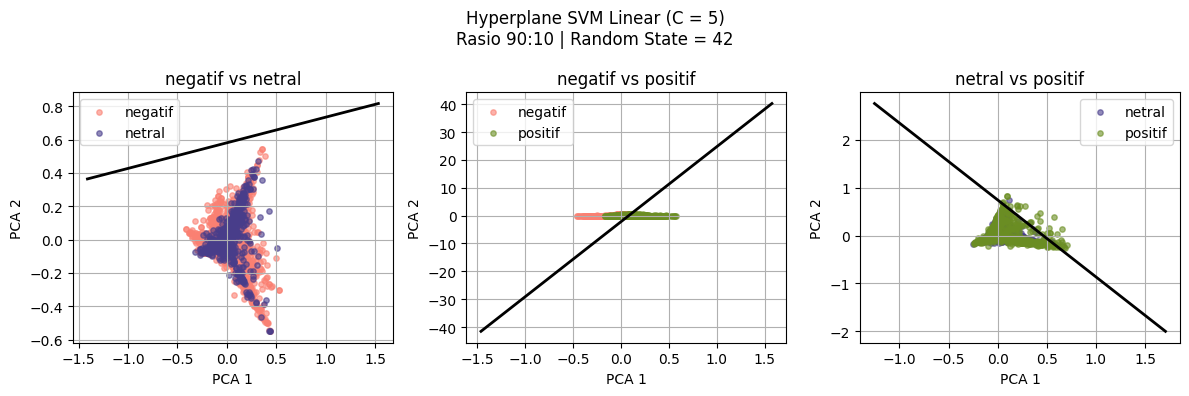

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

# Define the list of C values for this visualization specifically
C_val = [5]

# Loop untuk semua nilai C
for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_42, y_train_9010_42)

    fig, axes = plt.subplots(1, 3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_9010_42 == kelas1) | (y_train_9010_42 == kelas2)

        X_pair = X_train_tfidf_9010_42[mask_train.to_numpy()]
        y_pair = y_train_9010_42[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear (C = {C_val})\nRasio 90:10 | Random State = 42'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

C_val = [5]
hasil_evaluasi_9010_42 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_42, y_train_9010_42)

    y_pred = svm_model.predict(X_test_tfidf_9010_42)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (90:10) Random State = 42 untuk C = {C_val} ---")

    hasil_prediksi_svm_9010_42 = pd.DataFrame({
        'teks_tweet': X_test_9010_42,
        'label_aktual': y_test_9010_42,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_9010_42)

    accuracy = accuracy_score(y_test_9010_42, y_pred)
    precision = precision_score(y_test_9010_42, y_pred, average='macro')
    sensitivity = recall_score(y_test_9010_42, y_pred, average='macro')
    f1 = f1_score(y_test_9010_42, y_pred, average='macro')

    hasil_evaluasi_9010_42.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM DENGAN C = {C_val} | RASIO 90:10 | RANDOM STATE = 42 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test_9010_42, y_pred, labels=labels))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test_9010_42,
        y_pred,
        target_names=labels
    ))


--- Hasil Prediksi Klasifikasi SVM Data Testing (90:10) Random State = 42 untuk C = 5 ---
                                             teks_tweet label_aktual  \
1721  wfh laksana nya perintah ketidakpercayaan laks...       netral   
5862                                         suka kelen      negatif   
1257     tolong anak sekolah jangan daring kacau daring      negatif   
773   enak banget ngomong tidak kerja pecat tutup ti...      negatif   
4659  kocak nih perintah tidak atur beli bensin lite...      negatif   
...                                                 ...          ...   
5988  atur nya tidak jelas tai atur susah supir eksp...      negatif   
1675                    layan hotel restoran ajak tidak      negatif   
3393                          cabut alokasi mobil dinas       netral   
4196                            tidak akal nya perintah      negatif   
1044  gaji jabat mohon tinjau ulang dpr pimpin kepal...      negatif   

     label_prediksi  
1721         netral  


# Random state 123

In [ ]:
# Model SVM
svm_9010_123 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_9010_123 = GridSearchCV(
    svm_9010_123,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_9010_123.fit(X_train_tfidf_9010_123, y_train_9010_123)

print("Best parameter :", grid_search_9010_123.best_params_)
print("Best Macro F1 :", grid_search_9010_123.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.8066303399305659


In [ ]:
hasil_tuning_9010_123 = pd.DataFrame(grid_search_9010_123.cv_results_)

hasil_tuning_9010_123 = hasil_tuning_9010_123[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_9010_123.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_9010_123.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.392682  0.011462        6
1  0.3       0.472759  0.009722        5
2  0.5       0.581350  0.014948        4
3  1.0       0.715420  0.017639        3
4  3.0       0.791975  0.007540        2
5  5.0       0.806630  0.005287        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "90:10"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_123, y_train_9010_123)

    support_indices = svm_model.support_
    y_sv = y_train_9010_123.iloc[support_indices] if hasattr(y_train_9010_123, "iloc") else y_train_9010_123[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_9010_123 == kelas1) | (y_train_9010_123 == kelas2)
        y_pair = y_train_9010_123[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 123,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_9010_123 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_9010_123)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,90:10,123,5,negatif vs netral,3750,1167,1181,1020,2201,-0.665364,"[tidak, libur, kerja, atur, jumat, jangan, mob...","[7.621639678430057, -5.360254523890646, -5.172..."
1,90:10,123,5,negatif vs positif,3750,843,1181,522,1703,0.503846,"[tidak, sekolah, kerja, libur, mobil, jangan, ...","[5.403800049297413, -3.8341382065647096, -3.83..."
2,90:10,123,5,netral vs positif,1167,843,1020,522,1542,1.230399,"[tidak, daring, kerja, libur, honor, atur, mob...","[6.4695782185929716, -6.4626586024715165, -4.7..."


In [ ]:
# ==========================================================
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_9010_123 == kelas1) | (y_train_9010_123 == kelas2)

    X_pair = X_train_tfidf_9010_123[mask_pair.to_numpy()]
    y_pair = y_train_9010_123[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()
    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n"+"="*80+"\n")

=== Model Biner: negatif vs netral ===

α_i = ['-0.11630767709729885' '-1.3623830565200212' '-5.0' '-1.728152992972323'
 '-3.6558985646608306' '...' '5.0' '4.938355391006087' '5.0' '5.0'
 '0.40669575823634346']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.6654


=== Model Biner: negatif vs positif ===

α_i = ['-0.7855386735487073' '-0.21147788800964587' '-1.5324054546184103'
 '-1.8833153088599361' '-0.24709838634841214' '...' '1.1790353581491249'
 '0.8629154724872825' '4.00493730151879' '0.9361802806596884'
 '2.9094457615869134']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.

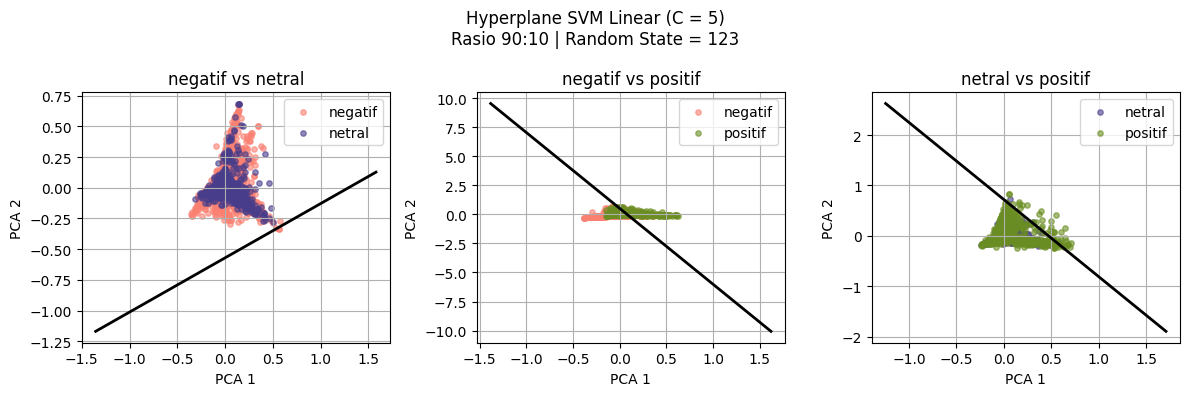

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

# Define the list of C values for this visualization specifically
C_val = [5]

# Loop untuk semua nilai C
for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_123, y_train_9010_123)

    fig, axes = plt.subplots(1, 3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_9010_123 == kelas1) | (y_train_9010_123 == kelas2)

        X_pair = X_train_tfidf_9010_123[mask_train.to_numpy()]
        y_pair = y_train_9010_123[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear (C = {C_val})\nRasio 90:10 | Random State = 123'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

C_val = [5]
hasil_evaluasi_9010_123 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_123, y_train_9010_123)

    y_pred = svm_model.predict(X_test_tfidf_9010_123)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (90:10) Random State = 123 untuk C = {C_val} ---")

    hasil_prediksi_svm_9010_123 = pd.DataFrame({
        'teks_tweet': X_test_9010_123,
        'label_aktual': y_test_9010_123,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_9010_123)

    accuracy = accuracy_score(y_test_9010_123, y_pred)
    precision = precision_score(y_test_9010_123, y_pred, average='macro')
    sensitivity = recall_score(y_test_9010_123, y_pred, average='macro')
    f1 = f1_score(y_test_9010_123, y_pred, average='macro')

    hasil_evaluasi_9010_123.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM DENGAN C = {C_val} | RASIO 90:10 | RANDOM STATE = 123 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test_9010_123, y_pred, labels=labels))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test_9010_123,
        y_pred,
        target_names=labels
    ))


--- Hasil Prediksi Klasifikasi SVM Data Testing (90:10) Random State = 123 untuk C = 5 ---
                                             teks_tweet label_aktual  \
5163  tidak jelas arah perintah mobil truk trayek wo...      negatif   
874   stop mbg alih urgensi didik sehat wfh tidak ef...      negatif   
4929                       truk ekspedisi liter jakarta       netral   
6366                batas tunjang menteri dpr jabat nya      negatif   
3637  konsumsi bbm setir wajar hari tidak kemarin de...      negatif   
...                                                 ...          ...   
6215                                         kurang mbg      negatif   
4063                                   jakarta surabaya       netral   
457   opsi sepeda becak delman delman daerah kendara...       netral   
5995                            susah susah susah rezim      negatif   
3441                  asah otak pulih udah kasih daring      negatif   

     label_prediksi  
5163        negatif  

# Random state 999

In [ ]:
# Model SVM
svm_9010_999 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_9010_999 = GridSearchCV(
    svm_9010_999,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_9010_999.fit(X_train_tfidf_9010_999, y_train_9010_999)

print("Best parameter :", grid_search_9010_999.best_params_)
print("Best Macro F1 :", grid_search_9010_999.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.812612056508953


In [ ]:
hasil_tuning_9010_999 = pd.DataFrame(grid_search_9010_999.cv_results_)

hasil_tuning_9010_999 = hasil_tuning_9010_999[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_9010_999.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_9010_999.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.380296  0.015012        6
1  0.3       0.471610  0.017096        5
2  0.5       0.576784  0.013788        4
3  1.0       0.722521  0.010318        3
4  3.0       0.793167  0.014209        2
5  5.0       0.812612  0.019963        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "90:10"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_999, y_train_9010_999)

    support_indices = svm_model.support_
    y_sv = y_train_9010_999.iloc[support_indices] if hasattr(y_train_9010_999, "iloc") else y_train_9010_999[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_9010_999 == kelas1) | (y_train_9010_999 == kelas2)
        y_pair = y_train_9010_999[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 999,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_9010_999 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_9010_999)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,90:10,999,5,negatif vs netral,3750,1167,1182,1020,2202,-0.707700,"[tidak, libur, atur, kerja, batas, bijak, mobi...","[7.6608025236220385, -5.335265202632769, 5.260..."
1,90:10,999,5,negatif vs positif,3750,843,1182,530,1712,0.502816,"[tidak, libur, atur, kerja, mobil, bijak, seko...","[5.213459591589292, -3.7862294162485064, 3.735..."
2,90:10,999,5,netral vs positif,1167,843,1020,530,1550,1.230801,"[tidak, daring, kerja, libur, batas, bayar, at...","[6.471012940259797, -6.200152387781491, -4.737..."


In [ ]:
# ==========================================================
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_9010_999 == kelas1) | (y_train_9010_999 == kelas2)

    X_pair = X_train_tfidf_9010_999[mask_pair.to_numpy()]
    y_pair = y_train_9010_999[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()
    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n"+"="*80+"\n")

=== Model Biner: negatif vs netral ===

α_i = ['-3.126930260566077' '-0.8579327578392983' '-1.1250942699064161'
 '-0.12733849170871123' '-1.7798961704468506' '...' '5.0' '5.0' '5.0'
 '1.6251751292480026' '2.9612982224713473']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.7077


=== Model Biner: negatif vs positif ===

α_i = ['-0.22234777020396415' '-0.4387445855972626' '-3.1357363709399375'
 '-1.2080467707892548' '-1.1020632621470143' '...' '4.4696072424761555'
 '2.044396378166139' '2.617008690204486' '2.2865809795837966'
 '1.532769614738115']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0

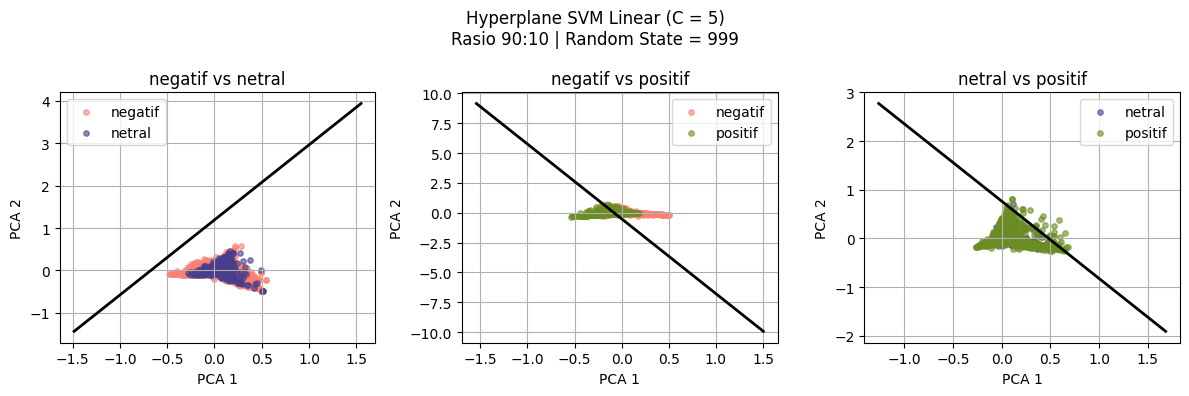

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import numpy as np

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

# Define the list of C values for this visualization specifically
C_val = [5]

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

# Loop untuk semua nilai C
for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_999, y_train_9010_999)

    fig, axes = plt.subplots(1, 3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_9010_999 == kelas1) | (y_train_9010_999 == kelas2)

        X_pair = X_train_tfidf_9010_999[mask_train.to_numpy()]
        y_pair = y_train_9010_999[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear (C = {C_val})\nRasio 90:10 | Random State = 999'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

C_val = [5]
hasil_evaluasi_9010_999 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_9010_999, y_train_9010_999)

    y_pred = svm_model.predict(X_test_tfidf_9010_999)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (90:10) Random State = 999 untuk C = {C_val} ---")

    hasil_prediksi_svm_9010_999 = pd.DataFrame({
        'teks_tweet': X_test_9010_999,
        'label_aktual': y_test_9010_999,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_9010_999)

    accuracy = accuracy_score(y_test_9010_999, y_pred)
    precision = precision_score(y_test_9010_999, y_pred, average='macro')
    sensitivity = recall_score(y_test_9010_999, y_pred, average='macro')
    f1 = f1_score(y_test_9010_999, y_pred, average='macro')

    hasil_evaluasi_9010_999.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM DENGAN C = {C_val} | RASIO 90:10 | RANDOM STATE = 999 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test_9010_999, y_pred, labels=labels))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test_9010_999,
        y_pred,
        target_names=labels
    ))


--- Hasil Prediksi Klasifikasi SVM Data Testing (90:10) Random State = 999 untuk C = 5 ---
                                             teks_tweet label_aktual  \
38    tolong jangan bilang anak sekolah ajar daring ...      negatif   
4439  liter kendara tidak laku kendara truk plat hit...      negatif   
930                    aduh hemat bbm stop jual kendara      negatif   
3196                         jujur jujuran jabat konyol      negatif   
111                                   bijak tidak bijak      negatif   
...                                                 ...          ...   
4948                                       kalang kabut      negatif   
469   hemat laku mobil minimal orang liburin jalan j...      negatif   
4419  terlalu atur bijak kabinet susah masyarakat pa...      negatif   
3720  suami supir lintas jawa sumatera gaji tim alok...      negatif   
6088                                    tidak cok liter      negatif   

     label_prediksi  
38          negatif  

# **80:20**

# Random state = 42

In [ ]:
# MELIHAT C TERBAIK
# Model SVM
svm_8020_42 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_8020_42 = GridSearchCV(
    svm_8020_42,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_8020_42.fit(X_train_tfidf_8020_42, y_train_8020_42)

print("Best parameter :", grid_search_8020_42.best_params_)
print("Best Macro F1 :", grid_search_8020_42.best_score_)


Best parameter : {'C': 5}
Best Macro F1 : 0.8005513944243112


In [ ]:
# Hasil Turning parameter
hasil_tuning_8020_42 = pd.DataFrame(grid_search_8020_42.cv_results_)

hasil_tuning_8020_42 = hasil_tuning_8020_42[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_8020_42.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_8020_42.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.373546  0.021238        6
1  0.3       0.467642  0.021141        5
2  0.5       0.562543  0.017957        4
3  1.0       0.715329  0.010256        3
4  3.0       0.786664  0.010001        2
5  5.0       0.800551  0.006557        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "80:20"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_42, y_train_8020_42)

    support_indices = svm_model.support_
    y_sv = y_train_8020_42.iloc[support_indices] if hasattr(y_train_8020_42, "iloc") else y_train_8020_42[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_8020_42 == kelas1) | (y_train_8020_42 == kelas2)
        y_pair = y_train_8020_42[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 42,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_8020_42 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_8020_42)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,80:20,42,5,negatif vs netral,3333,1038,1072,912,1984,-0.667800,"[tidak, jangan, libur, kerja, atur, batas, mob...","[7.147201590228704, 5.174812731944545, -5.0485..."
1,80:20,42,5,negatif vs positif,3333,749,1072,470,1542,0.510735,"[tidak, kerja, mobil, sekolah, libur, batas, a...","[5.45748722158196, -3.854299146137784, -3.8358..."
2,80:20,42,5,netral vs positif,1038,749,912,470,1382,1.200139,"[daring, tidak, kerja, libur, honor, atur, mob...","[-6.33095568081532, 6.165690423843799, -4.4894..."


In [ ]:
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

def summarize_2d_for_display(arr, n_rows=5, n_cols=10):
    """Ringkas matriks 2D menjadi n_rows x n_cols untuk display"""
    n_total_rows, n_total_cols = arr.shape

    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []
    for r in row_indices:
        row = arr[r]
        if n_total_cols <= n_cols:
            summarized.append(row)
        else:
            summarized.append(np.concatenate([row[:n_cols//2], ['...'], row[-n_cols//2:]]))
    return np.array(summarized)

def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr
    return np.concatenate([arr[:n], ['...'], arr[-n:]])

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_8020_42 == kelas1) | (y_train_8020_42 == kelas2)

    X_pair = X_train_tfidf_8020_42[mask_pair.to_numpy()]
    y_pair = y_train_8020_42[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)

    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")
    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)
    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n" + "="*80 + "\n")

=== Model Biner: negatif vs netral ===

α_i = ['-0.925032246471104' '-5.0' '-0.5964974142738922' '-0.6374699342891175'
 '-5.0' '...' '2.5251801239035347' '5.0' '5.0' '0.07822725335970211'
 '2.0840110288990985']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.6678


=== Model Biner: negatif vs positif ===

α_i = ['-1.5120754779133045' '-2.0615070590418956' '-0.26089909682442697'
 '-2.122319948346275' '-0.25961024200046795' '...' '4.263163108345966'
 '2.7504586534599467' '1.0251404172895429' '5.0' '5.0']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0

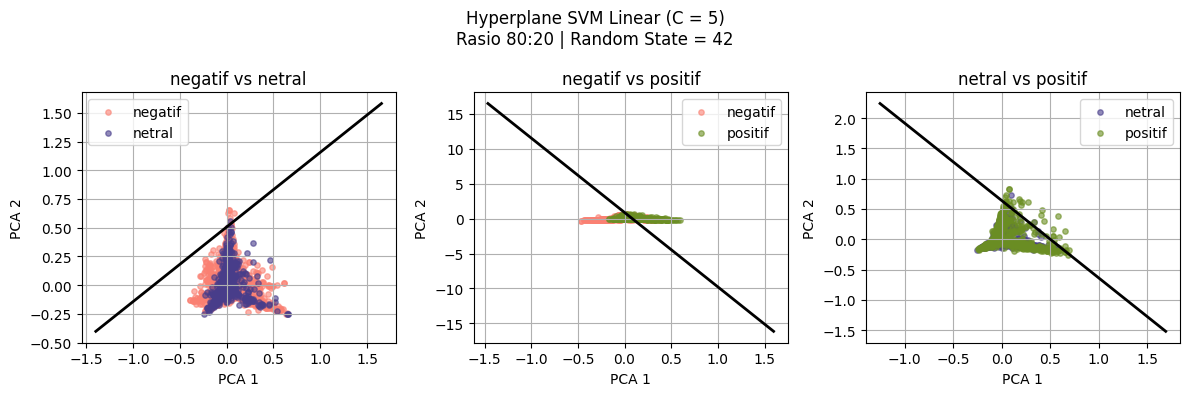

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

# Define the list of C values for this visualization specifically
C_val = [5]

# Loop untuk semua nilai C
for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_42, y_train_8020_42)

    fig, axes = plt.subplots(1, 3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_8020_42 == kelas1) | (y_train_8020_42 == kelas2)

        X_pair = X_train_tfidf_8020_42[mask_train.to_numpy()]
        y_pair = y_train_8020_42[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear (C = {C_val})\nRasio 80:20 | Random State = 42'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI SVM
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

C_val = [5]
hasil_evaluasi_8020_42 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_42, y_train_8020_42)

    y_pred = svm_model.predict(X_test_tfidf_8020_42)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (80:20) Random State = 42 untuk C = {C_val} ---")

    hasil_prediksi_svm_8020_42 = pd.DataFrame({
        'teks_tweet': X_test_8020_42,
        'label_aktual': y_test_8020_42,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_8020_42)

    accuracy = accuracy_score(y_test_8020_42, y_pred)
    precision = precision_score(y_test_8020_42, y_pred, average='macro')
    sensitivity = recall_score(y_test_8020_42, y_pred, average='macro')
    f1 = f1_score(y_test_8020_42, y_pred, average='macro')

    hasil_evaluasi_8020_42.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM C = {C_val} | Rasio 80:20 | Random State = 42 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("Confusion Matrix:\n",
          confusion_matrix(y_test_8020_42, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_8020_42,
                                y_pred,
                                target_names=labels))


--- Hasil Prediksi Klasifikasi SVM Data Testing (80:20) Random State = 42 untuk C = 5 ---
                                             teks_tweet label_aktual  \
993         wfh kerja pakai komputer laptop teman teman      positif   
4493                          liter tidak mobil pribadi       netral   
3082                            tidak daring ibu daring      positif   
2021   tolong pengaruh kurang paham butuh jelas perinci      negatif   
1123                                     bumc tidak min      negatif   
...                                                 ...          ...   
2828  jangan hak karyawan doang bos hak usaha langsu...      negatif   
4248  tambah geopolitik tidak sesuai dampak indonesi...      negatif   
4519                                              panik      negatif   
5907                              kota aduh kasihan bos      negatif   
4192                                     sesal milihnya      negatif   

     label_prediksi  
993          netral  


# Random State 123

In [ ]:
# Model SVM
svm_8020_123 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_8020_123 = GridSearchCV(
    svm_8020_123,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_8020_123.fit(X_train_tfidf_8020_123, y_train_8020_123)

print("Best parameter :", grid_search_8020_123.best_params_)
print("Best Macro F1 :", grid_search_8020_123.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.8021650785828387


In [ ]:
hasil_tuning_8020_123 = pd.DataFrame(grid_search_8020_123.cv_results_)

hasil_tuning_8020_123 = hasil_tuning_8020_123[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_8020_123.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_8020_123.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.384556  0.009084        6
1  0.3       0.461795  0.005879        5
2  0.5       0.562019  0.005380        4
3  1.0       0.703053  0.010887        3
4  3.0       0.792077  0.012134        2
5  5.0       0.802165  0.015475        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "80:20"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_123, y_train_8020_123)

    support_indices = svm_model.support_
    y_sv = y_train_8020_123.iloc[support_indices] if hasattr(y_train_8020_123, "iloc") else y_train_8020_123[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_8020_123 == kelas1) | (y_train_8020_123 == kelas2)
        y_pair = y_train_8020_123[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 123,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_8020_123 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_8020_123)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,80:20,123,5,negatif vs netral,3333,1038,1097,930,2027,-0.570887,"[tidak, libur, kerja, atur, mobil, batas, bija...","[7.470887570752993, -5.37534590495266, -4.8763..."
1,80:20,123,5,negatif vs positif,3333,749,1097,472,1569,0.515028,"[tidak, sekolah, libur, kerja, jangan, mobil, ...","[5.2402708735166605, -3.9605520560226637, -3.7..."
2,80:20,123,5,netral vs positif,1038,749,930,472,1402,1.175905,"[daring, tidak, kerja, libur, honor, atur, mob...","[-6.5758897060712185, 6.145652781190627, -4.51..."


In [ ]:
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

def summarize_2d_for_display(arr, n_rows=5, n_cols=10):
    n_total_rows, n_total_cols = arr.shape
    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []
    for r in row_indices:
        row = arr[r]
        if n_total_cols <= n_cols:
            summarized.append(row)
        else:
            summarized.append(np.concatenate([row[:n_cols//2], ['...'], row[-n_cols//2:]]))
    return np.array(summarized)

def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr
    return np.concatenate([arr[:n], ['...'], arr[-n:]])

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_8020_123 == kelas1) | (y_train_8020_123 == kelas2)

    X_pair = X_train_tfidf_8020_123[mask_pair.to_numpy()]
    y_pair = y_train_8020_123[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)

    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")
    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)
    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n" + "="*80 + "\n")

=== Model Biner: negatif vs netral ===

α_i = ['-1.8337718328665782' '-0.42082080674076966' '-1.7312164219971704'
 '-2.9853499225052325' '-1.6976620418613104' '...' '1.9372097462489861'
 '5.0' '5.0' '4.129467400125782' '1.2191447397552067']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.5709


=== Model Biner: negatif vs positif ===

α_i = ['-1.5765690675493178' '-2.4276488824492084' '-1.0129067071950275'
 '-0.1416389320597278' '-5.0' '...' '1.6156000056666733'
 '3.168159607120548' '0.34931709902830393' '0.24773378952055447'
 '1.763537954571391']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0

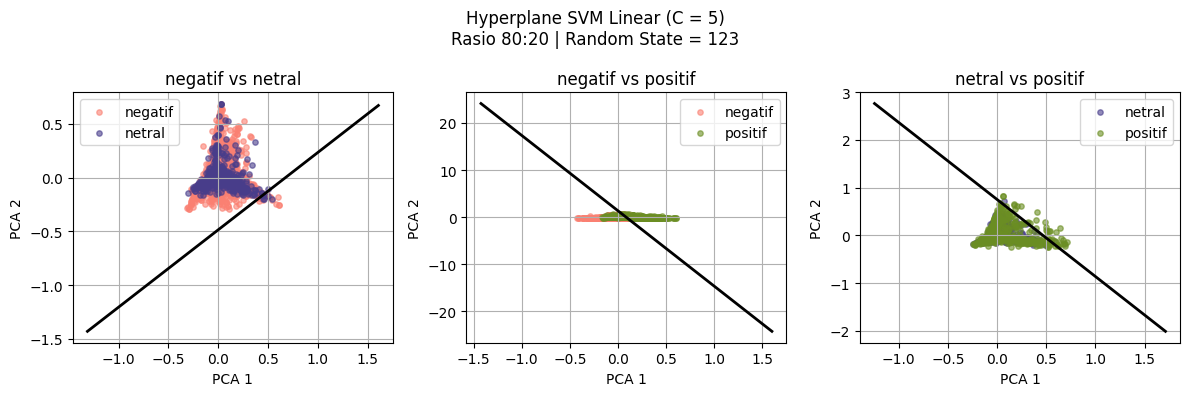

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {'negatif':'salmon',
          'netral':'darkslateblue',
          'positif':'olivedrab'}

# Define the list of C values for this visualization specifically
C_val = [5]

# Loop untuk semua nilai C
for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_123, y_train_8020_123)

    fig, axes = plt.subplots(1, 3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_8020_123 == kelas1) | (y_train_8020_123 == kelas2)

        X_pair = X_train_tfidf_8020_123[mask_train.to_numpy()]
        y_pair = y_train_8020_123[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear (C = {C_val})\nRasio 80:20 | Random State = 123'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI SVM
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

C_val = [5]
hasil_evaluasi_8020_123 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_123, y_train_8020_123)

    y_pred = svm_model.predict(X_test_tfidf_8020_123)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (80:20) Random State = 123 untuk C = {C_val} ---")

    hasil_prediksi_svm_8020_123 = pd.DataFrame({
        'teks_tweet': X_test_8020_123,
        'label_aktual': y_test_8020_123,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_8020_123)

    accuracy = accuracy_score(y_test_8020_123, y_pred)
    precision = precision_score(y_test_8020_123, y_pred, average='macro')
    sensitivity = recall_score(y_test_8020_123, y_pred, average='macro')
    f1 = f1_score(y_test_8020_123, y_pred, average='macro')

    hasil_evaluasi_8020_123.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM C = {C_val} | Rasio 80:20 | Random State = 123 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("Confusion Matrix:\n",
          confusion_matrix(y_test_8020_123, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_8020_123,
                                y_pred,
                                target_names=labels))


--- Hasil Prediksi Klasifikasi SVM Data Testing (80:20) Random State = 123 untuk C = 5 ---
                                             teks_tweet label_aktual  \
948                      heh jumat tanggal tanggal rabu      negatif   
5407                        amburadul era prabowo angel      negatif   
1434                                sticker stres stres      negatif   
358   maaf tidak efektif wfh mending pagawai anjur b...      negatif   
4058                                        banyak atur      negatif   
...                                                 ...          ...   
784                                 malas gebrak konyol      negatif   
3748                                        halah halah      negatif   
4020                                        susah orang      negatif   
3924   ibu ribu atur masalah minyak tidak mempan konoha      negatif   
1522         luccui perintah lucu wfh jumat pekan luccu       netral   

     label_prediksi  
948         negatif  

# Random State 999

In [ ]:
# Model SVM
svm_8020_999 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_8020_999 = GridSearchCV(
    svm_8020_999,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_8020_999.fit(X_train_tfidf_8020_999, y_train_8020_999)

print("Best parameter :", grid_search_8020_999.best_params_)
print("Best Macro F1 :", grid_search_8020_999.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.8035438095343853


In [ ]:
hasil_tuning_8020_999 = pd.DataFrame(grid_search_8020_999.cv_results_)

hasil_tuning_8020_999 = hasil_tuning_8020_999[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_8020_999.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_8020_999.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.362852  0.010042        6
1  0.3       0.464392  0.007435        5
2  0.5       0.552982  0.016690        4
3  1.0       0.703454  0.006710        3
4  3.0       0.786362  0.005752        2
5  5.0       0.803544  0.008889        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "80:20"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_999, y_train_8020_999)

    support_indices = svm_model.support_
    y_sv = y_train_8020_999.iloc[support_indices] if hasattr(y_train_8020_999, "iloc") else y_train_8020_999[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_8020_999 == kelas1) | (y_train_8020_999 == kelas2)
        y_pair = y_train_8020_999[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 999,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_8020_999 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_8020_999)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,80:20,999,5,negatif vs netral,3333,1038,1112,913,2025,-0.646282,"[tidak, libur, atur, kerja, bijak, hemat, bata...","[7.195560230008212, -5.317610012482433, 5.2460..."
1,80:20,999,5,negatif vs positif,3333,749,1112,494,1606,0.487574,"[tidak, kerja, bijak, mobil, libur, atur, hema...","[5.08820297750243, -3.6155307298990635, 3.6000..."
2,80:20,999,5,netral vs positif,1038,749,913,494,1407,1.163229,"[daring, tidak, kerja, batas, libur, bayar, mo...","[-6.492540464834456, 6.302658836237434, -4.449..."


In [ ]:
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

def summarize_2d_for_display(arr, n_rows=5, n_cols=10):
    n_total_rows, n_total_cols = arr.shape
    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []
    for r in row_indices:
        row = arr[r]
        if n_total_cols <= n_cols:
            summarized.append(row)
        else:
            summarized.append(np.concatenate([row[:n_cols//2], ['...'], row[-n_cols//2:]]))
    return np.array(summarized)

def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr
    return np.concatenate([arr[:n], ['...'], arr[-n:]])

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_8020_999 == kelas1) | (y_train_8020_999 == kelas2)

    X_pair = X_train_tfidf_8020_999[mask_pair.to_numpy()]
    y_pair = y_train_8020_999[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)

    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")
    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)
    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n" + "="*80 + "\n")

=== Model Biner: negatif vs netral ===

α_i = ['-5.0' '-5.0' '-4.187773369898536' '-5.0' '-1.5983773283914773' '...'
 '5.0' '0.3537805859140756' '0.2340882955284546' '5.0'
 '0.3948077977425395']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.6463


=== Model Biner: negatif vs positif ===

α_i = ['-1.2980091980962931' '-1.8528586795574418' '-0.39158802922372105'
 '-0.7133105778902264' '-0.05107585359684056' '...' '2.6564123616966264'
 '1.8177527738558121' '0.26566637481214395' '0.4329203770754294'
 '4.700317764241762']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 

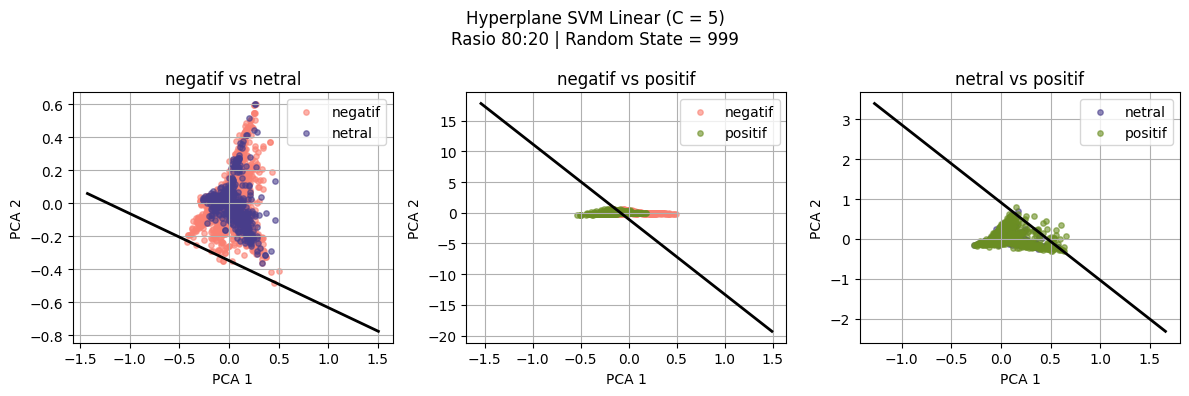

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {'negatif':'salmon',
          'netral':'darkslateblue',
          'positif':'olivedrab'}

# Define the list of C values for this visualization specifically
C_val = [5]

# Loop untuk semua nilai C
for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_999, y_train_8020_999)

    fig, axes = plt.subplots(1, 3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_8020_999 == kelas1) | (y_train_8020_999 == kelas2)

        X_pair = X_train_tfidf_8020_999[mask_train.to_numpy()]
        y_pair = y_train_8020_999[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear (C = {C_val})\nRasio 80:20 | Random State = 999'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI SVM
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

C_val = [5]
hasil_evaluasi_8020_999 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_8020_999, y_train_8020_999)

    y_pred = svm_model.predict(X_test_tfidf_8020_999)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (80:20) Random State = 999 untuk C = {C_val} ---")

    hasil_prediksi_svm_8020_999 = pd.DataFrame({
        'teks_tweet': X_test_8020_999,
        'label_aktual': y_test_8020_999,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_8020_999)

    accuracy = accuracy_score(y_test_8020_999, y_pred)
    precision = precision_score(y_test_8020_999, y_pred, average='macro')
    sensitivity = recall_score(y_test_8020_999, y_pred, average='macro')
    f1 = f1_score(y_test_8020_999, y_pred, average='macro')

    hasil_evaluasi_8020_999.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM C = {C_val} | Rasio 80:20 | Random State = 999 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("Confusion Matrix:\n",
          confusion_matrix(y_test_8020_999, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_8020_999,
                                y_pred,
                                target_names=labels))


--- Hasil Prediksi Klasifikasi SVM Data Testing (80:20) Random State = 999 untuk C = 5 ---
                                             teks_tweet label_aktual  \
2978                                    libur ayo jogja      positif   
3346                                         bodoh amat      positif   
643                                                pret       netral   
3994                               segitu hancur negeri      negatif   
1967  lalap lapor mana lapor mana kantor kalian tida...      positif   
...                                                 ...          ...   
2160            anak asn lebaran piket libur masuk jaga      negatif   
2738  ketemu guru langsung belum maksimal zaman covi...      positif   
4260                         mbg stop bukan rakyat atur      negatif   
3509  tim operasional layan jasa wfh kecuali staf ka...      negatif   
1278  efisiensi tidak pikir day sepeda sih kerja wfh...      negatif   

     label_prediksi  
2978        positif  

# 70:30

# Random State 42

In [ ]:
# Model SVM
svm_7030_42 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_7030_42 = GridSearchCV(
    svm_7030_42,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_7030_42.fit(X_train_tfidf_7030_42, y_train_7030_42)

print("Best parameter :", grid_search_7030_42.best_params_)
print("Best Macro F1 :", grid_search_7030_42.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.7799849442583768


In [ ]:
hasil_tuning_7030_42 = pd.DataFrame(grid_search_7030_42.cv_results_)

hasil_tuning_7030_42 = hasil_tuning_7030_42[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_7030_42.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_7030_42.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.368383  0.014571        6
1  0.3       0.451246  0.013068        5
2  0.5       0.543881  0.016421        4
3  1.0       0.687765  0.016895        3
4  3.0       0.764705  0.007649        2
5  5.0       0.779985  0.008618        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "70:30"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_42, y_train_7030_42)

    support_indices = svm_model.support_
    y_sv = y_train_7030_42.iloc[support_indices] if hasattr(y_train_7030_42, "iloc") else y_train_7030_42[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_7030_42 == kelas1) | (y_train_7030_42 == kelas2)
        y_pair = y_train_7030_42[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 42,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_7030_42 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_7030_42)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,70:30,42,5,negatif vs netral,2916,908,1012,815,1827,-0.584226,"[tidak, jangan, atur, libur, kerja, mobil, bat...","[6.552200978381819, 5.090942536333401, 4.83266..."
1,70:30,42,5,negatif vs positif,2916,656,1012,421,1433,0.514620,"[tidak, sekolah, mobil, kerja, libur, batas, t...","[5.203100333689672, -3.7459958455348854, -3.72..."
2,70:30,42,5,netral vs positif,908,656,815,421,1236,1.112441,"[daring, tidak, kerja, honor, libur, atur, mob...","[-6.3135683907897775, 5.927843970545467, -4.42..."


In [ ]:
# ==========================================================
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

def summarize_2d_for_display(arr, n_rows=5, n_cols=10):
    """Ringkas matriks 2D menjadi n_rows x n_cols untuk display"""
    n_total_rows, n_total_cols = arr.shape

    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []

    for r in row_indices:

        row = arr[r]

        if n_total_cols <= n_cols:
            summarized.append(row)

        else:
            summarized.append(
                np.concatenate([
                    row[:n_cols//2],
                    ['...'],
                    row[-n_cols//2:]
                ])
            )

    return np.array(summarized)

def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr

    return np.concatenate([arr[:n], ['...'], arr[-n:]])

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_7030_42 == kelas1) | (y_train_7030_42 == kelas2)

    X_pair = X_train_tfidf_7030_42[mask_pair.to_numpy()]
    y_pair = y_train_7030_42[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()
    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n"+"="*80+"\n")

=== Model Biner: negatif vs netral ===

α_i = ['-3.2419180842948547' '-0.1515459692948515' '-5.0' '-5.0'
 '-4.333449008579956' '...' '1.5106079218753519' '1.539678236827311' '5.0'
 '5.0' '1.735291181819314']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.5842


=== Model Biner: negatif vs positif ===

α_i = ['-0.549215199285584' '-3.375015486285035' '-0.297062751563404'
 '-0.14112556945385354' '-0.3467344383109193' '...' '2.235520814080863'
 '0.44289703589155144' '3.6490134872248694' '0.0029142256234305328'
 '0.13640438931164392']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0

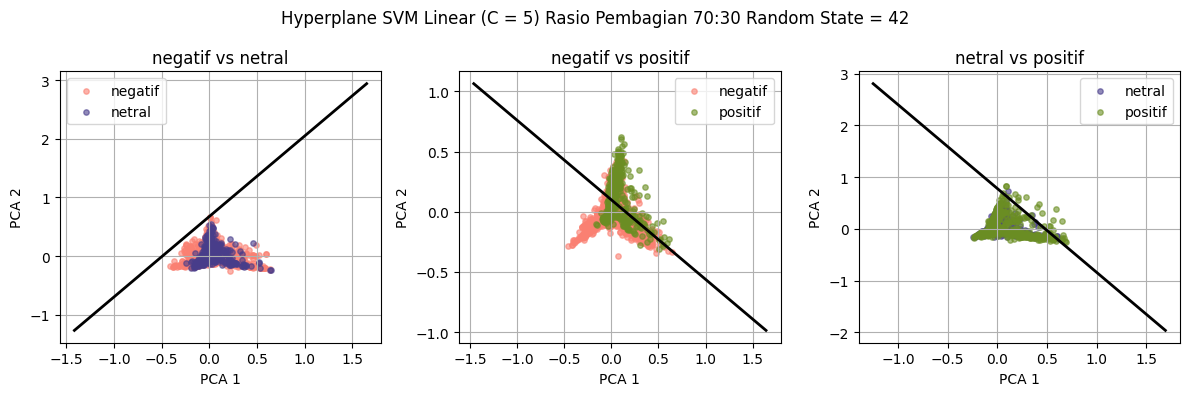

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

C_val = [5]

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_42, y_train_7030_42)

    fig, axes = plt.subplots(1,3,figsize=(12,4))

    for i,(kelas1,kelas2) in enumerate(pairs):

        ax = axes[i]

        # Ambil subset data untuk pasangan kelas
        mask_train = (y_train_7030_42==kelas1) | (y_train_7030_42==kelas2)
        X_pair = X_train_tfidf_7030_42[mask_train.to_numpy()]
        y_pair = y_train_7030_42[mask_train]

        # PCA 2D untuk visualisasi
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        # Ambil hyperplane asli dari model OVO
        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        # Proyeksikan w ke ruang PCA
        w_pca = pca.components_ @ w

        # Plot semua data
        for label in [kelas1,kelas2]:

            mask_plot = (y_pair==label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        # Plot hyperplane
        x_vals = np.linspace(X_pca[:,0].min()-1,
                             X_pca[:,0].max()+1,
                             200)

        if w_pca[1] != 0:
            y_vals = -(w_pca[0]*x_vals+b)/w_pca[1]
            ax.plot(x_vals,y_vals,'k-',linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0],
                       color='k',
                       linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(f'Hyperplane SVM Linear (C = {C_val}) Rasio Pembagian {rasio} Random State = 42')
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

C_val = [5]
hasil_evaluasi_7030_42 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_42, y_train_7030_42)

    y_pred = svm_model.predict(X_test_tfidf_7030_42)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (70:30) Random State = 42 untuk C = {C_val} ---")

    hasil_prediksi_svm_7030_42 = pd.DataFrame({
        'teks_tweet': X_test_7030_42,
        'label_aktual': y_test_7030_42,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_7030_42)

    accuracy = accuracy_score(y_test_7030_42, y_pred)
    precision = precision_score(y_test_7030_42, y_pred, average='macro')
    sensitivity = recall_score(y_test_7030_42, y_pred, average='macro')
    f1 = f1_score(y_test_7030_42, y_pred, average='macro')

    hasil_evaluasi_7030_42.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM DENGAN C = {C_val} | RASIO 70:30 | RANDOM STATE = 42 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test_7030_42, y_pred, labels=labels))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test_7030_42,
        y_pred,
        target_names=labels
    ))


--- Hasil Prediksi Klasifikasi SVM Data Testing (70:30) Random State = 42 untuk C = 5 ---
                                             teks_tweet label_aktual  \
468                                biar lebih hemat bbm      negatif   
2799                                       peh cek enak      negatif   
290                                  pekan puncak macet      negatif   
6147        liter bos orang enggan angkat tidak menteri       netral   
4557                               nasib travel pribadi       netral   
...                                                 ...          ...   
6136  cek lapang butuh bbm mobil distribusi butuh pa...       netral   
2456                         bijak tidak data sembarang      negatif   
3302                                      aduh mbg stop      negatif   
3706                    aneh liter pulang crbn surabaya      negatif   
929                                           acak acak      negatif   

     label_prediksi  
468         negatif  


# Random state 123

In [ ]:
# Model SVM
svm_7030_123 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_7030_123 = GridSearchCV(
    svm_7030_123,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_7030_123.fit(X_train_tfidf_7030_123, y_train_7030_123)

print("Best parameter :", grid_search_7030_123.best_params_)
print("Best Macro F1 :", grid_search_7030_123.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.7853250963194578


In [ ]:
hasil_tuning_7030_123 = pd.DataFrame(grid_search_7030_123.cv_results_)

hasil_tuning_7030_123 = hasil_tuning_7030_123[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_7030_123.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_7030_123.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.374425  0.013515        6
1  0.3       0.450938  0.016514        5
2  0.5       0.539487  0.012498        4
3  1.0       0.673916  0.018595        3
4  3.0       0.764271  0.012909        2
5  5.0       0.785325  0.006888        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "70:30"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_123, y_train_7030_123)

    support_indices = svm_model.support_
    y_sv = y_train_7030_123.iloc[support_indices] if hasattr(y_train_7030_123, "iloc") else y_train_7030_123[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_7030_123 == kelas1) | (y_train_7030_123 == kelas2)
        y_pair = y_train_7030_123[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 123,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_7030_123 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_7030_123)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,70:30,123,5,negatif vs netral,2916,908,996,824,1820,-0.531852,"[tidak, libur, kerja, atur, batas, jangan, jum...","[7.194064032687606, -5.241132171540649, -4.968..."
1,70:30,123,5,negatif vs positif,2916,656,996,430,1426,0.509135,"[tidak, libur, mobil, sekolah, kerja, jangan, ...","[5.036744152619885, -3.736623079903822, -3.540..."
2,70:30,123,5,netral vs positif,908,656,824,430,1254,1.125763,"[tidak, daring, kerja, honor, libur, mobil, ru...","[5.94616992107013, -5.464196175051144, -4.3923..."


In [ ]:
# ==========================================================
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_7030_123 == kelas1) | (y_train_7030_123 == kelas2)

    X_pair = X_train_tfidf_7030_123[mask_pair.to_numpy()]
    y_pair = y_train_7030_123[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()
    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n"+"="*80+"\n")

=== Model Biner: negatif vs netral ===

α_i = ['-0.500843919487566' '-1.4139095541503164' '-3.9478165725277967'
 '-1.9178656326663872' '-5.0' '...' '0.8532931173966626'
 '4.463961322270303' '4.886407163627907' '0.4683773860961506'
 '0.4681747015754286']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.5319


=== Model Biner: negatif vs positif ===

α_i = ['-1.0569683236298855' '-5.0' '-0.09322675433265701' '-0.4227797887279432'
 '-1.8479651293722295' '...' '0.35300030943663924' '5.0'
 '1.0068288265134953' '0.8857340969573526' '3.0478596648018175']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 

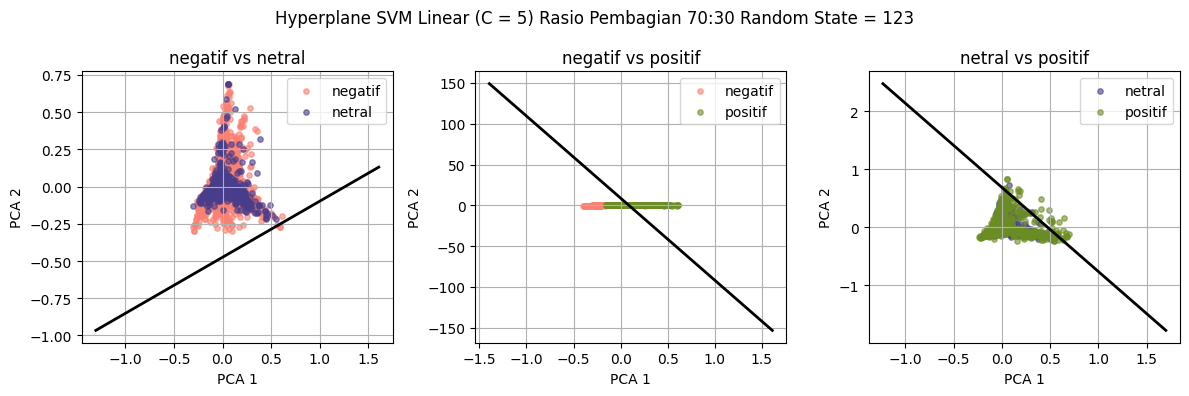

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

C_val = [5]

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_123, y_train_7030_123)

    fig, axes = plt.subplots(1,3,figsize=(12,4))

    for i,(kelas1,kelas2) in enumerate(pairs):

        ax = axes[i]

        mask_train = (y_train_7030_123==kelas1) | (y_train_7030_123==kelas2)
        X_pair = X_train_tfidf_7030_123[mask_train.to_numpy()]
        y_pair = y_train_7030_123[mask_train]

        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        w_pca = pca.components_ @ w

        for label in [kelas1,kelas2]:

            mask_plot = (y_pair==label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals = np.linspace(X_pca[:,0].min()-1,
                             X_pca[:,0].max()+1,
                             200)

        if w_pca[1] != 0:
            y_vals = -(w_pca[0]*x_vals+b)/w_pca[1]
            ax.plot(x_vals,y_vals,'k-',linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0],
                       color='k',
                       linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(f'Hyperplane SVM Linear (C = {C_val}) Rasio Pembagian {rasio} Random State = 123')
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

C_val = [5]
hasil_evaluasi_7030_123 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_123, y_train_7030_123)

    y_pred = svm_model.predict(X_test_tfidf_7030_123)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (70:30) Random State = 123 untuk C = {C_val} ---")

    hasil_prediksi_svm_7030_123 = pd.DataFrame({
        'teks_tweet': X_test_7030_123,
        'label_aktual': y_test_7030_123,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_7030_123)

    accuracy = accuracy_score(y_test_7030_123, y_pred)
    precision = precision_score(y_test_7030_123, y_pred, average='macro')
    sensitivity = recall_score(y_test_7030_123, y_pred, average='macro')
    f1 = f1_score(y_test_7030_123, y_pred, average='macro')

    hasil_evaluasi_7030_123.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM DENGAN C = {C_val} | RASIO 70:30 | RANDOM STATE = 123 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test_7030_123, y_pred, labels=labels))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test_7030_123,
        y_pred,
        target_names=labels
    ))


--- Hasil Prediksi Klasifikasi SVM Data Testing (70:30) Random State = 123 untuk C = 5 ---
                                             teks_tweet label_aktual  \
5442                                       terlalu atur      negatif   
1357            asn tenaga sehat guru tidak teman teman       netral   
3704                                      lebih mbg bbm      positif   
921           naa pusing akibat apbn tidak hitung valid      negatif   
5618  perintah asal kendara niaga tempuh jalan perin...      negatif   
...                                                 ...          ...   
5559  antre macet parah distribusi butuh pokok hamba...      negatif   
4809  mobil guna pribadi non subsidi pertamax mobil ...      positif   
3366                   tidak kerja keluyur sih perintah       netral   
6168                                     moga realisasi       netral   
4885            kendara motor batas tidak berita kompas      negatif   

     label_prediksi  
5442        negatif  

# Random state 999

In [ ]:
# Model SVM
svm_7030_999 = SVC(kernel='linear')

# Parameter C yang akan diuji
param_grid = {'C': [0.1, 0.3, 0.5, 1, 3, 5]}

# Grid Search
grid_search_7030_999 = GridSearchCV(
    svm_7030_999,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_7030_999.fit(X_train_tfidf_7030_999, y_train_7030_999)

print("Best parameter :", grid_search_7030_999.best_params_)
print("Best Macro F1 :", grid_search_7030_999.best_score_)

Best parameter : {'C': 5}
Best Macro F1 : 0.7818081566893944


In [ ]:
hasil_tuning_7030_999 = pd.DataFrame(grid_search_7030_999.cv_results_)

hasil_tuning_7030_999 = hasil_tuning_7030_999[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_7030_999.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_7030_999.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.355739  0.015991        6
1  0.3       0.453829  0.003435        5
2  0.5       0.540541  0.005405        4
3  1.0       0.657125  0.018922        3
4  3.0       0.763812  0.009527        2
5  5.0       0.781808  0.007143        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "70:30"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_999, y_train_7030_999)

    support_indices = svm_model.support_
    y_sv = y_train_7030_999.iloc[support_indices] if hasattr(y_train_7030_999, "iloc") else y_train_7030_999[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data asli pasangan kelas
        mask_pair = (y_train_7030_999 == kelas1) | (y_train_7030_999 == kelas2)
        y_pair = y_train_7030_999[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # ===== ambil w dan b =====
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # ===== ambil fitur paling berpengaruh =====
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        # ubah indeks -> kata
        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info.append({
            'Rasio': rasio,
            'Random State': 999,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_7030_999 = pd.DataFrame(model_info)

pd.set_option('display.max_columns', None)
display(df_model_info_7030_999)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,70:30,999,5,negatif vs netral,2916,908,1016,817,1833,-0.571225,"[tidak, atur, libur, kerja, batas, aduh, jumat...","[6.862001834063619, 5.231828986833534, -5.0648..."
1,70:30,999,5,negatif vs positif,2916,656,1016,445,1461,0.519978,"[tidak, kerja, mobil, jangan, libur, batas, se...","[4.89624847005075, -3.557429993829352, -3.5274..."
2,70:30,999,5,netral vs positif,908,656,817,445,1262,1.132812,"[tidak, daring, batas, kerja, bayar, libur, mo...","[6.2175745444694, -6.187572616067793, 4.550745..."


In [ ]:
# ==========================================================
# MENAMPILKAN ai, yi, dan xi UNTUK SVM >>> MODEL TERBAIK
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

# tampilkan
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_7030_999 == kelas1) | (y_train_7030_999 == kelas2)

    X_pair = X_train_tfidf_7030_999[mask_pair.to_numpy()]
    y_pair = y_train_7030_999[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()
    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner: {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))
    print("\n"+"="*80+"\n")

=== Model Biner: negatif vs netral ===

α_i = ['-4.37856767043295' '-1.0501227967929312' '-1.0057240644830627' '-5.0'
 '-1.727410819305183' '...' '0.26579808990435094' '1.3315254588988994'
 '0.2633952277209144' '5.0' '3.2648107071106303']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.5712


=== Model Biner: negatif vs positif ===

α_i = ['-2.4065080688577782' '-2.456212509119413' '-0.4400092120909035'
 '-2.4289642129589617' '-0.6546481791470086' '...' '1.5197915351143267'
 '4.280438181627301' '5.0' '0.24737990723686526' '0.43055377226361696']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.3996456508525198 0.0 0.0 0.0

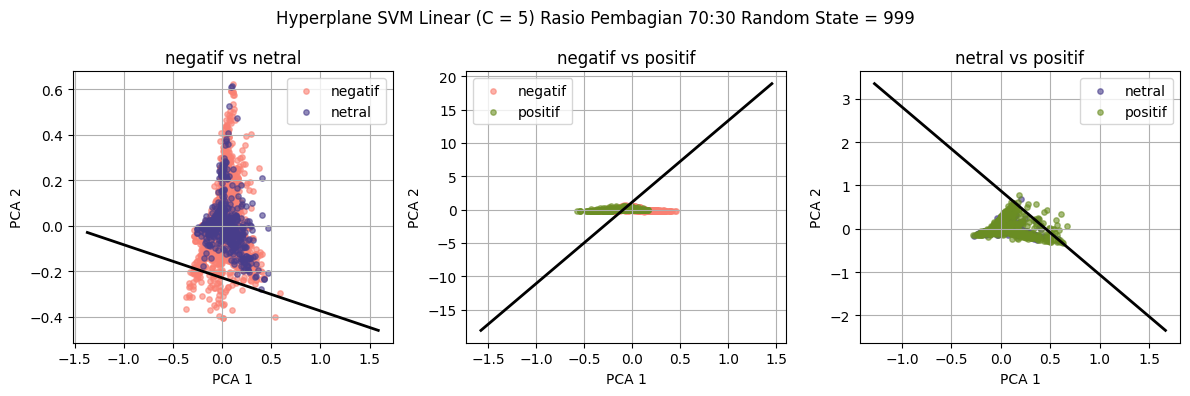

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

C_val = [5]

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_999, y_train_7030_999)

    fig, axes = plt.subplots(1,3,figsize=(12,4))

    for i,(kelas1,kelas2) in enumerate(pairs):

        ax = axes[i]

        mask_train = (y_train_7030_999==kelas1) | (y_train_7030_999==kelas2)
        X_pair = X_train_tfidf_7030_999[mask_train.to_numpy()]
        y_pair = y_train_7030_999[mask_train]

        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        w_pca = pca.components_ @ w

        for label in [kelas1,kelas2]:

            mask_plot = (y_pair==label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals = np.linspace(X_pca[:,0].min()-1,
                             X_pca[:,0].max()+1,
                             200)

        if w_pca[1] != 0:
            y_vals = -(w_pca[0]*x_vals+b)/w_pca[1]
            ax.plot(x_vals,y_vals,'k-',linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0],
                       color='k',
                       linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(f'Hyperplane SVM Linear (C = {C_val}) Rasio Pembagian {rasio} Random State = 999')
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================================
# PREDIKSI DAN EVALUASI
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

C_val = [5]
hasil_evaluasi_7030_999 = []

labels = ['negatif', 'netral', 'positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_7030_999, y_train_7030_999)

    y_pred = svm_model.predict(X_test_tfidf_7030_999)

    print(f"\n--- Hasil Prediksi Klasifikasi SVM Data Testing (70:30) Random State = 999 untuk C = {C_val} ---")

    hasil_prediksi_svm_7030_999 = pd.DataFrame({
        'teks_tweet': X_test_7030_999,
        'label_aktual': y_test_7030_999,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_7030_999)

    accuracy = accuracy_score(y_test_7030_999, y_pred)
    precision = precision_score(y_test_7030_999, y_pred, average='macro')
    sensitivity = recall_score(y_test_7030_999, y_pred, average='macro')
    f1 = f1_score(y_test_7030_999, y_pred, average='macro')

    hasil_evaluasi_7030_999.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM DENGAN C = {C_val} | RASIO 70:30 | RANDOM STATE = 999 ---")
    print("Accuracy :", accuracy)
    print("Precision :", precision)
    print("Sensitivity :", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test_7030_999, y_pred, labels=labels))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test_7030_999,
        y_pred,
        target_names=labels
    ))


--- Hasil Prediksi Klasifikasi SVM Data Testing (70:30) Random State = 999 untuk C = 5 ---
                                             teks_tweet label_aktual  \
3612                              belum tuju udah habis      negatif   
399                 ampun anak rontok rambut ajar rumah      negatif   
3954                                     anjir perintah      negatif   
4709                    sticker salah buka tiktok malem      negatif   
632          mah mending hemat bbm habis duluan bbm nya      negatif   
...                                                 ...          ...   
2276  wfh efisiensi bbm anak sekolah sabtu libur ber...       netral   
1402                                       tenaga medis      positif   
6260  kantor rencana hajat tuh haha tolong cut acara...      negatif   
4290                      batas lapang tidak terap main      negatif   
1412                              maksude guna wfh alas      positif   

     label_prediksi  
3612        negatif  

# Hasil Evaluasi

In [ ]:
# ==========================================================
# HASIL EVALUASI SVM SEMUA RASIO DAN RANDOM STATE
# ==========================================================

# =========================
# RASIO 90:10
# =========================

df_eval_9010_42 = pd.DataFrame(hasil_evaluasi_9010_42)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_9010_42[col] *= 100

print("========================================================")
print("EVALUASI SVM | RASIO 90:10 | RANDOM STATE = 42")
print("========================================================")
print(df_eval_9010_42)


df_eval_9010_123 = pd.DataFrame(hasil_evaluasi_9010_123)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_9010_123[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 90:10 | RANDOM STATE = 123")
print("========================================================")
print(df_eval_9010_123)


df_eval_9010_999 = pd.DataFrame(hasil_evaluasi_9010_999)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_9010_999[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 90:10 | RANDOM STATE = 999")
print("========================================================")
print(df_eval_9010_999)


# =========================
# RASIO 80:20
# =========================

df_eval_8020_42 = pd.DataFrame(hasil_evaluasi_8020_42)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_8020_42[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 80:20 | RANDOM STATE = 42")
print("========================================================")
print(df_eval_8020_42)


df_eval_8020_123 = pd.DataFrame(hasil_evaluasi_8020_123)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_8020_123[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 80:20 | RANDOM STATE = 123")
print("========================================================")
print(df_eval_8020_123)


df_eval_8020_999 = pd.DataFrame(hasil_evaluasi_8020_999)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_8020_999[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 80:20 | RANDOM STATE = 999")
print("========================================================")
print(df_eval_8020_999)


# =========================
# RASIO 70:30
# =========================

df_eval_7030_42 = pd.DataFrame(hasil_evaluasi_7030_42)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_7030_42[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 70:30 | RANDOM STATE = 42")
print("========================================================")
print(df_eval_7030_42)


df_eval_7030_123 = pd.DataFrame(hasil_evaluasi_7030_123)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_7030_123[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 70:30 | RANDOM STATE = 123")
print("========================================================")
print(df_eval_7030_123)


df_eval_7030_999 = pd.DataFrame(hasil_evaluasi_7030_999)
for col in ['Accuracy', 'Precision', 'Sensitivity', 'F1-Score']:
    df_eval_7030_999[col] *= 100

print("\n========================================================")
print("EVALUASI SVM | RASIO 70:30 | RANDOM STATE = 999")
print("========================================================")
print(df_eval_7030_999)

EVALUASI SVM | RASIO 90:10 | RANDOM STATE = 42
   C  Accuracy  Precision  Sensitivity   F1-Score
0  5  88.28125  83.668831    82.585243  83.095771

EVALUASI SVM | RASIO 90:10 | RANDOM STATE = 123
   C  Accuracy  Precision  Sensitivity   F1-Score
0  5      87.5  84.908268    82.360884  83.373771

EVALUASI SVM | RASIO 90:10 | RANDOM STATE = 999
   C  Accuracy  Precision  Sensitivity   F1-Score
0  5     88.75  84.382577    85.275846  84.803852

EVALUASI SVM | RASIO 80:20 | RANDOM STATE = 42
   C   Accuracy  Precision  Sensitivity   F1-Score
0  5  87.421875  82.336019    82.478765  82.362837

EVALUASI SVM | RASIO 80:20 | RANDOM STATE = 123
   C  Accuracy  Precision  Sensitivity   F1-Score
0  5  87.03125  82.649696     81.68945  82.045496

EVALUASI SVM | RASIO 80:20 | RANDOM STATE = 999
   C   Accuracy  Precision  Sensitivity  F1-Score
0  5  88.203125  84.263335    84.669659  84.26806

EVALUASI SVM | RASIO 70:30 | RANDOM STATE = 42
   C   Accuracy  Precision  Sensitivity   F1-Score
0  5  85

# **NBC**

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 90:10

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (90:10)
# RANDOM STATE = 42
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_9010_42 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_9010_42 = tfidf_vectorizer_9010_42.fit_transform(
    X_train_9010_42
)

# Transform data testing
X_test_tfidf_9010_42 = tfidf_vectorizer_9010_42.transform(
    X_test_9010_42
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_9010_42 = tfidf_vectorizer_9010_42.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_9010_42 = {
    word: i for i, word in enumerate(vocab_9010_42)
}

print("\nJumlah Vocabulary :", len(vocab_9010_42))

vocab_df_9010_42 = pd.DataFrame({
    "Vocabulary": vocab_9010_42
})

display(vocab_df_9010_42)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_9010_42 = MultinomialNB(alpha=1.0)

nb_model_9010_42.fit(
    X_train_tfidf_9010_42,
    y_train_9010_42
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_9010_42 = pd.DataFrame({
    "Kelas": nb_model_9010_42.classes_,
    "Prior": np.exp(nb_model_9010_42.class_log_prior_)
})

display(prior_df_9010_42)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

# Mengambil log likelihood hanya untuk vocabulary yang muncul pada data training

likelihood_9010_42 = pd.DataFrame(
    np.exp(nb_model_9010_42.feature_log_prob_).T,
    index=vocab_9010_42,
    columns=nb_model_9010_42.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_9010_42)
# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_9010_42 = nb_model_9010_42.predict(
    X_test_tfidf_9010_42
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_9010_42.predict_proba(
    X_test_tfidf_9010_42
)

hasil_posterior_9010_42 = pd.DataFrame({

    "Dok": X_test_9010_42.index,

    "Teks Komentar": X_test_9010_42.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_9010_42.values,

    "Label Prediksi": y_pred_9010_42

})

print("\n========== HASIL POSTERIOR ==========\n")

display(hasil_posterior_9010_42)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_9010_42 = accuracy_score(
    y_test_9010_42,
    y_pred_9010_42
)

precision_macro_9010_42 = precision_score(
    y_test_9010_42,
    y_pred_9010_42,
    average='macro'
)

recall_macro_9010_42 = recall_score(
    y_test_9010_42,
    y_pred_9010_42,
    average='macro'
)

f1_macro_9010_42 = f1_score(
    y_test_9010_42,
    y_pred_9010_42,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_9010_42,2))

print("\nMacro Average")
print("Precision :", round(precision_macro_9010_42,2))
print("Recall    :", round(recall_macro_9010_42,2))
print("F1-Score  :", round(f1_macro_9010_42,2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_9010_42 = confusion_matrix(
    y_test_9010_42,
    y_pred_9010_42,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_9010_42 = pd.DataFrame(
    cm_9010_42,
    index=labels,
    columns=labels
)

display(cm_df_9010_42)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_9010_42,
        y_pred_9010_42,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3482


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3477,zaman
3478,zenix
3479,zolim
3480,zonasi


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.651042
1,netral,0.202604
2,positif,0.146354



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000104,0.000175,0.000187
abdi,0.000191,0.000175,0.000263
absen,0.000455,0.000175,0.000221
absensi,0.000148,0.000175,0.000187
absurd,0.000117,0.000175,0.000187
...,...,...,...
zaman,0.000968,0.000758,0.000681
zenix,0.000080,0.000175,0.000237
zolim,0.000080,0.000175,0.000375
zonasi,0.000122,0.000175,0.000572



========== HASIL POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,1721,wfh laksana nya perintah ketidakpercayaan laks...,0.531476,0.232444,0.236080,netral,negatif
1,5862,suka kelen,0.738410,0.165744,0.095846,negatif,negatif
2,1257,tolong anak sekolah jangan daring kacau daring,0.946865,0.012867,0.040268,negatif,negatif
3,773,enak banget ngomong tidak kerja pecat tutup ti...,0.828840,0.102131,0.069029,negatif,negatif
4,4659,kocak nih perintah tidak atur beli bensin lite...,0.962788,0.034345,0.002867,negatif,negatif
...,...,...,...,...,...,...,...
635,5988,atur nya tidak jelas tai atur susah supir eksp...,0.987646,0.008824,0.003531,negatif,negatif
636,1675,layan hotel restoran ajak tidak,0.570030,0.284088,0.145882,negatif,negatif
637,3393,cabut alokasi mobil dinas,0.652913,0.194465,0.152622,netral,negatif
638,4196,tidak akal nya perintah,0.854830,0.117949,0.027220,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.66

Macro Average
Precision : 0.55
Recall    : 0.36
F1-Score  : 0.31

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,416,0,0
netral,130,0,0
positif,86,1,7



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.79       416
      netral       0.00      0.00      0.00       130
     positif       1.00      0.07      0.14        94

    accuracy                           0.66       640
   macro avg       0.55      0.36      0.31       640
weighted avg       0.57      0.66      0.54       640



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (90:10)
# RANDOM STATE = 123
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

# Membuat objek TF-IDF
tfidf_vectorizer_9010_123 = TfidfVectorizer()

# Fit pada data training
X_train_tfidf_9010_123 = tfidf_vectorizer_9010_123.fit_transform(
    X_train_9010_123
)

# Transform data testing
X_test_tfidf_9010_123 = tfidf_vectorizer_9010_123.transform(
    X_test_9010_123

)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_9010_123 = tfidf_vectorizer_9010_123.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_9010_123 = {
    word: i for i, word in enumerate(vocab_9010_123)
}

print("\nJumlah Vocabulary :", len(vocab_9010_123))

vocab_df_9010_123 = pd.DataFrame({
    "Vocabulary": vocab_9010_123
})

display(vocab_df_9010_123)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_9010_123 = MultinomialNB(alpha=1.0)

nb_model_9010_123.fit(
    X_train_tfidf_9010_123,
    y_train_9010_123
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_9010_123 = pd.DataFrame({
    "Kelas": nb_model_9010_123.classes_,
    "Prior": np.exp(nb_model_9010_123.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")

display(prior_df_9010_123)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

# Mengambil log likelihood hanya untuk vocabulary yang muncul pada data training

likelihood_9010_123 = pd.DataFrame(
    np.exp(nb_model_9010_123.feature_log_prob_).T,
    index=vocab_9010_123,
    columns=nb_model_9010_123.classes_
)

print("\n========== LIKELIHOOD ==========\n")

display(likelihood_9010_123)
# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_9010_123 = nb_model_9010_123.predict(
    X_test_tfidf_9010_123
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_9010_123.predict_proba(
    X_test_tfidf_9010_123
)

hasil_posterior_9010_123 = pd.DataFrame({

    "Dok": X_test_9010_123.index,

    "Teks Komentar": X_test_9010_123.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_9010_123.values,

    "Label Prediksi": y_pred_9010_123

})

print("\n========== HASIL POSTERIOR ==========\n")

display(hasil_posterior_9010_123)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_9010_123 = accuracy_score(
    y_test_9010_123,
    y_pred_9010_123
)

precision_macro_9010_123 = precision_score(
    y_test_9010_123,
    y_pred_9010_123,
    average='macro'
)

recall_macro_9010_123 = recall_score(
    y_test_9010_123,
    y_pred_9010_123,
    average='macro'
)

f1_macro_9010_123 = f1_score(
    y_test_9010_123,
    y_pred_9010_123,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_9010_123,2))

print("\nMacro Average")
print("Precision :", round(precision_macro_9010_123,2))
print("Recall    :", round(recall_macro_9010_123,2))
print("F1-Score  :", round(f1_macro_9010_123,2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_9010_123 = confusion_matrix(
    y_test_9010_123,
    y_pred_9010_123,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_9010_123 = pd.DataFrame(
    cm_9010_123,
    index=labels,
    columns=labels
)

display(cm_df_9010_123)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_9010_123,
        y_pred_9010_123,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3538


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3533,zenix
3534,zolim
3535,zonasi
3536,zonk


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.651042
1,netral,0.202604
2,positif,0.146354



========== LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000103,0.000173,0.000185
abdi,0.000168,0.000173,0.000322
absen,0.000415,0.000173,0.000220
absensi,0.000147,0.000173,0.000185
absurd,0.000116,0.000173,0.000185
...,...,...,...
zenix,0.000080,0.000173,0.000235
zolim,0.000080,0.000173,0.000372
zonasi,0.000121,0.000173,0.000567
zonk,0.000080,0.000173,0.000265


... (3 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,negatif,netral,positif
negatif,416,0,0
netral,130,0,0
positif,87,0,7



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.79       416
      netral       0.00      0.00      0.00       130
     positif       1.00      0.07      0.14        94

    accuracy                           0.66       640
   macro avg       0.55      0.36      0.31       640
weighted avg       0.57      0.66      0.54       640



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (90:10)
# RANDOM STATE = 999
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

# Membuat objek TF-IDF
tfidf_vectorizer_9010_999 = TfidfVectorizer()

# Fit pada data training
X_train_tfidf_9010_999 = tfidf_vectorizer_9010_999.fit_transform(
    X_train_9010_999
)

# Transform data testing
X_test_tfidf_9010_999 = tfidf_vectorizer_9010_999.transform(
    X_test_9010_999
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_9010_999 = tfidf_vectorizer_9010_999.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_9010_999 = {
    word: i for i, word in enumerate(vocab_9010_999)
}

print("\nJumlah Vocabulary :", len(vocab_9010_999))

vocab_df_9010_999 = pd.DataFrame({
    "Vocabulary": vocab_9010_999
})

display(vocab_df_9010_999)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_9010_999 = MultinomialNB(alpha=1.0)

nb_model_9010_999.fit(
    X_train_tfidf_9010_999,
    y_train_9010_999
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_9010_999 = pd.DataFrame({
    "Kelas": nb_model_9010_999.classes_,
    "Prior": np.exp(nb_model_9010_999.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")

display(prior_df_9010_999)

# ==========================================================
# LIKELIHOOD
# ==========================================================

likelihood_9010_999 = pd.DataFrame(
    np.exp(nb_model_9010_999.feature_log_prob_).T,
    index=vocab_9010_999,
    columns=nb_model_9010_999.classes_
)

print("\n========== LIKELIHOOD ==========\n")

display(likelihood_9010_999)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_9010_999 = nb_model_9010_999.predict(
    X_test_tfidf_9010_999
)

# ==========================================================
# POSTERIOR PROBABILITY
# ==========================================================

posterior = nb_model_9010_999.predict_proba(
    X_test_tfidf_9010_999
)

hasil_posterior_9010_999 = pd.DataFrame({

    "Dok": X_test_9010_999.index,

    "Teks Komentar": X_test_9010_999.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_9010_999.values,

    "Label Prediksi": y_pred_9010_999

})

print("\n========== HASIL POSTERIOR ==========\n")

display(hasil_posterior_9010_999)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_9010_999 = accuracy_score(
    y_test_9010_999,
    y_pred_9010_999
)

precision_macro_9010_999 = precision_score(
    y_test_9010_999,
    y_pred_9010_999,
    average='macro'
)

recall_macro_9010_999 = recall_score(
    y_test_9010_999,
    y_pred_9010_999,
    average='macro'
)

f1_macro_9010_999 = f1_score(
    y_test_9010_999,
    y_pred_9010_999,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_9010_999, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_9010_999, 2))
print("Recall    :", round(recall_macro_9010_999, 2))
print("F1-Score  :", round(f1_macro_9010_999, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_9010_999 = confusion_matrix(
    y_test_9010_999,
    y_pred_9010_999,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_9010_999 = pd.DataFrame(
    cm_9010_999,
    index=labels,
    columns=labels
)

display(cm_df_9010_999)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_9010_999,
        y_pred_9010_999,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3547


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3542,zenix
3543,zolim
3544,zonasi
3545,zonk


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.651042
1,netral,0.202604
2,positif,0.146354



========== LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000103,0.000173,0.000185
abdi,0.000188,0.000173,0.000319
absen,0.000405,0.000299,0.000218
absensi,0.000147,0.000173,0.000185
absurd,0.000116,0.000173,0.000185
...,...,...,...
zenix,0.000080,0.000173,0.000234
zolim,0.000080,0.000173,0.000371
zonasi,0.000122,0.000173,0.000498
zonk,0.000080,0.000173,0.000264



========== HASIL POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,38,tolong jangan bilang anak sekolah ajar daring ...,0.988667,0.003676,0.007656,negatif,negatif
1,4439,liter kendara tidak laku kendara truk plat hit...,0.908017,0.068830,0.023154,negatif,negatif
2,930,aduh hemat bbm stop jual kendara,0.953068,0.035091,0.011841,negatif,negatif
3,3196,jujur jujuran jabat konyol,0.936756,0.038314,0.024930,negatif,negatif
4,111,bijak tidak bijak,0.967076,0.023105,0.009818,negatif,negatif
...,...,...,...,...,...,...,...
635,4948,kalang kabut,0.395329,0.427112,0.177560,negatif,netral
636,469,hemat laku mobil minimal orang liburin jalan j...,0.823187,0.122307,0.054507,negatif,negatif
637,4419,terlalu atur bijak kabinet susah masyarakat pa...,0.976501,0.018699,0.004800,negatif,negatif
638,3720,suami supir lintas jawa sumatera gaji tim alok...,0.817439,0.130743,0.051819,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.67
Recall    : 0.39
F1-Score  : 0.36

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,415,1,0
netral,129,1,0
positif,78,1,15



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.67      1.00      0.80       416
      netral       0.33      0.01      0.02       130
     positif       1.00      0.16      0.28        94

    accuracy                           0.67       640
   macro avg       0.67      0.39      0.36       640
weighted avg       0.65      0.67      0.56       640



# Rasio 80:20

# Random state 42

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (80:20)
# RANDOM STATE = 42
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_8020_42 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_8020_42 = tfidf_vectorizer_8020_42.fit_transform(
    X_train_8020_42
)

# Transform data testing
X_test_tfidf_8020_42 = tfidf_vectorizer_8020_42.transform(
    X_test_8020_42
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_8020_42 = tfidf_vectorizer_8020_42.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_8020_42 = {
    word: i for i, word in enumerate(vocab_8020_42)
}

print("\nJumlah Vocabulary :", len(vocab_8020_42))

vocab_df_8020_42 = pd.DataFrame({
    "Vocabulary": vocab_8020_42
})

display(vocab_df_8020_42)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_8020_42 = MultinomialNB(alpha=1.0)

nb_model_8020_42.fit(
    X_train_tfidf_8020_42,
    y_train_8020_42
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_9010_42 = pd.DataFrame({
    "Kelas": nb_model_9010_42.classes_,
    "Prior": np.exp(nb_model_9010_42.class_log_prior_)
})

display(prior_df_9010_42)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

# Mengambil log likelihood hanya untuk vocabulary yang muncul pada data training

likelihood_8020_42 = pd.DataFrame(
    np.exp(nb_model_8020_42.feature_log_prob_).T,
    index=vocab_8020_42,
    columns=nb_model_8020_42.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_8020_42)
# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_8020_42 = nb_model_8020_42.predict(
    X_test_tfidf_8020_42
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_8020_42.predict_proba(
    X_test_tfidf_8020_42
)

hasil_posterior_8020_42 = pd.DataFrame({

    "Dok": X_test_8020_42.index,

    "Teks Komentar": X_test_8020_42.values,

    "Log Posterior Negatif": posterior[:, 0],

    "Log Posterior Netral": posterior[:, 1],

    "Log Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_8020_42.values,

    "Label Prediksi": y_pred_8020_42

})

print("\n========== HASIL LOG POSTERIOR ==========\n")

display(hasil_posterior_8020_42)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_8020_42 = accuracy_score(
    y_test_8020_42,
    y_pred_8020_42
)

precision_macro_8020_42 = precision_score(
    y_test_8020_42,
    y_pred_8020_42,
    average='macro'
)

recall_macro_8020_42 = recall_score(
    y_test_8020_42,
    y_pred_8020_42,
    average='macro'
)

f1_macro_8020_42 = f1_score(
    y_test_8020_42,
    y_pred_8020_42,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_8020_42,2))

print("\nMacro Average")
print("Precision :", round(precision_macro_8020_42,2))
print("Recall    :", round(recall_macro_8020_42,2))
print("F1-Score  :", round(f1_macro_8020_42,2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_8020_42 = confusion_matrix(
    y_test_8020_42,
    y_pred_8020_42,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_8020_42 = pd.DataFrame(
    cm_8020_42,
    index=labels,
    columns=labels
)

display(cm_df_8020_42)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_8020_42,
        y_pred_8020_42,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3302


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3297,zaitun
3298,zaman
3299,zolim
3300,zonasi


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.651042
1,netral,0.202604
2,positif,0.146354



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000115,0.000189,0.000201
abdi,0.000210,0.000189,0.000283
absen,0.000460,0.000189,0.000238
absensi,0.000162,0.000189,0.000201
absurd,0.000128,0.000189,0.000201
...,...,...,...
zaitun,0.000152,0.000189,0.000201
zaman,0.000976,0.000708,0.000562
zolim,0.000089,0.000189,0.000403
zonasi,0.000114,0.000189,0.000618



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,993,wfh kerja pakai komputer laptop teman teman,0.553734,0.300345,0.145922,positif,negatif
1,4493,liter tidak mobil pribadi,0.770007,0.160070,0.069922,netral,negatif
2,3082,tidak daring ibu daring,0.668745,0.027022,0.304233,positif,negatif
3,2021,tolong pengaruh kurang paham butuh jelas perinci,0.982917,0.011734,0.005349,negatif,negatif
4,1123,bumc tidak min,0.632445,0.300044,0.067511,negatif,negatif
...,...,...,...,...,...,...,...
1275,2828,jangan hak karyawan doang bos hak usaha langsu...,0.953619,0.015809,0.030572,negatif,negatif
1276,4248,tambah geopolitik tidak sesuai dampak indonesi...,0.913058,0.070755,0.016187,negatif,negatif
1277,4519,panik,0.739667,0.147287,0.113047,negatif,negatif
1278,5907,kota aduh kasihan bos,0.904965,0.051875,0.043159,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.75
Recall    : 0.37
F1-Score  : 0.34

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,831,2,0
netral,251,7,1
positif,168,2,18



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.80       833
      netral       0.64      0.03      0.05       259
     positif       0.95      0.10      0.17       188

    accuracy                           0.67      1280
   macro avg       0.75      0.37      0.34      1280
weighted avg       0.70      0.67      0.56      1280



# Random state 123

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (80:20)
# RANDOM STATE = 123
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_8020_123 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_8020_123 = tfidf_vectorizer_8020_123.fit_transform(
    X_train_8020_123
)

# Transform data testing
X_test_tfidf_8020_123 = tfidf_vectorizer_8020_123.transform(
    X_test_8020_123
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_8020_123 = tfidf_vectorizer_8020_123.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_8020_123 = {
    word: i for i, word in enumerate(vocab_8020_123)
}

print("\nJumlah Vocabulary :", len(vocab_8020_123))

vocab_df_8020_123 = pd.DataFrame({
    "Vocabulary": vocab_8020_123
})

display(vocab_df_8020_123)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_8020_123 = MultinomialNB(alpha=1.0)

nb_model_8020_123.fit(
    X_train_tfidf_8020_123,
    y_train_8020_123
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_8020_123 = pd.DataFrame({
    "Kelas": nb_model_8020_123.classes_,
    "Prior": np.exp(nb_model_8020_123.class_log_prior_)
})

display(prior_df_8020_123)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

# Mengambil log likelihood hanya untuk vocabulary yang muncul pada data training

likelihood_8020_123 = pd.DataFrame(
    np.exp(nb_model_8020_123.feature_log_prob_).T,
    index=vocab_8020_123,
    columns=nb_model_8020_123.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_8020_123)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_8020_123 = nb_model_8020_123.predict(
    X_test_tfidf_8020_123
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_8020_123.predict_proba(
    X_test_tfidf_8020_123
)

hasil_posterior_8020_123 = pd.DataFrame({

    "Dok": X_test_8020_123.index,

    "Teks Komentar": X_test_8020_123.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_8020_123.values,

    "Label Prediksi": y_pred_8020_123

})

print("\n========== HASIL LOG POSTERIOR ==========\n")

display(hasil_posterior_8020_123)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_8020_123 = accuracy_score(
    y_test_8020_123,
    y_pred_8020_123
)

precision_macro_8020_123 = precision_score(
    y_test_8020_123,
    y_pred_8020_123,
    average='macro'
)

recall_macro_8020_123 = recall_score(
    y_test_8020_123,
    y_pred_8020_123,
    average='macro'
)

f1_macro_8020_123 = f1_score(
    y_test_8020_123,
    y_pred_8020_123,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_8020_123,2))

print("\nMacro Average")
print("Precision :", round(precision_macro_8020_123,2))
print("Recall    :", round(recall_macro_8020_123,2))
print("F1-Score  :", round(f1_macro_8020_123,2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_8020_123 = confusion_matrix(
    y_test_8020_123,
    y_pred_8020_123,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_8020_123 = pd.DataFrame(
    cm_8020_123,
    index=labels,
    columns=labels
)

display(cm_df_8020_123)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_8020_123,
        y_pred_8020_123,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3328


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3323,zenix
3324,zolim
3325,zonasi
3326,zonk


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.650977
1,netral,0.202734
2,positif,0.146289



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000114,0.000188,0.000200
abdi,0.000153,0.000188,0.000349
absen,0.000423,0.000188,0.000238
absensi,0.000126,0.000188,0.000200
absurd,0.000128,0.000188,0.000200
...,...,...,...
zenix,0.000089,0.000188,0.000254
zolim,0.000089,0.000188,0.000400
zonasi,0.000133,0.000188,0.000609
zonk,0.000089,0.000188,0.000285



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,948,heh jumat tanggal tanggal rabu,0.686312,0.121301,0.192387,negatif,negatif
1,5407,amburadul era prabowo angel,0.725168,0.207009,0.067824,negatif,negatif
2,1434,sticker stres stres,0.768485,0.116238,0.115277,negatif,negatif
3,358,maaf tidak efektif wfh mending pagawai anjur b...,0.846128,0.106660,0.047212,negatif,negatif
4,4058,banyak atur,0.965545,0.027251,0.007204,negatif,negatif
...,...,...,...,...,...,...,...
1275,784,malas gebrak konyol,0.888822,0.063445,0.047733,negatif,negatif
1276,3748,halah halah,0.854767,0.090960,0.054273,negatif,negatif
1277,4020,susah orang,0.939734,0.032694,0.027572,negatif,negatif
1278,3924,ibu ribu atur masalah minyak tidak mempan konoha,0.934712,0.045886,0.019402,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.66

Macro Average
Precision : 0.7
Recall    : 0.36
F1-Score  : 0.31

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,832,1,0
netral,256,3,0
positif,174,3,11



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.79       833
      netral       0.43      0.01      0.02       259
     positif       1.00      0.06      0.11       188

    accuracy                           0.66      1280
   macro avg       0.70      0.36      0.31      1280
weighted avg       0.66      0.66      0.54      1280



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (80:20)
# RANDOM STATE = 999
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_8020_999 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_8020_999 = tfidf_vectorizer_8020_999.fit_transform(
    X_train_8020_999
)

# Transform data testing
X_test_tfidf_8020_999 = tfidf_vectorizer_8020_999.transform(
    X_test_8020_999
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_8020_999 = tfidf_vectorizer_8020_999.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_8020_999 = {
    word: i for i, word in enumerate(vocab_8020_999)
}

print("\nJumlah Vocabulary :", len(vocab_8020_999))

vocab_df_8020_999 = pd.DataFrame({
    "Vocabulary": vocab_8020_999
})

display(vocab_df_8020_999)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_8020_999 = MultinomialNB(alpha=1.0)

nb_model_8020_999.fit(
    X_train_tfidf_8020_999,
    y_train_8020_999
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_8020_999 = pd.DataFrame({
    "Kelas": nb_model_8020_999.classes_,
    "Prior": np.exp(nb_model_8020_999.class_log_prior_)
})

display(prior_df_8020_999)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

# Mengambil log likelihood hanya untuk vocabulary yang muncul pada data training

likelihood_8020_999 = pd.DataFrame(
    np.exp(nb_model_8020_999.feature_log_prob_).T,
    index=vocab_8020_999,
    columns=nb_model_8020_999.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_8020_999)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_8020_999 = nb_model_8020_999.predict(
    X_test_tfidf_8020_999
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_8020_999.predict_proba(
    X_test_tfidf_8020_999
)

hasil_posterior_8020_999 = pd.DataFrame({

    "Dok": X_test_8020_999.index,

    "Teks Komentar": X_test_8020_999.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_8020_999.values,

    "Label Prediksi": y_pred_8020_999

})

print("\n========== HASIL LOG POSTERIOR ==========\n")

display(hasil_posterior_8020_999)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_8020_999 = accuracy_score(
    y_test_8020_999,
    y_pred_8020_999
)

precision_macro_8020_999 = precision_score(
    y_test_8020_999,
    y_pred_8020_999,
    average='macro'
)

recall_macro_8020_999 = recall_score(
    y_test_8020_999,
    y_pred_8020_999,
    average='macro'
)

f1_macro_8020_999 = f1_score(
    y_test_8020_999,
    y_pred_8020_999,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_8020_999, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_8020_999, 2))
print("Recall    :", round(recall_macro_8020_999, 2))
print("F1-Score  :", round(f1_macro_8020_999, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_8020_999 = confusion_matrix(
    y_test_8020_999,
    y_pred_8020_999,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_8020_999 = pd.DataFrame(
    cm_8020_999,
    index=labels,
    columns=labels
)

display(cm_df_8020_999)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_8020_999,
        y_pred_8020_999,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3373


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3368,zaman
3369,zenix
3370,zolim
3371,zonasi


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.650977
1,netral,0.202734
2,positif,0.146289



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000114,0.000186,0.000199
abdi,0.000175,0.000186,0.000345
absen,0.000444,0.000321,0.000235
absensi,0.000161,0.000186,0.000199
absurd,0.000127,0.000186,0.000199
...,...,...,...
zaman,0.000824,0.000756,0.000681
zenix,0.000088,0.000186,0.000252
zolim,0.000088,0.000186,0.000399
zonasi,0.000134,0.000186,0.000533



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,2978,libur ayo jogja,0.271277,0.406509,0.322213,positif,netral
1,3346,bodoh amat,0.755160,0.165811,0.079029,positif,negatif
2,643,pret,0.641352,0.221315,0.137333,netral,negatif
3,3994,segitu hancur negeri,0.724664,0.235571,0.039765,negatif,negatif
4,1967,lalap lapor mana lapor mana kantor kalian tida...,0.580928,0.224507,0.194565,positif,negatif
...,...,...,...,...,...,...,...
1275,2160,anak asn lebaran piket libur masuk jaga,0.803287,0.095905,0.100807,negatif,negatif
1276,2738,ketemu guru langsung belum maksimal zaman covi...,0.519459,0.174080,0.306462,positif,negatif
1277,4260,mbg stop bukan rakyat atur,0.979279,0.017229,0.003492,negatif,negatif
1278,3509,tim operasional layan jasa wfh kecuali staf ka...,0.695364,0.207268,0.097367,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.64
Recall    : 0.38
F1-Score  : 0.34

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,832,1,0
netral,257,2,0
positif,160,5,23



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.67      1.00      0.80       833
      netral       0.25      0.01      0.01       259
     positif       1.00      0.12      0.22       188

    accuracy                           0.67      1280
   macro avg       0.64      0.38      0.34      1280
weighted avg       0.63      0.67      0.56      1280



# 70:30

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (70:30)
# RANDOM STATE = 42
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_7030_42 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_7030_42 = tfidf_vectorizer_7030_42.fit_transform(
    X_train_7030_42
)

# Transform data testing
X_test_tfidf_7030_42 = tfidf_vectorizer_7030_42.transform(
    X_test_7030_42
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_7030_42 = tfidf_vectorizer_7030_42.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_7030_42 = {
    word: i for i, word in enumerate(vocab_7030_42)
}

print("\nJumlah Vocabulary :", len(vocab_7030_42))

vocab_df_7030_42 = pd.DataFrame({
    "Vocabulary": vocab_7030_42
})

display(vocab_df_7030_42)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_7030_42 = MultinomialNB(alpha=1.0)

nb_model_7030_42.fit(
    X_train_tfidf_7030_42,
    y_train_7030_42
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_7030_42 = pd.DataFrame({
    "Kelas": nb_model_7030_42.classes_,
    "Prior": np.exp(nb_model_7030_42.class_log_prior_)
})

display(prior_df_7030_42)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_7030_42 = pd.DataFrame(
    np.exp(nb_model_7030_42.feature_log_prob_).T,
    index=vocab_7030_42,
    columns=nb_model_7030_42.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_7030_42)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_7030_42 = nb_model_7030_42.predict(
    X_test_tfidf_7030_42
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_7030_42.predict_proba(
    X_test_tfidf_7030_42
)

hasil_posterior_7030_42 = pd.DataFrame({

    "Dok": X_test_7030_42.index,

    "Teks Komentar": X_test_7030_42.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_7030_42.values,

    "Label Prediksi": y_pred_7030_42

})

print("\n========== HASIL LOG POSTERIOR ==========\n")

display(hasil_posterior_7030_42)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_7030_42 = accuracy_score(
    y_test_7030_42,
    y_pred_7030_42
)

precision_macro_7030_42 = precision_score(
    y_test_7030_42,
    y_pred_7030_42,
    average='macro'
)

recall_macro_7030_42 = recall_score(
    y_test_7030_42,
    y_pred_7030_42,
    average='macro'
)

f1_macro_7030_42 = f1_score(
    y_test_7030_42,
    y_pred_7030_42,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_7030_42, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_7030_42, 2))
print("Recall    :", round(recall_macro_7030_42, 2))
print("F1-Score  :", round(f1_macro_7030_42, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_7030_42 = confusion_matrix(
    y_test_7030_42,
    y_pred_7030_42,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_7030_42 = pd.DataFrame(
    cm_7030_42,
    index=labels,
    columns=labels
)

display(cm_df_7030_42)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_7030_42,
        y_pred_7030_42,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3033


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3028,yuk
3029,zaman
3030,zolim
3031,zonasi


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.650893
1,netral,0.202679
2,positif,0.146429



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000129,0.000210,0.000222
abdi,0.000236,0.000210,0.000312
absen,0.000519,0.000210,0.000222
absensi,0.000182,0.000210,0.000222
absurd,0.000145,0.000210,0.000222
...,...,...,...
yuk,0.000163,0.000210,0.000222
zaman,0.000985,0.000699,0.000620
zolim,0.000101,0.000210,0.000443
zonasi,0.000101,0.000210,0.000583



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,468,biar lebih hemat bbm,0.905588,0.064075,0.030337,negatif,negatif
1,2799,peh cek enak,0.804931,0.124489,0.070580,negatif,negatif
2,290,pekan puncak macet,0.634948,0.260655,0.104397,negatif,negatif
3,6147,liter bos orang enggan angkat tidak menteri,0.728127,0.122507,0.149367,netral,negatif
4,4557,nasib travel pribadi,0.722164,0.170683,0.107153,netral,negatif
...,...,...,...,...,...,...,...
1915,6136,cek lapang butuh bbm mobil distribusi butuh pa...,0.866218,0.082005,0.051777,netral,negatif
1916,2456,bijak tidak data sembarang,0.928736,0.044172,0.027092,negatif,negatif
1917,3302,aduh mbg stop,0.943296,0.040038,0.016666,negatif,negatif
1918,3706,aneh liter pulang crbn surabaya,0.831581,0.123805,0.044614,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.78
Recall    : 0.37
F1-Score  : 0.34

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,1248,2,0
netral,378,10,1
positif,254,2,25



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.80      1250
      netral       0.71      0.03      0.05       389
     positif       0.96      0.09      0.16       281

    accuracy                           0.67      1920
   macro avg       0.78      0.37      0.34      1920
weighted avg       0.72      0.67      0.55      1920



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (70:30)
# RANDOM STATE = 123
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_7030_123 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_7030_123 = tfidf_vectorizer_7030_123.fit_transform(
    X_train_7030_123
)

# Transform data testing
X_test_tfidf_7030_123 = tfidf_vectorizer_7030_123.transform(
    X_test_7030_123
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_7030_123 = tfidf_vectorizer_7030_123.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_7030_123 = {
    word: i for i, word in enumerate(vocab_7030_123)
}

print("\nJumlah Vocabulary :", len(vocab_7030_123))

vocab_df_7030_123 = pd.DataFrame({
    "Vocabulary": vocab_7030_123
})

display(vocab_df_7030_123)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_7030_123 = MultinomialNB(alpha=1.0)

nb_model_7030_123.fit(
    X_train_tfidf_7030_123,
    y_train_7030_123
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_7030_123 = pd.DataFrame({
    "Kelas": nb_model_7030_123.classes_,
    "Prior": np.exp(nb_model_7030_123.class_log_prior_)
})

display(prior_df_7030_123)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_7030_123 = pd.DataFrame(
    np.exp(nb_model_7030_123.feature_log_prob_).T,
    index=vocab_7030_123,
    columns=nb_model_7030_123.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_7030_123)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_7030_123 = nb_model_7030_123.predict(
    X_test_tfidf_7030_123
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_7030_123.predict_proba(
    X_test_tfidf_7030_123
)

hasil_posterior_7030_123 = pd.DataFrame({

    "Dok": X_test_7030_123.index,

    "Teks Komentar": X_test_7030_123.values,

    "Posterior Negatif": posterior[:, 0],

    "Posterior Netral": posterior[:, 1],

    "Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_7030_123.values,

    "Label Prediksi": y_pred_7030_123

})

print("\n========== HASIL LOG POSTERIOR ==========\n")

display(hasil_posterior_7030_123)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_7030_123 = accuracy_score(
    y_test_7030_123,
    y_pred_7030_123
)

precision_macro_7030_123 = precision_score(
    y_test_7030_123,
    y_pred_7030_123,
    average='macro'
)

recall_macro_7030_123 = recall_score(
    y_test_7030_123,
    y_pred_7030_123,
    average='macro'
)

f1_macro_7030_123 = f1_score(
    y_test_7030_123,
    y_pred_7030_123,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_7030_123, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_7030_123, 2))
print("Recall    :", round(recall_macro_7030_123, 2))
print("F1-Score  :", round(f1_macro_7030_123, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_7030_123 = confusion_matrix(
    y_test_7030_123,
    y_pred_7030_123,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_7030_123 = pd.DataFrame(
    cm_7030_123,
    index=labels,
    columns=labels
)

display(cm_df_7030_123)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_7030_123,
        y_pred_7030_123,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3090


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,acak
...,...
3085,zenix
3086,zolim
3087,zonasi
3088,zonk


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.650893
1,netral,0.202679
2,positif,0.146429



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000128,0.000207,0.000220
abdi,0.000171,0.000207,0.000382
absen,0.000402,0.000207,0.000262
absensi,0.000141,0.000207,0.000220
acak,0.000256,0.000207,0.000220
...,...,...,...
zenix,0.000099,0.000207,0.000278
zolim,0.000099,0.000207,0.000437
zonasi,0.000149,0.000207,0.000662
zonk,0.000099,0.000207,0.000312



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,5442,terlalu atur,0.967427,0.022690,0.009883,negatif,negatif
1,1357,asn tenaga sehat guru tidak teman teman,0.635727,0.278054,0.086219,netral,negatif
2,3704,lebih mbg bbm,0.808362,0.123744,0.067894,positif,negatif
3,921,naa pusing akibat apbn tidak hitung valid,0.808238,0.131925,0.059837,negatif,negatif
4,5618,perintah asal kendara niaga tempuh jalan perin...,0.874738,0.096978,0.028284,negatif,negatif
...,...,...,...,...,...,...,...
1915,5559,antre macet parah distribusi butuh pokok hamba...,0.853415,0.108201,0.038385,negatif,negatif
1916,4809,mobil guna pribadi non subsidi pertamax mobil ...,0.783521,0.102758,0.113721,positif,negatif
1917,3366,tidak kerja keluyur sih perintah,0.707605,0.197779,0.094616,netral,negatif
1918,6168,moga realisasi,0.593998,0.287434,0.118567,netral,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.66

Macro Average
Precision : 0.73
Recall    : 0.36
F1-Score  : 0.31

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,1248,2,0
netral,381,7,1
positif,262,3,16



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.79      1250
      netral       0.58      0.02      0.03       389
     positif       0.94      0.06      0.11       281

    accuracy                           0.66      1920
   macro avg       0.73      0.36      0.31      1920
weighted avg       0.69      0.66      0.54      1920



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES (70:30)
# RANDOM STATE = 999
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat objek TF-IDF
tfidf_vectorizer_7030_999 = TfidfVectorizer()

# Fit hanya pada data training
X_train_tfidf_7030_999 = tfidf_vectorizer_7030_999.fit_transform(
    X_train_7030_999
)

# Transform data testing
X_test_tfidf_7030_999 = tfidf_vectorizer_7030_999.transform(
    X_test_7030_999
)

# Mengambil seluruh vocabulary hasil TF-IDF
vocab_7030_999 = tfidf_vectorizer_7030_999.get_feature_names_out()

# Mempercepat pencarian kata
vocab_index_7030_999 = {
    word: i for i, word in enumerate(vocab_7030_999)
}

print("\nJumlah Vocabulary :", len(vocab_7030_999))

vocab_df_7030_999 = pd.DataFrame({
    "Vocabulary": vocab_7030_999
})

display(vocab_df_7030_999)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_7030_999 = MultinomialNB(alpha=1.0)

nb_model_7030_999.fit(
    X_train_tfidf_7030_999,
    y_train_7030_999
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_7030_999 = pd.DataFrame({
    "Kelas": nb_model_7030_999.classes_,
    "Prior": np.exp(nb_model_7030_999.class_log_prior_)
})

display(prior_df_7030_999)
print("\n========== PRIOR PROBABILITY ==========\n")

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_7030_999 = pd.DataFrame(
    np.exp(nb_model_7030_999.feature_log_prob_).T,
    index=vocab_7030_999,
    columns=nb_model_7030_999.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")

display(likelihood_7030_999)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_7030_999 = nb_model_7030_999.predict(
    X_test_tfidf_7030_999
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior = nb_model_7030_999.predict_proba(
    X_test_tfidf_7030_999
)

hasil_posterior_7030_999 = pd.DataFrame({

    "Dok": X_test_7030_999.index,

    "Teks Komentar": X_test_7030_999.values,

    "Log Posterior Negatif": posterior[:, 0],

    "Log Posterior Netral": posterior[:, 1],

    "Log Posterior Positif": posterior[:, 2],

    "Label Aktual": y_test_7030_999.values,

    "Label Prediksi": y_pred_7030_999

})

print("\n========== HASIL LOG POSTERIOR ==========\n")

display(hasil_posterior_7030_999)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_7030_999 = accuracy_score(
    y_test_7030_999,
    y_pred_7030_999
)

precision_macro_7030_999 = precision_score(
    y_test_7030_999,
    y_pred_7030_999,
    average='macro'
)

recall_macro_7030_999 = recall_score(
    y_test_7030_999,
    y_pred_7030_999,
    average='macro'
)

f1_macro_7030_999 = f1_score(
    y_test_7030_999,
    y_pred_7030_999,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_7030_999, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_7030_999, 2))
print("Recall    :", round(recall_macro_7030_999, 2))
print("F1-Score  :", round(f1_macro_7030_999, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_7030_999 = confusion_matrix(
    y_test_7030_999,
    y_pred_7030_999,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_7030_999 = pd.DataFrame(
    cm_7030_999,
    index=labels,
    columns=labels
)

display(cm_df_7030_999)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_7030_999,
        y_pred_7030_999,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3148


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3143,zaman
3144,zenix
3145,zolim
3146,zonasi


Model berhasil dibangun.


,Kelas,Prior
0,negatif,0.650893
1,netral,0.202679
2,positif,0.146429



========== PRIOR PROBABILITY ==========


========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000128,0.000205,0.000218
abdi,0.000171,0.000205,0.000378
absen,0.000494,0.000350,0.000256
absensi,0.000179,0.000205,0.000218
absurd,0.000143,0.000205,0.000218
...,...,...,...
zaman,0.000774,0.000742,0.000712
zenix,0.000099,0.000205,0.000275
zolim,0.000099,0.000205,0.000434
zonasi,0.000149,0.000205,0.000579



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,3612,belum tuju udah habis,0.895416,0.075808,0.028777,negatif,negatif
1,399,ampun anak rontok rambut ajar rumah,0.855290,0.054587,0.090122,negatif,negatif
2,3954,anjir perintah,0.762403,0.205298,0.032300,negatif,negatif
3,4709,sticker salah buka tiktok malem,0.778063,0.140254,0.081683,negatif,negatif
4,632,mah mending hemat bbm habis duluan bbm nya,0.935267,0.048213,0.016520,negatif,negatif
...,...,...,...,...,...,...,...
1915,2276,wfh efisiensi bbm anak sekolah sabtu libur ber...,0.798949,0.074697,0.126354,netral,negatif
1916,1402,tenaga medis,0.608439,0.304706,0.086855,positif,negatif
1917,6260,kantor rencana hajat tuh haha tolong cut acara...,0.560460,0.193145,0.246395,negatif,negatif
1918,4290,batas lapang tidak terap main,0.893947,0.089230,0.016823,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.69
Recall    : 0.37
F1-Score  : 0.33

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,1249,1,0
netral,385,4,0
positif,248,5,28



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.66      1.00      0.80      1250
      netral       0.40      0.01      0.02       389
     positif       1.00      0.10      0.18       281

    accuracy                           0.67      1920
   macro avg       0.69      0.37      0.33      1920
weighted avg       0.66      0.67      0.55      1920



# **Balancing dengan SMOTE**

In [ ]:
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

# Penerapan SMOTE pada Data Training

# 90:10

In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_9010_42))

smote_9010_42 = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_tfidf_smote_9010_42, y_train_smote_9010_42 = smote_9010_42.fit_resample(
    X_train_tfidf_9010_42,
    y_train_9010_42
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_9010_42))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 3750, 'netral': 1167, 'positif': 843})

Distribusi kelas setelah SMOTE
Counter({'negatif': 3750, 'positif': 3750, 'netral': 3750})


In [ ]:
import pandas as pd

jumlah_data_asli = X_train_tfidf_9010_42.shape[0]

X_sintesis = X_train_tfidf_smote_9010_42[jumlah_data_asli:]
y_sintesis = y_train_smote_9010_42[jumlah_data_asli:]

df_sintesis = pd.DataFrame(X_sintesis.toarray())
df_sintesis["Sentimen"] = y_sintesis.values

df_sintesis.head()

0    1    2    3    4    5    6    7    8    9   10   11   12   13   14  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

    15   16   17   18   19   20   21   22   23   24   25   26   27   28   29  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

    30   31   32   33   34   35   36   37   38   39   40   41   42   43   44  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

    45   46   47   48   49   50   51   52   53   54   55   56   57   58   59  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

    60   61   62   63   64   65   66   67   68   69   70   71   72   73   74  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

    75   76   77   78   79   80   81   82   83   84   85   86   87   88   89  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

    90   91   92   93   94   95   96   97   98   99  100  101       102  103  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.000000  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.000000  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.485211  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.000000  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.000000  0.0   

   104  105  106  107  108  109  110  111  112  113  114  115  116  117  118  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

   119  120  121  122  123  124  125  126  127  128  129  130       131  132  \
0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.663252  0.0 

In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_9010_123))

smote_9010_123 = SMOTE(
    random_state=123,
    k_neighbors=5
)

X_train_tfidf_smote_9010_123, y_train_smote_9010_123 = smote_9010_123.fit_resample(
    X_train_tfidf_9010_123,
    y_train_9010_123
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_9010_123))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 3750, 'netral': 1167, 'positif': 843})

Distribusi kelas setelah SMOTE
Counter({'netral': 3750, 'negatif': 3750, 'positif': 3750})


In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_9010_999))

smote_9010_999 = SMOTE(
    random_state=999,
    k_neighbors=5
)

X_train_tfidf_smote_9010_999, y_train_smote_9010_999 = smote_9010_999.fit_resample(
    X_train_tfidf_9010_999,
    y_train_9010_999
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_9010_999))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 3750, 'netral': 1167, 'positif': 843})

Distribusi kelas setelah SMOTE
Counter({'negatif': 3750, 'positif': 3750, 'netral': 3750})


# 80:20

In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_8020_42))

smote_8020_42 = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_tfidf_smote_8020_42, y_train_smote_8020_42 = smote_8020_42.fit_resample(
    X_train_tfidf_8020_42,
    y_train_8020_42
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_8020_42))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 3333, 'netral': 1038, 'positif': 749})

Distribusi kelas setelah SMOTE
Counter({'netral': 3333, 'negatif': 3333, 'positif': 3333})


In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_8020_123))

smote_8020_123 = SMOTE(
    random_state=123,
    k_neighbors=5
)

X_train_tfidf_smote_8020_123, y_train_smote_8020_123 = smote_8020_123.fit_resample(
    X_train_tfidf_8020_123,
    y_train_8020_123
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_8020_123))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 3333, 'netral': 1038, 'positif': 749})

Distribusi kelas setelah SMOTE
Counter({'netral': 3333, 'positif': 3333, 'negatif': 3333})


In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_8020_999))

smote_8020_999 = SMOTE(
    random_state=999,
    k_neighbors=5
)

X_train_tfidf_smote_8020_999, y_train_smote_8020_999 = smote_8020_999.fit_resample(
    X_train_tfidf_8020_999,
    y_train_8020_999
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_8020_999))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 3333, 'netral': 1038, 'positif': 749})

Distribusi kelas setelah SMOTE
Counter({'negatif': 3333, 'netral': 3333, 'positif': 3333})


# 70:30

In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_7030_42))

smote_7030_42 = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_tfidf_smote_7030_42, y_train_smote_7030_42 = smote_7030_42.fit_resample(
    X_train_tfidf_7030_42,
    y_train_7030_42
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_7030_42))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 2916, 'netral': 908, 'positif': 656})

Distribusi kelas setelah SMOTE
Counter({'negatif': 2916, 'netral': 2916, 'positif': 2916})


In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_7030_123))

smote_7030_123 = SMOTE(
    random_state=123,
    k_neighbors=5
)

X_train_tfidf_smote_7030_123, y_train_smote_7030_123 = smote_7030_123.fit_resample(
    X_train_tfidf_7030_123,
    y_train_7030_123
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_7030_123))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 2916, 'netral': 908, 'positif': 656})

Distribusi kelas setelah SMOTE
Counter({'negatif': 2916, 'positif': 2916, 'netral': 2916})


In [ ]:
# ==========================================================
# SMOTE DATA TRAINING
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

from imblearn.over_sampling import SMOTE
from collections import Counter

print("Distribusi kelas sebelum SMOTE")
print(Counter(y_train_7030_999))

smote_7030_999 = SMOTE(
    random_state=999,
    k_neighbors=5
)

X_train_tfidf_smote_7030_999, y_train_smote_7030_999 = smote_7030_999.fit_resample(
    X_train_tfidf_7030_999,
    y_train_7030_999
)

print("\nDistribusi kelas setelah SMOTE")
print(Counter(y_train_smote_7030_999))

Distribusi kelas sebelum SMOTE
Counter({'negatif': 2916, 'netral': 908, 'positif': 656})

Distribusi kelas setelah SMOTE
Counter({'negatif': 2916, 'netral': 2916, 'positif': 2916})


# Visualisasi hasil SMOTE

          Jumlah  Persentase (%)
sentimen                        
negatif     3750           33.33
netral      3750           33.33
positif     3750           33.33


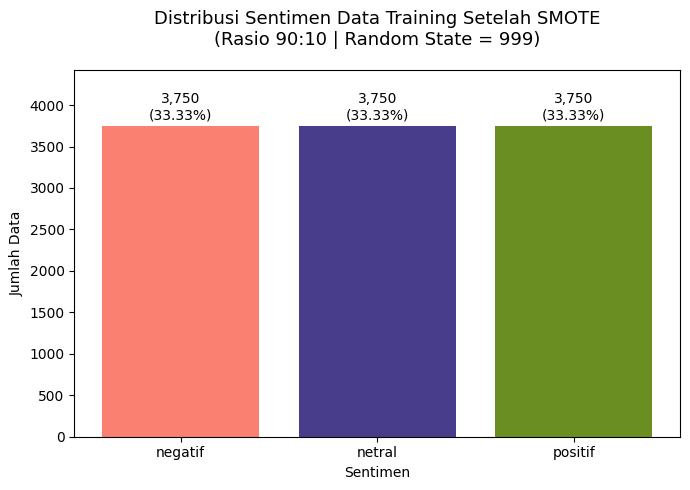

In [ ]:
# ==========================================================
# VISUALISASI DISTRIBUSI SENTIMEN SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Hitung jumlah data setiap kelas
jumlah_smote_9010_999 = pd.Series(y_train_smote_9010_999).value_counts()

# Urutkan label
jumlah_smote_9010_999 = jumlah_smote_9010_999.reindex(
    ['negatif', 'netral', 'positif']
)

# Hitung persentase
persentase_smote_9010_999 = (
    jumlah_smote_9010_999 / jumlah_smote_9010_999.sum()
) * 100

# Tabel distribusi
hasil_smote_9010_999 = pd.DataFrame({
    'Jumlah': jumlah_smote_9010_999,
    'Persentase (%)': persentase_smote_9010_999.round(2)
})

print(hasil_smote_9010_999)

# ==========================================================
# VISUALISASI
# ==========================================================

plt.figure(figsize=(7,5))

bars = plt.bar(
    jumlah_smote_9010_999.index,
    jumlah_smote_9010_999.values,
    color=['salmon', 'darkslateblue', 'olivedrab']
)

# Tambahkan ruang di atas batang
plt.ylim(0, max(jumlah_smote_9010_999) * 1.18)

plt.xlabel("Sentimen")
plt.ylabel("Jumlah Data")

plt.title(
    "Distribusi Sentimen Data Training Setelah SMOTE\n"
    "(Rasio 90:10 | Random State = 999)",
    fontsize=13,
    pad=18
)

# Label jumlah dan persentase
for bar, jumlah, persen in zip(
    bars,
    jumlah_smote_9010_999,
    persentase_smote_9010_999
):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 40,
        f"{jumlah:,}\n({persen:.2f}%)",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()

# SVM+SMOTE

# 90:10

# Random State 42

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE (90:10)
# RANDOM STATE = 42
# ==========================================================

svm_smote = SVC(kernel='linear')

param_grid_smote = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_9010_42 = GridSearchCV(
    svm_smote,
    param_grid_smote,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_9010_42.fit(X_train_tfidf_smote_9010_42, y_train_smote_9010_42)

print("Best Parameter Setelah SMOTE (90:10) RS 42 :", grid_search_smote_9010_42.best_params_)

Best Parameter Setelah SMOTE (90:10) RS 42 : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

hasil_tuning_smote_9010_42 = pd.DataFrame(
    grid_search_smote_9010_42.cv_results_
)

hasil_tuning_smote_9010_42 = hasil_tuning_smote_9010_42[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_9010_42.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_9010_42.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.784332  0.021244        6
1  0.3       0.877362  0.020009        5
2  0.5       0.906135  0.021543        4
3  1.0       0.936661  0.012750        3
4  3.0       0.957984  0.009354        2
5  5.0       0.965032  0.006635        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "90:10"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_9010_42, y_train_smote_9010_42)

    support_indices = svm_model.support_
    y_sv = y_train_smote_9010_42.iloc[support_indices] if hasattr(y_train_smote_9010_42, "iloc") else y_train_smote_9010_42[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data pasangan kelas
        mask_pair = (y_train_smote_9010_42 == kelas1) | (y_train_smote_9010_42 == kelas2)
        y_pair = y_train_smote_9010_42[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info_smote.append({
            'Rasio': rasio,
            'Random State': 42,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_smote_9010_42 = pd.DataFrame(model_info_smote)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_9010_42)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,90:10,42,5,negatif vs netral,3750,3750,1178,1552,2730,-0.970134,"[suap, kategori, kurung, asn, beras, matar, in...","[8.201364904516026, -5.702720702481315, -5.613..."
1,90:10,42,5,negatif vs positif,3750,3750,1178,812,1990,0.554497,"[suap, rawat, kategori, kurung, matar, asn, gv...","[5.552505674718461, -4.1225879479730665, -4.07..."
2,90:10,42,5,netral vs positif,3750,3750,1552,812,2364,1.644000,"[cpns, suap, kategori, kurung, matar, gvv, ban...","[-7.770634768213812, 7.654802489800886, -5.937..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi UNTUK SVM SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5
def summarize_2d_for_display(arr, n_rows=5, n_cols=10):

    n_total_rows, n_total_cols = arr.shape
    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []

    for r in row_indices:

        row = arr[r]

        if n_total_cols <= n_cols:
            summarized.append(row)

        else:
            summarized.append(
                np.concatenate([row[:n_cols//2],
                                ['...'],
                                row[-n_cols//2:]])
            )

    return np.array(summarized)


def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr

    return np.concatenate([arr[:n], ['...'], arr[-n:]])


for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_9010_42 == kelas1) | (y_train_smote_9010_42 == kelas2)

    X_pair = X_train_tfidf_smote_9010_42[mask_pair.to_numpy()]
    y_pair = y_train_smote_9010_42[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n"+"="*80+"\n")

=== Model Biner : negatif vs netral ===

α_i = ['-0.0012516037030020897' '-5.0' '-1.699778191938451'
 '-1.9701731858040905' '-2.7281578017352976' '...' '5.0' '5.0'
 '0.5802291945931067' '4.904672560986604' '0.7004595934992571']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.9701


=== Model Biner : negatif vs positif ===

α_i = ['-1.4644147801440668' '-0.44596574642435033' '-3.1910627268038283'
 '-3.618762829243794' '-0.4456929740564273' '...' '0.34011196232659796'
 '0.5722548620355445' '0.06892963146994005' '5.0' '1.9839093735784714']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.

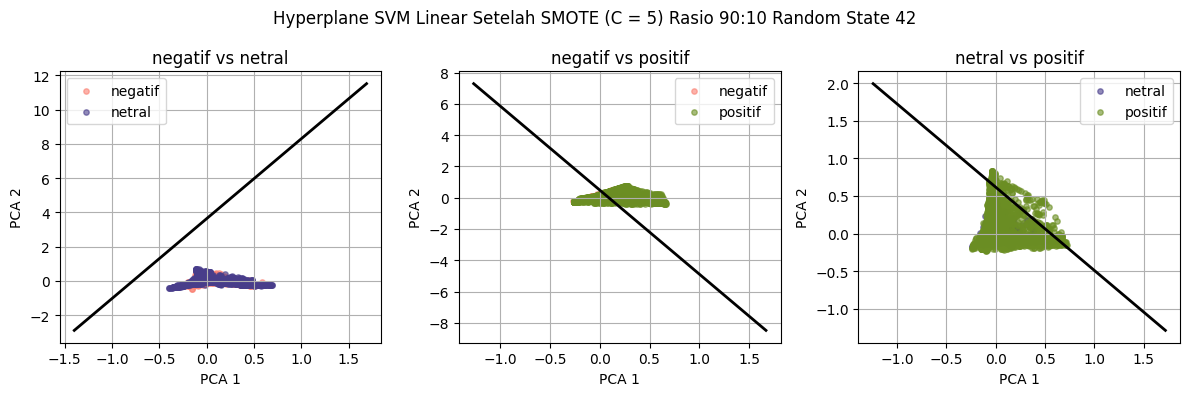

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 42
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.decomposition import PCA
import numpy as np

colors = {
    'negatif': 'salmon',
    'netral': 'darkslateblue',
    'positif': 'olivedrab'
}

pairs = [
    ('negatif','netral'),
    ('negatif','positif'),
    ('netral','positif')
]

C_val = [5]
rasio = "90:10"

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(
        X_train_tfidf_smote_9010_42,
        y_train_smote_9010_42
    )

    fig, axes = plt.subplots(1,3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        mask_train = (
            (y_train_smote_9010_42 == kelas1) |
            (y_train_smote_9010_42 == kelas2)
        )

        X_pair = X_train_tfidf_smote_9010_42[mask_train.to_numpy()]
        y_pair = y_train_smote_9010_42[mask_train]

        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        w_pca = pca.components_ @ w

        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals = np.linspace(X_pca[:,0].min()-1,
                             X_pca[:,0].max()+1,
                             200)

        if w_pca[1] != 0:
            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0], color='k', linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
        ax.grid(True)
        ax.legend()

    plt.suptitle(f'Hyperplane SVM Linear Setelah SMOTE (C = {C_val}) Rasio {rasio} Random State 42')

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

C_val = [5]
hasil_evaluasi_smote_9010_42 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_9010_42, y_train_smote_9010_42)

    y_pred = svm_model.predict(X_test_tfidf_9010_42)

    print(f"\n--- HASIL PREDIKSI SVM SETELAH SMOTE (90:10) RANDOM STATE 42 C = {C_val} ---")

    hasil_prediksi_svm_smote_9010_42 = pd.DataFrame({
        'teks_tweet': X_test_9010_42,
        'label_aktual': y_test_9010_42,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_smote_9010_42)

    accuracy = accuracy_score(y_test_9010_42, y_pred)
    precision = precision_score(y_test_9010_42, y_pred, average='macro')
    sensitivity = recall_score(y_test_9010_42, y_pred, average='macro')
    f1 = f1_score(y_test_9010_42, y_pred, average='macro')

    hasil_evaluasi_smote_9010_42.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM SETELAH SMOTE (90:10) RANDOM STATE 42 ---")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Sensitivity:", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n",
          confusion_matrix(y_test_9010_42, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_9010_42, y_pred, target_names=labels))


--- HASIL PREDIKSI SVM SETELAH SMOTE (90:10) RANDOM STATE 42 C = 5 ---
                                             teks_tweet label_aktual  \
1721  wfh laksana nya perintah ketidakpercayaan laks...       netral   
5862                                         suka kelen      negatif   
1257     tolong anak sekolah jangan daring kacau daring      negatif   
773   enak banget ngomong tidak kerja pecat tutup ti...      negatif   
4659  kocak nih perintah tidak atur beli bensin lite...      negatif   
...                                                 ...          ...   
5988  atur nya tidak jelas tai atur susah supir eksp...      negatif   
1675                    layan hotel restoran ajak tidak      negatif   
3393                          cabut alokasi mobil dinas       netral   
4196                            tidak akal nya perintah      negatif   
1044  gaji jabat mohon tinjau ulang dpr pimpin kepal...      negatif   

     label_prediksi  
1721         netral  
5862        negatif

# random state 123

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE (90:10)
# RANDOM STATE = 123
# ==========================================================

svm_smote = SVC(kernel='linear')

param_grid_smote = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_9010_123 = GridSearchCV(
    svm_smote,
    param_grid_smote,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_9010_123.fit(X_train_tfidf_smote_9010_123, y_train_smote_9010_123)

print("Best Parameter Setelah SMOTE (90:10) RS 123 :", grid_search_smote_9010_123.best_params_)

Best Parameter Setelah SMOTE (90:10) RS 123 : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

hasil_tuning_smote_9010_123 = pd.DataFrame(
    grid_search_smote_9010_123.cv_results_
)

hasil_tuning_smote_9010_123 = hasil_tuning_smote_9010_123[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_9010_123.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_9010_123.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.781977  0.023352        6
1  0.3       0.877961  0.022217        5
2  0.5       0.904348  0.021413        4
3  1.0       0.934389  0.017011        3
4  3.0       0.956933  0.011344        2
5  5.0       0.962839  0.008954        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "90:10"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_9010_123, y_train_smote_9010_123)

    support_indices = svm_model.support_
    y_sv = y_train_smote_9010_123.iloc[support_indices] if hasattr(y_train_smote_9010_123, "iloc") else y_train_smote_9010_123[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_9010_123 == kelas1) | (y_train_smote_9010_123 == kelas2)
        y_pair = y_train_smote_9010_123[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote.append({
            'Rasio': rasio,
            'Random State':123,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_9010_123 = pd.DataFrame(model_info_smote)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_9010_123)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,90:10,123,5,negatif vs netral,3750,3750,1168,1527,2695,-0.963959,"[sutarto, kejakarta, lancar, asoy, guru, memng...","[8.34549596397602, -5.805623617785145, -5.7729..."
1,90:10,123,5,negatif vs positif,3750,3750,1168,820,1988,0.529978,"[sutarto, kejakarta, revisi, iri, lancar, memn...","[5.430523616426811, -4.12355436494807, -3.9869..."
2,90:10,123,5,netral vs positif,3750,3750,1527,820,2347,1.552182,"[sutarto, cuy, kejakarta, lancar, memngendarai...","[7.925963696782887, -7.302025521319843, -5.988..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi UNTUK SVM SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_9010_123 == kelas1) | (y_train_smote_9010_123 == kelas2)

    X_pair = X_train_tfidf_smote_9010_123[mask_pair.to_numpy()]
    y_pair = y_train_smote_9010_123[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n"+"="*80+"\n")

=== Model Biner : negatif vs netral ===

α_i = ['-1.3798983359415984' '-0.5298250187146561' '-1.7009762381657636' '-5.0'
 '-2.280442366425852' '...' '1.1693703202131698' '1.531942053673257'
 '1.0851050919183358' '1.4756227727704334' '2.8256328389737706']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.964


=== Model Biner : negatif vs positif ===

α_i = ['-0.7981159682779444' '-0.535768794081295' '-1.7259052934311152'
 '-1.3284772060890957' '-0.5633945979057928' '...' '0.0009175633970355823'
 '1.1585667112644946' '0.6246908941456671' '0.42100493261478195'
 '0.3244510638646803']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =

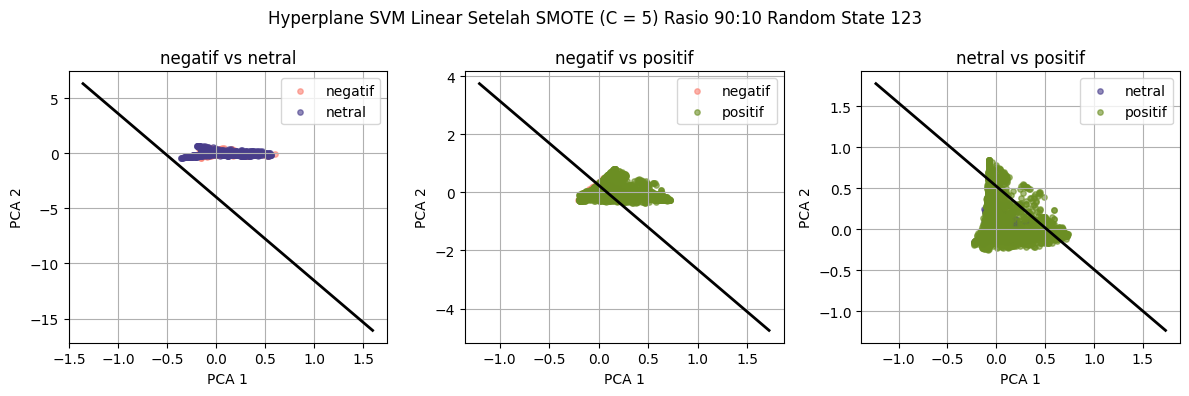

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 123
# ==========================================================

colors = {
    'negatif': 'salmon',
    'netral': 'darkslateblue',
    'positif': 'olivedrab'
}

pairs = [
    ('negatif','netral'),
    ('negatif','positif'),
    ('netral','positif')
]

C_val = [5]
rasio = "90:10"

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(
        X_train_tfidf_smote_9010_123,
        y_train_smote_9010_123
    )

    fig, axes = plt.subplots(1,3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        mask_train = (
            (y_train_smote_9010_123 == kelas1) |
            (y_train_smote_9010_123 == kelas2)
        )

        X_pair = X_train_tfidf_smote_9010_123[mask_train.to_numpy()]
        y_pair = y_train_smote_9010_123[mask_train]

        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        w_pca = pca.components_ @ w

        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals = np.linspace(X_pca[:,0].min()-1,
                             X_pca[:,0].max()+1,
                             200)

        if w_pca[1] != 0:
            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0], color='k', linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
        ax.grid(True)
        ax.legend()

    plt.suptitle(f'Hyperplane SVM Linear Setelah SMOTE (C = {C_val}) Rasio {rasio} Random State 123')

    plt.tight_layout()
    plt.show()

In [ ]:
C_val = [5]
hasil_evaluasi_smote_9010_123 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_9010_123, y_train_smote_9010_123)

    y_pred = svm_model.predict(X_test_tfidf_9010_123)

    print(f"\n--- HASIL PREDIKSI SVM SETELAH SMOTE (90:10) RANDOM STATE 123 C = {C_val} ---")

    hasil_prediksi_svm_smote_9010_123 = pd.DataFrame({
        'teks_tweet': X_test_9010_123,
        'label_aktual': y_test_9010_123,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_smote_9010_123)

    accuracy = accuracy_score(y_test_9010_123, y_pred)
    precision = precision_score(y_test_9010_123, y_pred, average='macro')
    sensitivity = recall_score(y_test_9010_123, y_pred, average='macro')
    f1 = f1_score(y_test_9010_123, y_pred, average='macro')

    hasil_evaluasi_smote_9010_123.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM SETELAH SMOTE (90:10) RANDOM STATE 123 ---")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Sensitivity:", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n",
          confusion_matrix(y_test_9010_123, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_9010_123, y_pred, target_names=labels))


--- HASIL PREDIKSI SVM SETELAH SMOTE (90:10) RANDOM STATE 123 C = 5 ---
                                             teks_tweet label_aktual  \
5163  tidak jelas arah perintah mobil truk trayek wo...      negatif   
874   stop mbg alih urgensi didik sehat wfh tidak ef...      negatif   
4929                       truk ekspedisi liter jakarta       netral   
6366                batas tunjang menteri dpr jabat nya      negatif   
3637  konsumsi bbm setir wajar hari tidak kemarin de...      negatif   
...                                                 ...          ...   
6215                                         kurang mbg      negatif   
4063                                   jakarta surabaya       netral   
457   opsi sepeda becak delman delman daerah kendara...       netral   
5995                            susah susah susah rezim      negatif   
3441                  asah otak pulih udah kasih daring      negatif   

     label_prediksi  
5163        negatif  
874         negati

#Random state 999

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE (90:10)
# RANDOM STATE = 999
# ==========================================================

svm_smote = SVC(kernel='linear')

param_grid_smote = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_9010_999 = GridSearchCV(
    svm_smote,
    param_grid_smote,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_9010_999.fit(X_train_tfidf_smote_9010_999, y_train_smote_9010_999)

print("Best Parameter Setelah SMOTE (90:10) RS 999 :", grid_search_smote_9010_999.best_params_)

Best Parameter Setelah SMOTE (90:10) RS 999 : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

hasil_tuning_smote_9010_999 = pd.DataFrame(
    grid_search_smote_9010_999.cv_results_
)

hasil_tuning_smote_9010_999 = hasil_tuning_smote_9010_999[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_9010_999.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_9010_999.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.778866  0.018434        6
1  0.3       0.877602  0.020566        5
2  0.5       0.906453  0.018202        4
3  1.0       0.935713  0.013003        3
4  3.0       0.959282  0.009682        2
5  5.0       0.965489  0.006741        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "90:10"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_9010_999, y_train_smote_9010_999)

    support_indices = svm_model.support_
    y_sv = y_train_smote_9010_999.iloc[support_indices] if hasattr(y_train_smote_9010_999, "iloc") else y_train_smote_9010_999[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_9010_999 == kelas1) | (y_train_smote_9010_999 == kelas2)
        y_pair = y_train_smote_9010_999[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote.append({
            'Rasio': rasio,
            'Random State':999,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_9010_999 = pd.DataFrame(model_info_smote)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_9010_999)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,90:10,999,5,negatif vs netral,3750,3750,1215,1541,2756,-0.969409,"[syukur, kejakarta, langsir, asumsi, membutuhk...","[8.30588535287113, -5.781565222272363, -5.7645..."
1,90:10,999,5,negatif vs positif,3750,3750,1215,895,2110,0.524122,"[syukur, kejakarta, asumsi, rill, langsir, mem...","[5.34507695021756, -4.043062379136558, 3.91187..."
2,90:10,999,5,netral vs positif,3750,3750,1541,895,2436,1.600580,"[syukur, dahsyat, kejakarta, langsir, basar, m...","[7.862989785300471, -7.062844131108635, -6.042..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi UNTUK SVM SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5
for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_9010_999 == kelas1) | (y_train_smote_9010_999 == kelas2)

    X_pair = X_train_tfidf_smote_9010_999[mask_pair.to_numpy()]
    y_pair = y_train_smote_9010_999[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai,5)
    yi_summarized = summarize_1d(yi,5)
    xi_summarized = summarize_2d_for_display(xi,5,10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n"+"="*80+"\n")

=== Model Biner : negatif vs netral ===

α_i = ['-0.4890437234255939' '-1.18758559516632' '-0.3374209730735768'
 '-2.164941598896166' '-2.237725728059556' '...' '0.7533605490567906'
 '0.5953354168612528' '2.764556819630676' '5.0' '0.6715386547750196']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.9694


=== Model Biner : negatif vs positif ===

α_i = ['-0.40572009672244036' '-0.47596246715450147' '-3.7460449424583127'
 '-1.0758360057871341' '-0.6598641057774747' '...' '1.4582497085019468'
 '0.06323538197101655' '3.1855930414682785' '0.9394332500675084'
 '0.30661717368765184']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =


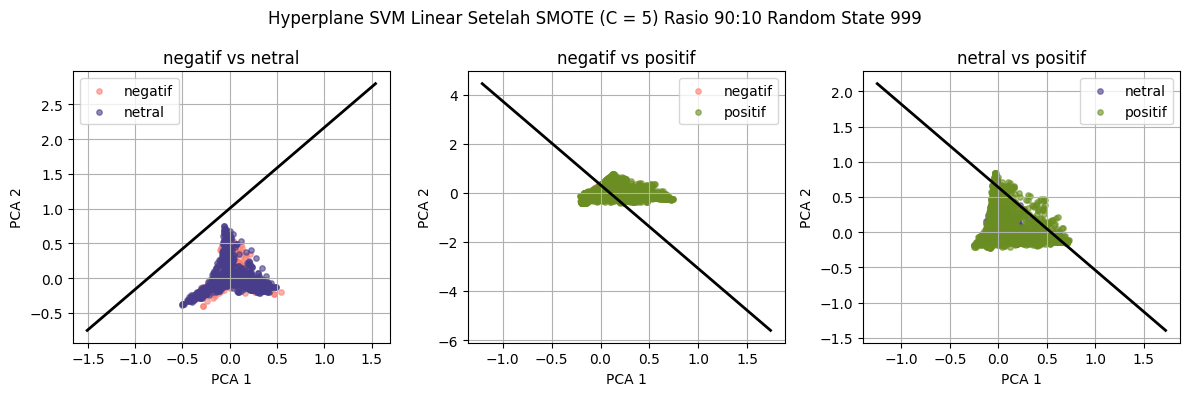

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 90:10
# RANDOM STATE = 999
# ==========================================================

colors = {
    'negatif': 'salmon',
    'netral': 'darkslateblue',
    'positif': 'olivedrab'
}

pairs = [
    ('negatif','netral'),
    ('negatif','positif'),
    ('netral','positif')
]

C_val = [5]
rasio = "90:10"

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(
        X_train_tfidf_smote_9010_999,
        y_train_smote_9010_999
    )

    fig, axes = plt.subplots(1,3, figsize=(12,4))

    for i, (kelas1, kelas2) in enumerate(pairs):

        ax = axes[i]

        mask_train = (
            (y_train_smote_9010_999 == kelas1) |
            (y_train_smote_9010_999 == kelas2)
        )

        X_pair = X_train_tfidf_smote_9010_999[mask_train.to_numpy()]
        y_pair = y_train_smote_9010_999[mask_train]

        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        w_pca = pca.components_ @ w

        for label in [kelas1, kelas2]:

            mask_plot = (y_pair == label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals = np.linspace(X_pca[:,0].min()-1,
                             X_pca[:,0].max()+1,
                             200)

        if w_pca[1] != 0:
            y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
            ax.plot(x_vals, y_vals, 'k-', linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0], color='k', linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
        ax.grid(True)
        ax.legend()

    plt.suptitle(f'Hyperplane SVM Linear Setelah SMOTE (C = {C_val}) Rasio {rasio} Random State 999')

    plt.tight_layout()
    plt.show()

In [ ]:
C_val = [5]
hasil_evaluasi_smote_9010_999 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_9010_999, y_train_smote_9010_999)

    y_pred = svm_model.predict(X_test_tfidf_9010_999)

    print(f"\n--- HASIL PREDIKSI SVM SETELAH SMOTE (90:10) RANDOM STATE 999 C = {C_val} ---")

    hasil_prediksi_svm_smote_9010_999 = pd.DataFrame({
        'teks_tweet': X_test_9010_999,
        'label_aktual': y_test_9010_999,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_smote_9010_999)

    accuracy = accuracy_score(y_test_9010_999, y_pred)
    precision = precision_score(y_test_9010_999, y_pred, average='macro')
    sensitivity = recall_score(y_test_9010_999, y_pred, average='macro')
    f1 = f1_score(y_test_9010_999, y_pred, average='macro')

    hasil_evaluasi_smote_9010_999.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Sensitivity': sensitivity,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI SVM SETELAH SMOTE (90:10) RANDOM STATE 999 ---")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Sensitivity:", sensitivity)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n",
          confusion_matrix(y_test_9010_999, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_9010_999, y_pred, target_names=labels))


--- HASIL PREDIKSI SVM SETELAH SMOTE (90:10) RANDOM STATE 999 C = 5 ---
                                             teks_tweet label_aktual  \
38    tolong jangan bilang anak sekolah ajar daring ...      negatif   
4439  liter kendara tidak laku kendara truk plat hit...      negatif   
930                    aduh hemat bbm stop jual kendara      negatif   
3196                         jujur jujuran jabat konyol      negatif   
111                                   bijak tidak bijak      negatif   
...                                                 ...          ...   
4948                                       kalang kabut      negatif   
469   hemat laku mobil minimal orang liburin jalan j...      negatif   
4419  terlalu atur bijak kabinet susah masyarakat pa...      negatif   
3720  suami supir lintas jawa sumatera gaji tim alok...      negatif   
6088                                    tidak cok liter      negatif   

     label_prediksi  
38          negatif  
4439        negati

# 80:20

# Random State 42

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

svm_smote_8020_42 = SVC(kernel='linear')

param_grid_smote_8020_42 = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_8020_42 = GridSearchCV(
    svm_smote_8020_42,
    param_grid_smote_8020_42,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_8020_42.fit(
    X_train_tfidf_smote_8020_42,
    y_train_smote_8020_42
)

print("Best Parameter Setelah SMOTE :", grid_search_smote_8020_42.best_params_)

best_C_smote_8020_42 = grid_search_smote_8020_42.best_params_['C']

Best Parameter Setelah SMOTE : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

hasil_tuning_smote_8020_42 = pd.DataFrame(
    grid_search_smote_8020_42.cv_results_
)

hasil_tuning_smote_8020_42 = hasil_tuning_smote_8020_42[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_8020_42.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_8020_42.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.784357  0.019656        6
1  0.3       0.875037  0.023404        5
2  0.5       0.902003  0.022660        4
3  1.0       0.932700  0.018952        3
4  3.0       0.954210  0.010995        2
5  5.0       0.961023  0.009078        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "80:20"

# ambil nama fitur (kata) dari TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_8020_42, y_train_smote_8020_42)

    support_indices = svm_model.support_
    y_sv = y_train_smote_8020_42.iloc[support_indices] if hasattr(y_train_smote_8020_42, "iloc") else y_train_smote_8020_42[support_indices]

    w_matrix = svm_model.coef_
    b_vector = svm_model.intercept_
    n_support = svm_model.n_support_

    for i, (kelas1, kelas2) in enumerate(pairs):

        # jumlah support vector tiap kelas
        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        # subset data pasangan kelas
        mask_pair = (y_train_smote_8020_42 == kelas1) | (y_train_smote_8020_42 == kelas2)
        y_pair = y_train_smote_8020_42[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        # bobot w dan bias
        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        # Top 10 fitur
        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        top_features_words = feature_names[top_idx]
        top_w_vector = w_dense[top_idx]

        model_info_smote.append({
            'Rasio': rasio,
            'Random State': 42,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(top_features_words),
            'Top 10 Bobot w': list(top_w_vector)
        })

df_model_info_smote_8020_42 = pd.DataFrame(model_info_smote)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_8020_42)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,80:20,42,5,negatif vs netral,3333,3333,1101,1398,2499,-0.920331,"[setan, kacaw, komputer, long, asek, garasi, h...","[7.873368406361578, -5.527247674215388, -5.365..."
1,80:20,42,5,negatif vs positif,3333,3333,1101,759,1860,0.520768,"[setan, kacaw, polos, komputer, long, honor, b...","[5.467641910510132, -3.8969929089675546, -3.88..."
2,80:20,42,5,netral vs positif,3333,3333,1398,759,2157,1.581451,"[ciu, setan, kacaw, bangun, komputer, long, as...","[-7.542907153165421, 7.263025733263582, -5.668..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi UNTUK SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

import numpy as np
from scipy.sparse import issparse

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5


def summarize_2d_for_display(arr, n_rows=5, n_cols=10):

    n_total_rows, n_total_cols = arr.shape
    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []

    for r in row_indices:

        row = arr[r]

        if n_total_cols <= n_cols:
            summarized.append(row)

        else:
            summarized.append(
                np.concatenate([row[:n_cols//2],
                                ['...'],
                                row[-n_cols//2:]])
            )

    return np.array(summarized)


def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr

    return np.concatenate([arr[:n], ['...'], arr[-n:]])


for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_8020_42 == kelas1) | (y_train_smote_8020_42 == kelas2)

    X_pair = X_train_tfidf_smote_8020_42[mask_pair.to_numpy()]
    y_pair = y_train_smote_8020_42[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)
    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n" + "="*80 + "\n")

=== Model Biner : negatif vs netral ===

α_i = ['-1.665847730851552' '-5.0' '-0.713390268769776' '-5.0'
 '-0.6701942352678506' '...' '1.9709864744671706' '5.0' '5.0'
 '2.215228993882744' '1.5336786161210412']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.9203


=== Model Biner : negatif vs positif ===

α_i = ['-1.464501950460616' '-2.061383882787311' '-0.08906424431903907'
 '-1.9460088868065735' '-0.33148696306245773' '...' '0.08896880589208989'
 '0.25384995827940127' '0.1920761633070716' '1.3256552077543307'
 '0.3709424389547059']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0

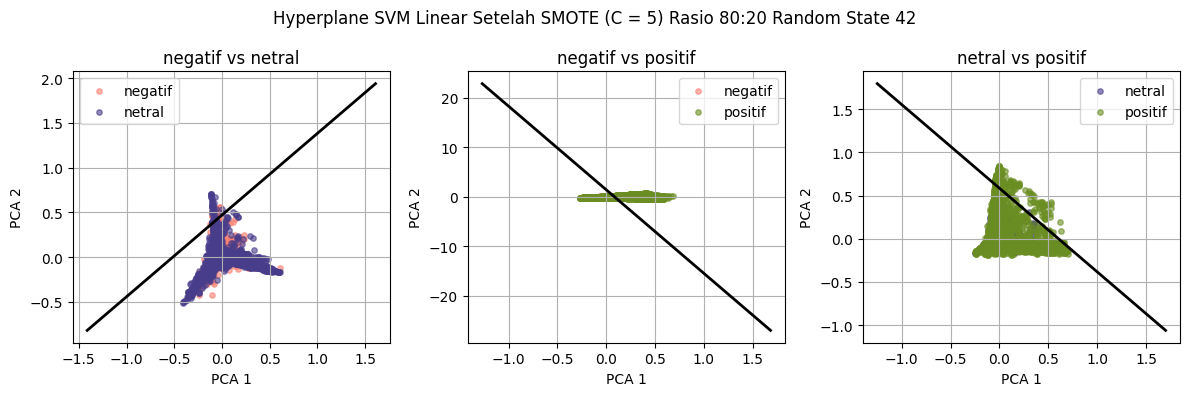

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.decomposition import PCA
import numpy as np

colors = {
    'negatif': 'salmon',
    'netral': 'darkslateblue',
    'positif': 'olivedrab'
}

pairs = [
    ('negatif','netral'),
    ('negatif','positif'),
    ('netral','positif')
]

C_val = [5]
rasio = "80:20"

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(
        X_train_tfidf_smote_8020_42,
        y_train_smote_8020_42
    )

    fig, axes = plt.subplots(1,3,figsize=(12,4))

    for i,(kelas1,kelas2) in enumerate(pairs):

        ax = axes[i]

        mask_train = (
            (y_train_smote_8020_42==kelas1) |
            (y_train_smote_8020_42==kelas2)
        )

        X_pair = X_train_tfidf_smote_8020_42[mask_train.to_numpy()]
        y_pair = y_train_smote_8020_42[mask_train]

        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_pair.toarray())

        w = svm_model.coef_[i].toarray().flatten()
        b = svm_model.intercept_[i]

        w_pca = pca.components_ @ w

        for label in [kelas1,kelas2]:

            mask_plot = (y_pair==label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals = np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1] != 0:

            y_vals = -(w_pca[0]*x_vals+b)/w_pca[1]
            ax.plot(x_vals,y_vals,'k-',linewidth=2)

        else:

            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel('PCA 1')
        ax.set_ylabel('PCA 2')
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear Setelah SMOTE (C = {C_val}) Rasio {rasio} Random State 42'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ==========================================================
# PREDIKSI DAN EVALUASI SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 42
# ==========================================================

import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

C_val = [5]

hasil_evaluasi_smote_8020_42 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)

    svm_model.fit(
        X_train_tfidf_smote_8020_42,
        y_train_smote_8020_42
    )

    y_pred = svm_model.predict(X_test_tfidf_8020_42)

    print(f"\n--- HASIL PREDIKSI SVM SETELAH SMOTE (80:20) RANDOM STATE 42 C = {C_val} ---")

    hasil_prediksi_svm_smote_8020_42 = pd.DataFrame({
        'teks_tweet': X_test_8020_42,
        'label_aktual': y_test_8020_42,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_smote_8020_42)

    accuracy = accuracy_score(y_test_8020_42,y_pred)
    precision = precision_score(y_test_8020_42,y_pred,average='macro')
    sensitivity = recall_score(y_test_8020_42,y_pred,average='macro')
    f1 = f1_score(y_test_8020_42,y_pred,average='macro')

    hasil_evaluasi_smote_8020_42.append({

        'C':C_val,
        'Accuracy':accuracy,
        'Precision':precision,
        'Sensitivity':sensitivity,
        'F1-Score':f1

    })

    print(f"\n--- EVALUASI SVM SETELAH SMOTE (80:20) RANDOM STATE 42 C = {C_val} ---")

    print("Accuracy :",accuracy)
    print("Precision :",precision)
    print("Sensitivity :",sensitivity)
    print("F1-Score :",f1)

    print("\nConfusion Matrix")
    print(confusion_matrix(
        y_test_8020_42,
        y_pred,
        labels=labels
    ))

    print("\nClassification Report")
    print(classification_report(
        y_test_8020_42,
        y_pred,
        target_names=labels
    ))


--- HASIL PREDIKSI SVM SETELAH SMOTE (80:20) RANDOM STATE 42 C = 5 ---
                                             teks_tweet label_aktual  \
993         wfh kerja pakai komputer laptop teman teman      positif   
4493                          liter tidak mobil pribadi       netral   
3082                            tidak daring ibu daring      positif   
2021   tolong pengaruh kurang paham butuh jelas perinci      negatif   
1123                                     bumc tidak min      negatif   
...                                                 ...          ...   
2828  jangan hak karyawan doang bos hak usaha langsu...      negatif   
4248  tambah geopolitik tidak sesuai dampak indonesi...      negatif   
4519                                              panik      negatif   
5907                              kota aduh kasihan bos      negatif   
4192                                     sesal milihnya      negatif   

     label_prediksi  
993         positif  
4493         netral

# Random State 123

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

svm_smote_8020_123 = SVC(kernel='linear')

param_grid_smote_8020_123 = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_8020_123 = GridSearchCV(
    svm_smote_8020_123,
    param_grid_smote_8020_123,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_8020_123.fit(
    X_train_tfidf_smote_8020_123,
    y_train_smote_8020_123
)

print("Best Parameter Setelah SMOTE :", grid_search_smote_8020_123.best_params_)

best_C_smote_8020_123 = grid_search_smote_8020_123.best_params_['C']

Best Parameter Setelah SMOTE : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

hasil_tuning_smote_8020_123 = pd.DataFrame(
    grid_search_smote_8020_123.cv_results_
)

hasil_tuning_smote_8020_123 = hasil_tuning_smote_8020_123[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_8020_123.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_8020_123.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.774850  0.022785        6
1  0.3       0.873064  0.025850        5
2  0.5       0.908064  0.023824        4
3  1.0       0.934963  0.018131        3
4  3.0       0.956884  0.010107        2
5  5.0       0.962876  0.008553        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "80:20"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_8020_123, y_train_smote_8020_123)

    support_indices = svm_model.support_
    y_sv = y_train_smote_8020_123.iloc[support_indices] if hasattr(y_train_smote_8020_123, "iloc") else y_train_smote_8020_123[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_8020_123 == kelas1) | (y_train_smote_8020_123 == kelas2)
        y_pair = y_train_smote_8020_123[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote.append({
            'Rasio': rasio,
            'Random State':123,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_8020_123 = pd.DataFrame(model_info_smote)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_8020_123)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,80:20,123,5,negatif vs netral,3333,3333,1087,1415,2502,-0.838353,"[siburuh, kontainer, kakehan, asek, macimal, b...","[8.039144431791769, -5.853369831417567, -5.741..."
1,80:20,123,5,negatif vs positif,3333,3333,1087,781,1868,0.538983,"[siburuh, pra, ice, kakehan, kontainer, macima...","[5.337923702173825, -4.178883587515493, 3.9530..."
2,80:20,123,5,netral vs positif,3333,3333,1415,781,2196,1.536560,"[convert, siburuh, kakehan, kontainer, bank, m...","[-7.5597566960835785, 7.317120110666899, -5.61..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi UNTUK SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_8020_123 == kelas1) | (y_train_smote_8020_123 == kelas2)

    X_pair = X_train_tfidf_smote_8020_123[mask_pair.to_numpy()]
    y_pair = y_train_smote_8020_123[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)
    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n" + "="*80 + "\n")

=== Model Biner : negatif vs netral ===

α_i = ['-0.34874769234259834' '-2.4535528865568716' '-4.814624165305405'
 '-1.6212422916630724' '-2.7947902760659358' '...' '2.9388288541161836'
 '4.649962267695376' '0.34441686047922976' '5.0' '5.0']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.8384


=== Model Biner : negatif vs positif ===

α_i = ['-0.11143380132320164' '-1.7123019730596771' '-2.4508747404351876'
 '-1.1087375878055947' '-0.08271969950788968' '...' '0.898594321550997'
 '3.901298475395085' '0.7191818227410025' '0.7806513801406634'
 '0.6004171337677011']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.

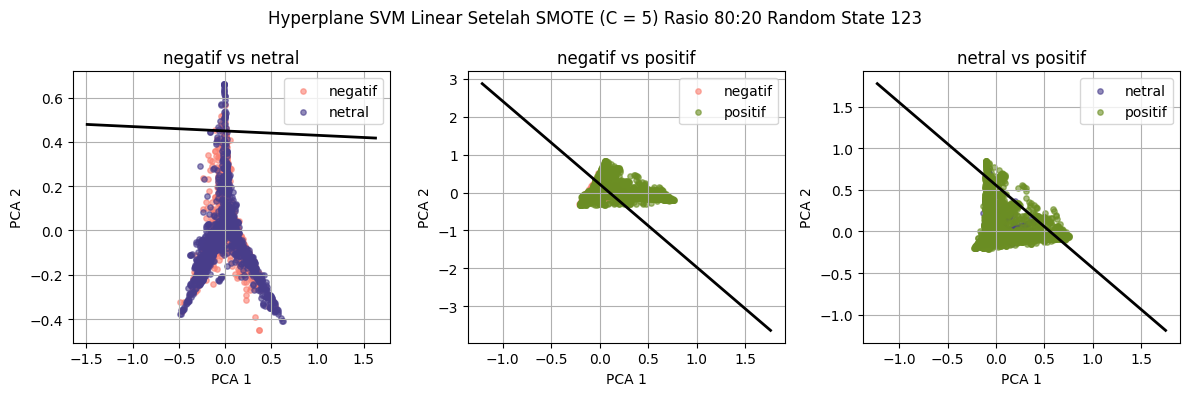

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

pairs = [
    ('negatif','netral'),
    ('negatif','positif'),
    ('netral','positif')
]

C_val = [5]
rasio = "80:20"

for C_val in C_val:

    svm_model = SVC(kernel='linear',C=C_val)
    svm_model.fit(
        X_train_tfidf_smote_8020_123,
        y_train_smote_8020_123
    )

    fig,axes=plt.subplots(1,3,figsize=(12,4))

    for i,(kelas1,kelas2) in enumerate(pairs):

        ax=axes[i]

        mask_train=(
            (y_train_smote_8020_123==kelas1)|
            (y_train_smote_8020_123==kelas2)
        )

        X_pair=X_train_tfidf_smote_8020_123[mask_train.to_numpy()]
        y_pair=y_train_smote_8020_123[mask_train]

        pca=PCA(n_components=2)
        X_pca=pca.fit_transform(X_pair.toarray())

        w=svm_model.coef_[i].toarray().flatten()
        b=svm_model.intercept_[i]

        w_pca=pca.components_@w

        for label in [kelas1,kelas2]:

            mask_plot=(y_pair==label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals=np.linspace(X_pca[:,0].min()-1,
                           X_pca[:,0].max()+1,
                           200)

        if w_pca[1]!=0:
            y_vals=-(w_pca[0]*x_vals+b)/w_pca[1]
            ax.plot(x_vals,y_vals,'k-',linewidth=2)
        else:
            ax.axvline(x=-b/w_pca[0],color='k',linewidth=2)

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear Setelah SMOTE (C = {C_val}) Rasio {rasio} Random State 123'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ==========================================================
# PREDIKSI DAN EVALUASI SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 123
# ==========================================================

C_val = [5]

hasil_evaluasi_smote_8020_123 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)

    svm_model.fit(
        X_train_tfidf_smote_8020_123,
        y_train_smote_8020_123
    )

    y_pred = svm_model.predict(X_test_tfidf_8020_123)

    print(f"\n--- HASIL PREDIKSI SVM SETELAH SMOTE (80:20) RANDOM STATE 123 C = {C_val} ---")

    hasil_prediksi_svm_smote_8020_123 = pd.DataFrame({
        'teks_tweet': X_test_8020_123,
        'label_aktual': y_test_8020_123,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_smote_8020_123)

    accuracy = accuracy_score(y_test_8020_123,y_pred)
    precision = precision_score(y_test_8020_123,y_pred,average='macro')
    sensitivity = recall_score(y_test_8020_123,y_pred,average='macro')
    f1 = f1_score(y_test_8020_123,y_pred,average='macro')

    hasil_evaluasi_smote_8020_123.append({

        'C':C_val,
        'Accuracy':accuracy,
        'Precision':precision,
        'Sensitivity':sensitivity,
        'F1-Score':f1

    })

    print(f"\n--- EVALUASI SVM SETELAH SMOTE (80:20) RANDOM STATE 123 C = {C_val} ---")

    print("Accuracy :",accuracy)
    print("Precision :",precision)
    print("Sensitivity :",sensitivity)
    print("F1-Score :",f1)

    print("\nConfusion Matrix")
    print(confusion_matrix(
        y_test_8020_123,
        y_pred,
        labels=labels
    ))

    print("\nClassification Report")
    print(classification_report(
        y_test_8020_123,
        y_pred,
        target_names=labels
    ))


--- HASIL PREDIKSI SVM SETELAH SMOTE (80:20) RANDOM STATE 123 C = 5 ---
                                             teks_tweet label_aktual  \
948                      heh jumat tanggal tanggal rabu      negatif   
5407                        amburadul era prabowo angel      negatif   
1434                                sticker stres stres      negatif   
358   maaf tidak efektif wfh mending pagawai anjur b...      negatif   
4058                                        banyak atur      negatif   
...                                                 ...          ...   
784                                 malas gebrak konyol      negatif   
3748                                        halah halah      negatif   
4020                                        susah orang      negatif   
3924   ibu ribu atur masalah minyak tidak mempan konoha      negatif   
1522         luccui perintah lucu wfh jumat pekan luccu       netral   

     label_prediksi  
948         negatif  
5407        negati

# Random State 999

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

svm_smote_8020_999 = SVC(kernel='linear')

param_grid_smote_8020_999 = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_8020_999 = GridSearchCV(
    svm_smote_8020_999,
    param_grid_smote_8020_999,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_8020_999.fit(
    X_train_tfidf_smote_8020_999,
    y_train_smote_8020_999
)

print("Best Parameter Setelah SMOTE :", grid_search_smote_8020_999.best_params_)

best_C_smote_8020_999 = grid_search_smote_8020_999.best_params_['C']

Best Parameter Setelah SMOTE : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

hasil_tuning_smote_8020_999 = pd.DataFrame(
    grid_search_smote_8020_999.cv_results_
)

hasil_tuning_smote_8020_999 = hasil_tuning_smote_8020_999[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_8020_999.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_8020_999.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.776098  0.017630        6
1  0.3       0.870296  0.024370        5
2  0.5       0.901581  0.022896        4
3  1.0       0.931351  0.018290        3
4  3.0       0.956439  0.012046        2
5  5.0       0.961591  0.009890        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "80:20"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_8020_999, y_train_smote_8020_999)

    support_indices = svm_model.support_
    y_sv = y_train_smote_8020_999.iloc[support_indices] if hasattr(y_train_smote_8020_999, "iloc") else y_train_smote_8020_999[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_8020_999 == kelas1) | (y_train_smote_8020_999 == kelas2)
        y_pair = y_train_smote_8020_999[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote.append({
            'Rasio': rasio,
            'Random State':999,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_8020_999 = pd.DataFrame(model_info_smote)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_8020_999)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,80:20,999,5,negatif vs netral,3333,3333,1115,1417,2532,-0.902075,"[skorsing, krl, asoy, kampret, maleh, berastag...","[7.887031419444682, -5.7446677533307025, 5.645..."
1,80:20,999,5,negatif vs positif,3333,3333,1115,814,1929,0.515844,"[skorsing, berastagi, kampret, krl, asoy, male...","[5.287770051979891, 3.8271751649456354, -3.812..."
2,80:20,999,5,netral vs positif,3333,3333,1417,814,2231,1.522569,"[skorsing, cost, kampret, beat, maleh, krl, ba...","[7.587503981418216, -7.313492952920461, -5.577..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi UNTUK SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_8020_999 == kelas1) | (y_train_smote_8020_999 == kelas2)

    X_pair = X_train_tfidf_smote_8020_999[mask_pair.to_numpy()]
    y_pair = y_train_smote_8020_999[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)
    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n" + "="*80 + "\n")

=== Model Biner : negatif vs netral ===

α_i = ['-5.0' '-5.0' '-5.0' '-5.0' '-0.7022751920609873' '...'
 '3.977802988402313' '4.6117518041362855' '2.7972636686849612' '5.0'
 '0.7848126133769291']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.9021


=== Model Biner : negatif vs positif ===

α_i = ['-1.3233970164769677' '-1.7808768652954232' '-0.44842948028601853'
 '-1.0138253459562419' '-0.33771806115234093' '...' '0.9283482651331976'
 '1.8016366148825744' '2.180932257951751' '3.654812852696499' '5.0']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 

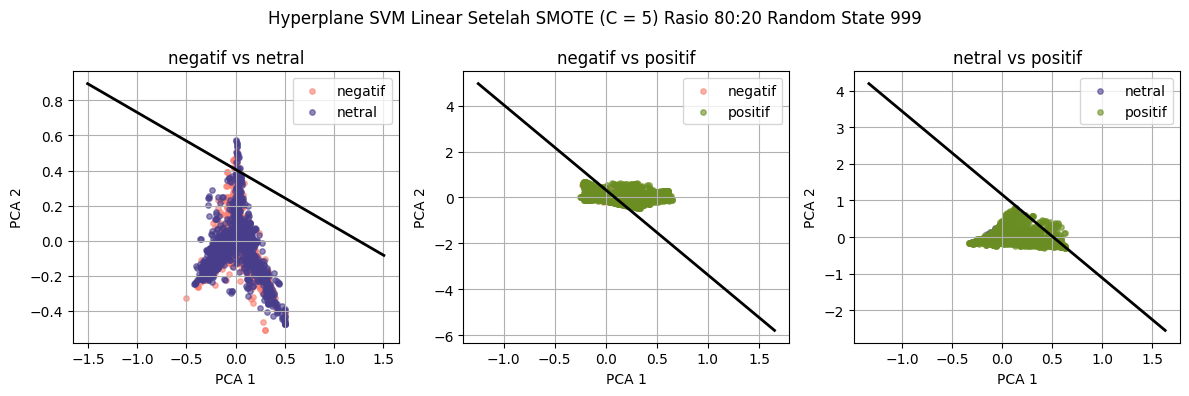

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

colors = {
    'negatif':'salmon',
    'netral':'darkslateblue',
    'positif':'olivedrab'
}

pairs=[
    ('negatif','netral'),
    ('negatif','positif'),
    ('netral','positif')
]

C_val=[5]
rasio="80:20"

for C_val in C_val:

    svm_model=SVC(kernel='linear',C=C_val)
    svm_model.fit(
        X_train_tfidf_smote_8020_999,
        y_train_smote_8020_999
    )

    fig,axes=plt.subplots(1,3,figsize=(12,4))

    for i,(kelas1,kelas2) in enumerate(pairs):

        ax=axes[i]

        mask_train=(
            (y_train_smote_8020_999==kelas1)|
            (y_train_smote_8020_999==kelas2)
        )

        X_pair=X_train_tfidf_smote_8020_999[mask_train.to_numpy()]
        y_pair=y_train_smote_8020_999[mask_train]

        pca=PCA(n_components=2)
        X_pca=pca.fit_transform(X_pair.toarray())

        w=svm_model.coef_[i].toarray().flatten()
        b=svm_model.intercept_[i]

        w_pca=pca.components_@w

        for label in [kelas1,kelas2]:

            mask_plot=(y_pair==label)

            ax.scatter(
                X_pca[mask_plot,0],
                X_pca[mask_plot,1],
                color=colors[label],
                label=label,
                alpha=0.6,
                s=15
            )

        x_vals=np.linspace(
            X_pca[:,0].min()-1,
            X_pca[:,0].max()+1,
            200
        )

        if w_pca[1]!=0:
            y_vals=-(w_pca[0]*x_vals+b)/w_pca[1]
            ax.plot(x_vals,y_vals,'k-',linewidth=2)
        else:
            ax.axvline(
                x=-b/w_pca[0],
                color='k',
                linewidth=2
            )

        ax.set_title(f'{kelas1} vs {kelas2}')
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")
        ax.grid(True)
        ax.legend()

    plt.suptitle(
        f'Hyperplane SVM Linear Setelah SMOTE (C = {C_val}) Rasio {rasio} Random State 999'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ==========================================================
# PREDIKSI DAN EVALUASI SVM SETELAH SMOTE
# RASIO 80:20
# RANDOM STATE = 999
# ==========================================================

C_val = [5]

hasil_evaluasi_smote_8020_999 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)

    svm_model.fit(
        X_train_tfidf_smote_8020_999,
        y_train_smote_8020_999
    )

    y_pred = svm_model.predict(X_test_tfidf_8020_999)

    print(f"\n--- HASIL PREDIKSI SVM SETELAH SMOTE (80:20) RANDOM STATE 999 C = {C_val} ---")

    hasil_prediksi_svm_smote_8020_999 = pd.DataFrame({
        'teks_tweet': X_test_8020_999,
        'label_aktual': y_test_8020_999,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_svm_smote_8020_999)

    accuracy = accuracy_score(y_test_8020_999,y_pred)
    precision = precision_score(y_test_8020_999,y_pred,average='macro')
    sensitivity = recall_score(y_test_8020_999,y_pred,average='macro')
    f1 = f1_score(y_test_8020_999,y_pred,average='macro')

    hasil_evaluasi_smote_8020_999.append({

        'C':C_val,
        'Accuracy':accuracy,
        'Precision':precision,
        'Sensitivity':sensitivity,
        'F1-Score':f1

    })

    print(f"\n--- EVALUASI SVM SETELAH SMOTE (80:20) RANDOM STATE 999 C = {C_val} ---")

    print("Accuracy :",accuracy)
    print("Precision :",precision)
    print("Sensitivity :",sensitivity)
    print("F1-Score :",f1)

    print("\nConfusion Matrix")
    print(confusion_matrix(
        y_test_8020_999,
        y_pred,
        labels=labels
    ))

    print("\nClassification Report")
    print(classification_report(
        y_test_8020_999,
        y_pred,
        target_names=labels
    ))


--- HASIL PREDIKSI SVM SETELAH SMOTE (80:20) RANDOM STATE 999 C = 5 ---
                                             teks_tweet label_aktual  \
2978                                    libur ayo jogja      positif   
3346                                         bodoh amat      positif   
643                                                pret       netral   
3994                               segitu hancur negeri      negatif   
1967  lalap lapor mana lapor mana kantor kalian tida...      positif   
...                                                 ...          ...   
2160            anak asn lebaran piket libur masuk jaga      negatif   
2738  ketemu guru langsung belum maksimal zaman covi...      positif   
4260                         mbg stop bukan rakyat atur      negatif   
3509  tim operasional layan jasa wfh kecuali staf ka...      negatif   
1278  efisiensi tidak pikir day sepeda sih kerja wfh...      negatif   

     label_prediksi  
2978        positif  
3346        positi

# 70:30

# Random State 42

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE (70:30)
# RANDOM STATE = 42
# ==========================================================

svm_smote = SVC(kernel='linear')

param_grid_smote = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_7030_42 = GridSearchCV(
    svm_smote,
    param_grid_smote,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_7030_42.fit(X_train_tfidf_smote_7030_42, y_train_smote_7030_42)

print("Best Parameter Setelah SMOTE (70:30) RS 42 :", grid_search_smote_7030_42.best_params_)

Best Parameter Setelah SMOTE (70:30) RS 42 : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

hasil_tuning_smote_7030_42 = pd.DataFrame(
    grid_search_smote_7030_42.cv_results_
)

hasil_tuning_smote_7030_42 = hasil_tuning_smote_7030_42[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_7030_42.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_7030_42.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.779500  0.023372        6
1  0.3       0.869103  0.023944        5
2  0.5       0.901276  0.021838        4
3  1.0       0.931224  0.018373        3
4  3.0       0.953106  0.008294        2
5  5.0       0.957337  0.006096        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "70:30"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote_7030_42 = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_7030_42, y_train_smote_7030_42)

    support_indices = svm_model.support_
    y_sv = y_train_smote_7030_42.iloc[support_indices] if hasattr(y_train_smote_7030_42, "iloc") else y_train_smote_7030_42[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_7030_42 == kelas1) | (y_train_smote_7030_42 == kelas2)
        y_pair = y_train_smote_7030_42[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote_7030_42.append({
            'Rasio': rasio,
            'Random State': 42,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_7030_42 = pd.DataFrame(model_info_smote_7030_42)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_7030_42)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,70:30,42,5,negatif vs netral,2916,2916,1015,1228,2243,-0.824615,"[remot, jam, keep, arang, kzr, gos, hemat, bec...","[7.442768241151626, -5.32762907509634, -5.2181..."
1,70:30,42,5,negatif vs positif,2916,2916,1015,715,1730,0.543918,"[remot, pandang, kzr, keep, jam, gos, arang, r...","[5.348935541273679, -4.00483593764303, -3.8799..."
2,70:30,42,5,netral vs positif,2916,2916,1228,715,1943,1.517293,"[capai, remot, jam, kzr, keep, bakauheni, bany...","[-7.407801764308588, 7.1490408581297515, -5.48..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

import numpy as np
from scipy.sparse import issparse
from sklearn.svm import SVC

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5
def summarize_2d_for_display(arr, n_rows=5, n_cols=10):

    n_total_rows, n_total_cols = arr.shape
    row_indices = np.arange(min(n_total_rows, n_rows))

    summarized = []

    for r in row_indices:

        row = arr[r]

        if n_total_cols <= n_cols:
            summarized.append(row)
        else:
            summarized.append(
                np.concatenate([row[:n_cols//2],
                                ['...'],
                                row[-n_cols//2:]])
            )

    return np.array(summarized)


def summarize_1d(arr, n=5):

    if issparse(arr):
        arr = arr.toarray().flatten()

    if len(arr) <= 2*n:
        return arr

    return np.concatenate([arr[:n], ['...'], arr[-n:]])


for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_7030_42 == kelas1) | (y_train_smote_7030_42 == kelas2)

    X_pair = X_train_tfidf_smote_7030_42[mask_pair.to_numpy()]
    y_pair = y_train_smote_7030_42[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)
    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n" + "="*80 + "\n")

=== Model Biner : negatif vs netral ===

α_i = ['-3.9250683000649302' '-0.6825529523197709' '-0.16822455865822794' '-5.0'
 '-5.0' '...' '4.066056312985884' '4.11299707695061' '5.0' '5.0'
 '0.5960166743714079']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.8246


=== Model Biner : negatif vs positif ===

α_i = ['-0.45708231390949017' '-3.501508860092795' '-0.17628239327757617'
 '-0.02169480507279879' '-0.2666914665262387' '...' '1.5347978519625307'
 '0.03581156743154086' '0.5471756925455018' '0.043866119872837075'
 '0.44451067388656695']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 

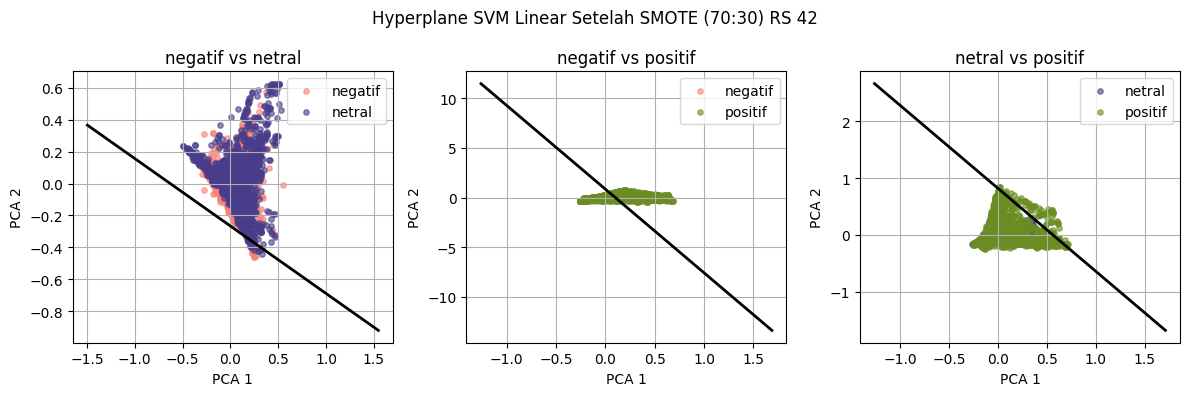

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

colors = {'negatif':'salmon', 'netral':'darkslateblue', 'positif':'olivedrab'}

svm_model = SVC(kernel='linear', C=5)
svm_model.fit(X_train_tfidf_smote_7030_42, y_train_smote_7030_42)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, (kelas1, kelas2) in enumerate(pairs):
    ax = axes[i]

    mask_train = (y_train_smote_7030_42 == kelas1) | (y_train_smote_7030_42 == kelas2)
    X_pair = X_train_tfidf_smote_7030_42[mask_train.to_numpy()]
    y_pair = y_train_smote_7030_42[mask_train]

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_pair.toarray())

    w = svm_model.coef_[i].toarray().flatten()
    b = svm_model.intercept_[i]

    w_pca = pca.components_ @ w

    for label in [kelas1, kelas2]:
        mask_plot = (y_pair == label)
        ax.scatter(X_pca[mask_plot,0],
                   X_pca[mask_plot,1],
                   color=colors[label],
                   label=label,
                   alpha=0.6,
                   s=15)

    x_vals = np.linspace(X_pca[:,0].min()-1, X_pca[:,0].max()+1, 200)

    if w_pca[1] != 0:
        y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
        ax.plot(x_vals, y_vals, 'k-', linewidth=2)
    else:
        ax.axvline(x=-b/w_pca[0], color='k', linewidth=2)

    ax.set_title(f'{kelas1} vs {kelas2}')
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    ax.grid(True)
    ax.legend()

plt.suptitle('Hyperplane SVM Linear Setelah SMOTE (70:30) RS 42')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PREDIKSI & EVALUASI SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 42
# ==========================================================

import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

C_val = [5]
hasil_evaluasi_smote_7030_42 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_7030_42, y_train_smote_7030_42)

    y_pred = svm_model.predict(X_test_tfidf_7030_42)

    print(f"\n--- HASIL PREDIKSI (70:30) RS 42, C={C_val} ---")

    hasil_prediksi_42 = pd.DataFrame({
        'teks_tweet': X_test_7030_42,
        'label_aktual': y_test_7030_42,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_42)

    accuracy = accuracy_score(y_test_7030_42, y_pred)
    precision = precision_score(y_test_7030_42, y_pred, average='macro')
    recall = recall_score(y_test_7030_42, y_pred, average='macro')
    f1 = f1_score(y_test_7030_42, y_pred, average='macro')

    hasil_evaluasi_smote_7030_42.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI RS 42 ---")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n",
          confusion_matrix(y_test_7030_42, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_7030_42, y_pred, target_names=labels))


--- HASIL PREDIKSI (70:30) RS 42, C=5 ---
                                             teks_tweet label_aktual  \
468                                biar lebih hemat bbm      negatif   
2799                                       peh cek enak      negatif   
290                                  pekan puncak macet      negatif   
6147        liter bos orang enggan angkat tidak menteri       netral   
4557                               nasib travel pribadi       netral   
...                                                 ...          ...   
6136  cek lapang butuh bbm mobil distribusi butuh pa...       netral   
2456                         bijak tidak data sembarang      negatif   
3302                                      aduh mbg stop      negatif   
3706                    aneh liter pulang crbn surabaya      negatif   
929                                           acak acak      negatif   

     label_prediksi  
468         negatif  
2799        negatif  
290         negatif  
6147

# Random state 123

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE (70:30)
# RANDOM STATE = 123
# ==========================================================

svm_smote = SVC(kernel='linear')

param_grid_smote = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_7030_123 = GridSearchCV(
    svm_smote,
    param_grid_smote,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_7030_123.fit(X_train_tfidf_smote_7030_123, y_train_smote_7030_123)

print("Best Parameter Setelah SMOTE (70:30) RS 123 :", grid_search_smote_7030_123.best_params_)

Best Parameter Setelah SMOTE (70:30) RS 123 : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

hasil_tuning_smote_7030_123 = pd.DataFrame(
    grid_search_smote_7030_123.cv_results_
)

hasil_tuning_smote_7030_123 = hasil_tuning_smote_7030_123[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_7030_123.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_7030_123.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.772458  0.027252        6
1  0.3       0.864544  0.022766        5
2  0.5       0.899631  0.019721        4
3  1.0       0.932097  0.018139        3
4  3.0       0.957779  0.009991        2
5  5.0       0.961632  0.007465        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "70:30"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote_7030_123 = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_7030_123, y_train_smote_7030_123)

    support_indices = svm_model.support_
    y_sv = y_train_smote_7030_123.iloc[support_indices] if hasattr(y_train_smote_7030_123, "iloc") else y_train_smote_7030_123[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_7030_123 == kelas1) | (y_train_smote_7030_123 == kelas2)
        y_pair = y_train_smote_7030_123[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote_7030_123.append({
            'Rasio': rasio,
            'Random State': 123,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_7030_123 = pd.DataFrame(model_info_smote_7030_123)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_7030_123)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,70:30,123,5,negatif vs netral,2916,2916,984,1329,2313,-0.791340,"[rubah, jelang, kendala, lasting, balita, area...","[7.820947786706213, -5.6436347425286755, -5.49..."
1,70:30,123,5,negatif vs positif,2916,2916,984,727,1711,0.527221,"[rubah, kendala, jelang, peduli, lasting, hahh...","[5.166045246310663, -3.7970562628896722, -3.75..."
2,70:30,123,5,netral vs positif,2916,2916,1329,727,2056,1.539822,"[charge, rubah, jelang, kendala, batal, lastin...","[-7.068607848525387, 6.986874039567013, -5.464..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_7030_123 == kelas1) | (y_train_smote_7030_123 == kelas2)

    X_pair = X_train_tfidf_smote_7030_123[mask_pair.to_numpy()]
    y_pair = y_train_smote_7030_123[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)
    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n" + "="*80 + "\n")

=== Model Biner : negatif vs netral ===

α_i = ['-0.12290067711129243' '-2.4679100800568348' '-4.370915009321854'
 '-1.3298577682340822' '-0.38698557307695236' '...' '5.0'
 '0.2116356887444887' '2.8068621660132056' '4.26072919274653'
 '1.0595106718398941']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.7913


=== Model Biner : negatif vs positif ===

α_i = ['-0.867989549464951' '-5.0' '-0.9483362815219242' '-2.0606418883146316'
 '-0.6789913545344424' '...' '3.1419060813191284' '0.19086715658068729'
 '4.981576099094596' '1.4848841692784778' '1.0031742285186014']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.0 0.0 0.0 

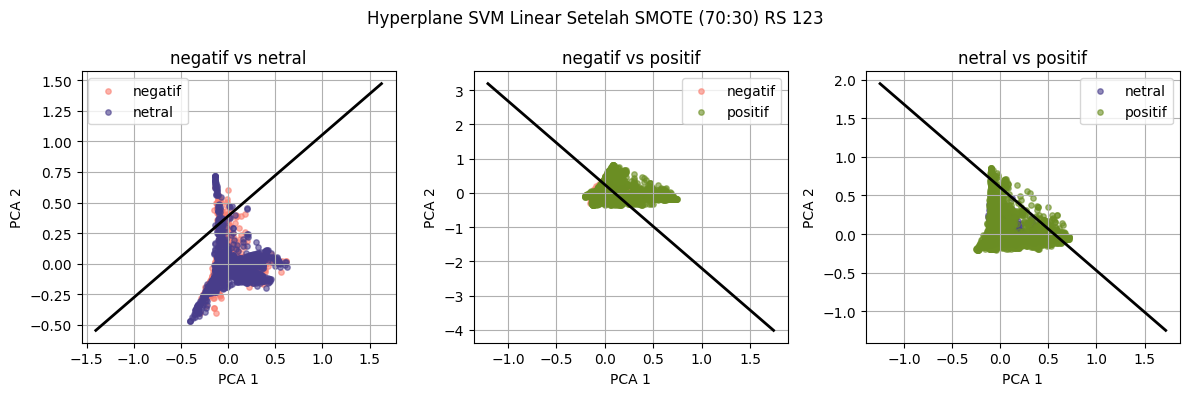

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

svm_model = SVC(kernel='linear', C=5)
svm_model.fit(X_train_tfidf_smote_7030_123, y_train_smote_7030_123)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, (kelas1, kelas2) in enumerate(pairs):
    ax = axes[i]

    mask_train = (y_train_smote_7030_123 == kelas1) | (y_train_smote_7030_123 == kelas2)
    X_pair = X_train_tfidf_smote_7030_123[mask_train.to_numpy()]
    y_pair = y_train_smote_7030_123[mask_train]

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_pair.toarray())

    w = svm_model.coef_[i].toarray().flatten()
    b = svm_model.intercept_[i]

    w_pca = pca.components_ @ w

    for label in [kelas1, kelas2]:
        mask_plot = (y_pair == label)
        ax.scatter(X_pca[mask_plot,0],
                   X_pca[mask_plot,1],
                   color=colors[label],
                   label=label,
                   alpha=0.6,
                   s=15)

    x_vals = np.linspace(X_pca[:,0].min()-1, X_pca[:,0].max()+1, 200)

    if w_pca[1] != 0:
        y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
        ax.plot(x_vals, y_vals, 'k-', linewidth=2)
    else:
        ax.axvline(x=-b/w_pca[0], color='k', linewidth=2)

    ax.set_title(f'{kelas1} vs {kelas2}')
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    ax.grid(True)
    ax.legend()

plt.suptitle('Hyperplane SVM Linear Setelah SMOTE (70:30) RS 123')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PREDIKSI & EVALUASI SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 123
# ==========================================================

C_val = [5]
hasil_evaluasi_smote_7030_123 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_7030_123, y_train_smote_7030_123)

    y_pred = svm_model.predict(X_test_tfidf_7030_123)

    print(f"\n--- HASIL PREDIKSI (70:30) RS 123, C={C_val} ---")

    hasil_prediksi_123 = pd.DataFrame({
        'teks_tweet': X_test_7030_123,
        'label_aktual': y_test_7030_123,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_123)

    accuracy = accuracy_score(y_test_7030_123, y_pred)
    precision = precision_score(y_test_7030_123, y_pred, average='macro')
    recall = recall_score(y_test_7030_123, y_pred, average='macro')
    f1 = f1_score(y_test_7030_123, y_pred, average='macro')

    hasil_evaluasi_smote_7030_123.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI RS 123 ---")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n",
          confusion_matrix(y_test_7030_123, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_7030_123, y_pred, target_names=labels))


--- HASIL PREDIKSI (70:30) RS 123, C=5 ---
                                             teks_tweet label_aktual  \
5442                                       terlalu atur      negatif   
1357            asn tenaga sehat guru tidak teman teman       netral   
3704                                      lebih mbg bbm      positif   
921           naa pusing akibat apbn tidak hitung valid      negatif   
5618  perintah asal kendara niaga tempuh jalan perin...      negatif   
...                                                 ...          ...   
5559  antre macet parah distribusi butuh pokok hamba...      negatif   
4809  mobil guna pribadi non subsidi pertamax mobil ...      positif   
3366                   tidak kerja keluyur sih perintah       netral   
6168                                     moga realisasi       netral   
4885            kendara motor batas tidak berita kompas      negatif   

     label_prediksi  
5442        negatif  
1357         netral  
3704        positif  
921

# Random State 999

In [ ]:
# ==========================================================
# MELIHAT C TERBAIK SETELAH SMOTE (70:30)
# RANDOM STATE = 999
# ==========================================================

svm_smote = SVC(kernel='linear')

param_grid_smote = {
    'C': [0.1, 0.3, 0.5, 1, 3, 5]
}

grid_search_smote_7030_999 = GridSearchCV(
    svm_smote,
    param_grid_smote,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search_smote_7030_999.fit(X_train_tfidf_smote_7030_999, y_train_smote_7030_999)

print("Best Parameter Setelah SMOTE (70:30) RS 999 :", grid_search_smote_7030_999.best_params_)

Best Parameter Setelah SMOTE (70:30) RS 999 : {'C': 5}


In [ ]:
# ==========================================================
# HASIL TUNING SVM SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

hasil_tuning_smote_7030_999 = pd.DataFrame(
    grid_search_smote_7030_999.cv_results_
)

hasil_tuning_smote_7030_999 = hasil_tuning_smote_7030_999[
    [
        'param_C',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
]

hasil_tuning_smote_7030_999.columns = [
    'C',
    'Mean F1 Macro',
    'Std',
    'Ranking'
]

print(hasil_tuning_smote_7030_999.sort_values('C'))

     C  Mean F1 Macro       Std  Ranking
0  0.1       0.774136  0.023604        6
1  0.3       0.866548  0.025749        5
2  0.5       0.898821  0.021298        4
3  1.0       0.928404  0.019487        3
4  3.0       0.955514  0.011528        2
5  5.0       0.959512  0.010153        1


In [ ]:
import numpy as np
from scipy.sparse import issparse

# ==========================================================
# PEMBENTUKAN MODEL + SUPPORT VECTOR SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_val = [5]
rasio = "70:30"

feature_names = tfidf_vectorizer.get_feature_names_out()

model_info_smote_7030_999 = []

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_7030_999, y_train_smote_7030_999)

    support_indices = svm_model.support_
    y_sv = y_train_smote_7030_999.iloc[support_indices] if hasattr(y_train_smote_7030_999, "iloc") else y_train_smote_7030_999[support_indices]

    for i, (kelas1, kelas2) in enumerate(pairs):

        sv_kelas1 = sum(y_sv == kelas1)
        sv_kelas2 = sum(y_sv == kelas2)
        total_sv_pair = sv_kelas1 + sv_kelas2

        mask_pair = (y_train_smote_7030_999 == kelas1) | (y_train_smote_7030_999 == kelas2)
        y_pair = y_train_smote_7030_999[mask_pair]

        jml_data_kelas1 = sum(y_pair == kelas1)
        jml_data_kelas2 = sum(y_pair == kelas2)

        w_dense = svm_model.coef_[i].toarray().flatten() if issparse(svm_model.coef_[i]) else svm_model.coef_[i]
        b_val = svm_model.intercept_[i]

        top_idx = np.argsort(np.abs(w_dense))[::-1][:10]

        model_info_smote_7030_999.append({
            'Rasio': rasio,
            'Random State': 999,
            'C': C_val,
            'Model Biner': f'{kelas1} vs {kelas2}',
            'Jumlah Data Kelas1': jml_data_kelas1,
            'Jumlah Data Kelas2': jml_data_kelas2,
            'SV Kelas1': sv_kelas1,
            'SV Kelas2': sv_kelas2,
            'Total SV Model': total_sv_pair,
            'b': b_val,
            'Fitur (kata)': list(feature_names[top_idx]),
            'Top 10 Bobot w': list(w_dense[top_idx])
        })

df_model_info_smote_7030_999 = pd.DataFrame(model_info_smote_7030_999)

pd.set_option('display.max_columns', None)
display(df_model_info_smote_7030_999)

,Rasio,Random State,C,Model Biner,Jumlah Data Kelas1,Jumlah Data Kelas2,SV Kelas1,SV Kelas2,Total SV Model,b,Fitur (kata),Top 10 Bobot w
0,70:30,999,5,negatif vs netral,2916,2916,1022,1313,2335,-0.848758,"[santai, aridiot, ketenagakerjaan, jibaku, lel...","[7.600317000471762, 5.753810863646889, -5.5954..."
1,70:30,999,5,negatif vs positif,2916,2916,1022,757,1779,0.531753,"[santai, ketenagakerjaan, jibaku, lelaj, aridi...","[4.994320889499605, -3.712004246515697, -3.580..."
2,70:30,999,5,netral vs positif,2916,2916,1313,757,2070,1.471622,"[santai, chip, jibaku, balita, ketenagakerjaan...","[7.063500833016036, -7.036082427456017, -5.293..."


In [ ]:
# ==========================================================
# MENAMPILKAN αi, yi, DAN xi SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

pairs = [('negatif','netral'),
         ('negatif','positif'),
         ('netral','positif')]

C_best = 5

for kelas1, kelas2 in pairs:

    mask_pair = (y_train_smote_7030_999 == kelas1) | (y_train_smote_7030_999 == kelas2)

    X_pair = X_train_tfidf_smote_7030_999[mask_pair.to_numpy()]
    y_pair = y_train_smote_7030_999[mask_pair]

    svm_model = SVC(kernel='linear', C=C_best)
    svm_model.fit(X_pair, y_pair)

    support_idx = svm_model.support_

    ai = svm_model.dual_coef_[0]
    yi = y_pair.iloc[support_idx].to_numpy()
    xi = X_pair[support_idx].toarray()

    b_val = svm_model.intercept_[0]

    ai_summarized = summarize_1d(ai, 5)
    yi_summarized = summarize_1d(yi, 5)
    xi_summarized = summarize_2d_for_display(xi, 5, 10)

    print(f"=== Model Biner : {kelas1} vs {kelas2} ===\n")

    print("α_i =", ai_summarized)
    print("y_i =", yi_summarized)

    print("x_i =")

    for row in xi_summarized:
        print(' '.join([str(round(v,4)) if isinstance(v,float) else str(v) for v in row]))

    print("b =", round(b_val,4))

    print("\n" + "="*80 + "\n")

=== Model Biner : negatif vs netral ===

α_i = ['-4.356989564860296' '-0.5540719186544572' '-1.1651483137003926' '-5.0'
 '-1.950040145970863' '...' '5.0' '5.0' '5.0' '0.2179172724077367'
 '4.657049077462524']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'netral' 'netral'
 'netral' 'netral' 'netral']
x_i =
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
b = 0.8488


=== Model Biner : negatif vs positif ===

α_i = ['-2.414292734799543' '-3.281537729047194' '-0.31897985703433906'
 '-2.805991411443846' '-0.6985522235618457' '...' '1.8597085838853973'
 '0.9061772148729764' '0.04940206110416802' '0.2914370667465814'
 '0.0029030450620094227']
y_i = ['negatif' 'negatif' 'negatif' 'negatif' 'negatif' '...' 'positif'
 'positif' 'positif' 'positif' 'positif']
x_i =
0.0 0.4050780386169819 0.0 0.0 0.0 ... 0.0 0.

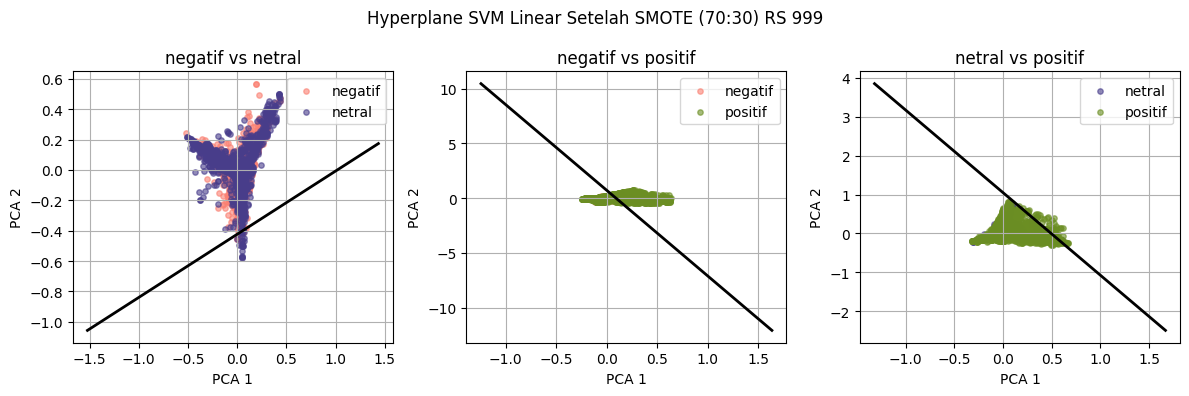

In [ ]:
# ==========================================================
# VISUALISASI HYPERPLANE SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

svm_model = SVC(kernel='linear', C=5)
svm_model.fit(X_train_tfidf_smote_7030_999, y_train_smote_7030_999)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, (kelas1, kelas2) in enumerate(pairs):
    ax = axes[i]

    mask_train = (y_train_smote_7030_999 == kelas1) | (y_train_smote_7030_999 == kelas2)
    X_pair = X_train_tfidf_smote_7030_999[mask_train.to_numpy()]
    y_pair = y_train_smote_7030_999[mask_train]

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_pair.toarray())

    w = svm_model.coef_[i].toarray().flatten()
    b = svm_model.intercept_[i]

    w_pca = pca.components_ @ w

    for label in [kelas1, kelas2]:
        mask_plot = (y_pair == label)
        ax.scatter(X_pca[mask_plot,0],
                   X_pca[mask_plot,1],
                   color=colors[label],
                   label=label,
                   alpha=0.6,
                   s=15)

    x_vals = np.linspace(X_pca[:,0].min()-1, X_pca[:,0].max()+1, 200)

    if w_pca[1] != 0:
        y_vals = -(w_pca[0]*x_vals + b)/w_pca[1]
        ax.plot(x_vals, y_vals, 'k-', linewidth=2)
    else:
        ax.axvline(x=-b/w_pca[0], color='k', linewidth=2)

    ax.set_title(f'{kelas1} vs {kelas2}')
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    ax.grid(True)
    ax.legend()

plt.suptitle('Hyperplane SVM Linear Setelah SMOTE (70:30) RS 999')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PREDIKSI & EVALUASI SETELAH SMOTE
# RASIO 70:30
# RANDOM STATE = 999
# ==========================================================

C_val = [5]
hasil_evaluasi_smote_7030_999 = []

labels = ['negatif','netral','positif']

for C_val in C_val:

    svm_model = SVC(kernel='linear', C=C_val)
    svm_model.fit(X_train_tfidf_smote_7030_999, y_train_smote_7030_999)

    y_pred = svm_model.predict(X_test_tfidf_7030_999)

    print(f"\n--- HASIL PREDIKSI (70:30) RS 999, C={C_val} ---")

    hasil_prediksi_999 = pd.DataFrame({
        'teks_tweet': X_test_7030_999,
        'label_aktual': y_test_7030_999,
        'label_prediksi': y_pred
    })

    print(hasil_prediksi_999)

    accuracy = accuracy_score(y_test_7030_999, y_pred)
    precision = precision_score(y_test_7030_999, y_pred, average='macro')
    recall = recall_score(y_test_7030_999, y_pred, average='macro')
    f1 = f1_score(y_test_7030_999, y_pred, average='macro')

    hasil_evaluasi_smote_7030_999.append({
        'C': C_val,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\n--- EVALUASI RS 999 ---")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    print("\nConfusion Matrix:\n",
          confusion_matrix(y_test_7030_999, y_pred, labels=labels))

    print("\nClassification Report:\n",
          classification_report(y_test_7030_999, y_pred, target_names=labels))


--- HASIL PREDIKSI (70:30) RS 999, C=5 ---
                                             teks_tweet label_aktual  \
3612                              belum tuju udah habis      negatif   
399                 ampun anak rontok rambut ajar rumah      negatif   
3954                                     anjir perintah      negatif   
4709                    sticker salah buka tiktok malem      negatif   
632          mah mending hemat bbm habis duluan bbm nya      negatif   
...                                                 ...          ...   
2276  wfh efisiensi bbm anak sekolah sabtu libur ber...       netral   
1402                                       tenaga medis      positif   
6260  kantor rencana hajat tuh haha tolong cut acara...      negatif   
4290                      batas lapang tidak terap main      negatif   
1412                              maksude guna wfh alas      positif   

     label_prediksi  
3612        negatif  
399         negatif  
3954        negatif  
470

In [ ]:
# ==========================================================
# RANGKUMAN HASIL TUNING SVM SETELAH SMOTE
# ==========================================================

ringkasan_tuning = pd.DataFrame({

    "Rasio": [
        "90:10","90:10","90:10",
        "80:20","80:20","80:20",
        "70:30","70:30","70:30"
    ],

    "Random State": [
        42,123,999,
        42,123,999,
        42,123,999
    ],

    "Best C": [
        grid_search_smote_9010_42.best_params_["C"],
        grid_search_smote_9010_123.best_params_["C"],
        grid_search_smote_9010_999.best_params_["C"],

        grid_search_smote_8020_42.best_params_["C"],
        grid_search_smote_8020_123.best_params_["C"],
        grid_search_smote_8020_999.best_params_["C"],

        grid_search_smote_7030_42.best_params_["C"],
        grid_search_smote_7030_123.best_params_["C"],
        grid_search_smote_7030_999.best_params_["C"]
    ],

    "Best Macro F1": [
        grid_search_smote_9010_42.best_score_,
        grid_search_smote_9010_123.best_score_,
        grid_search_smote_9010_999.best_score_,

        grid_search_smote_8020_42.best_score_,
        grid_search_smote_8020_123.best_score_,
        grid_search_smote_8020_999.best_score_,

        grid_search_smote_7030_42.best_score_,
        grid_search_smote_7030_123.best_score_,
        grid_search_smote_7030_999.best_score_
    ]

})

ringkasan_tuning["Best Macro F1"] = ringkasan_tuning["Best Macro F1"].round(4)

display(ringkasan_tuning)

,Rasio,Random State,Best C,Best Macro F1
0,90:10,42,5,0.9650
1,90:10,123,5,0.9628
2,90:10,999,5,0.9655
3,80:20,42,5,0.9610
4,80:20,123,5,0.9629
5,80:20,999,5,0.9616
6,70:30,42,5,0.9573
7,70:30,123,5,0.9616
8,70:30,999,5,0.9595


In [ ]:
import pandas as pd

# Convert lists of evaluation results into DataFrames
df_eval_smote_8020_42 = pd.DataFrame(hasil_evaluasi_smote_8020_42)
df_eval_smote_8020_123 = pd.DataFrame(hasil_evaluasi_smote_8020_123)
df_eval_smote_8020_999 = pd.DataFrame(hasil_evaluasi_smote_8020_999)

df_eval_smote_9010_42 = pd.DataFrame(hasil_evaluasi_smote_9010_42)
df_eval_smote_9010_123 = pd.DataFrame(hasil_evaluasi_smote_9010_123)
df_eval_smote_9010_999 = pd.DataFrame(hasil_evaluasi_smote_9010_999)

df_eval_smote_7030_42 = pd.DataFrame(hasil_evaluasi_smote_7030_42)
df_eval_smote_7030_123 = pd.DataFrame(hasil_evaluasi_smote_7030_123)
df_eval_smote_7030_999 = pd.DataFrame(hasil_evaluasi_smote_7030_999)

df_svm_eval_smote = pd.DataFrame([

    # ===================== 80:20 =====================
    {"Rasio":"80:20","State":42,
     "Accuracy":df_eval_smote_8020_42['Accuracy'].iloc[0],
     "Precision":df_eval_smote_8020_42['Precision'].iloc[0],
     "Recall":df_eval_smote_8020_42['Sensitivity'].iloc[0],
     "F1-Score":df_eval_smote_8020_42['F1-Score'].iloc[0]},

    {"Rasio":"80:20","State":123,
     "Accuracy":df_eval_smote_8020_123['Accuracy'].iloc[0],
     "Precision":df_eval_smote_8020_123['Precision'].iloc[0],
     "Recall":df_eval_smote_8020_123['Sensitivity'].iloc[0],
     "F1-Score":df_eval_smote_8020_123['F1-Score'].iloc[0]},

    {"Rasio":"80:20","State":999,
     "Accuracy":df_eval_smote_8020_999['Accuracy'].iloc[0],
     "Precision":df_eval_smote_8020_999['Precision'].iloc[0],
     "Recall":df_eval_smote_8020_999['Sensitivity'].iloc[0],
     "F1-Score":df_eval_smote_8020_999['F1-Score'].iloc[0]},

    # ===================== 90:10 =====================
    {"Rasio":"90:10","State":42,
     "Accuracy":df_eval_smote_9010_42['Accuracy'].iloc[0],
     "Precision":df_eval_smote_9010_42['Precision'].iloc[0],
     "Recall":df_eval_smote_9010_42['Sensitivity'].iloc[0],
     "F1-Score":df_eval_smote_9010_42['F1-Score'].iloc[0]},

    {"Rasio":"90:10","State":123,
     "Accuracy":df_eval_smote_9010_123['Accuracy'].iloc[0],
     "Precision":df_eval_smote_9010_123['Precision'].iloc[0],
     "Recall":df_eval_smote_9010_123['Sensitivity'].iloc[0],
     "F1-Score":df_eval_smote_9010_123['F1-Score'].iloc[0]},

    {"Rasio":"90:10","State":999,
     "Accuracy":df_eval_smote_9010_999['Accuracy'].iloc[0],
     "Precision":df_eval_smote_9010_999['Precision'].iloc[0],
     "Recall":df_eval_smote_9010_999['Sensitivity'].iloc[0],
     "F1-Score":df_eval_smote_9010_999['F1-Score'].iloc[0]},

    # ===================== 70:30 =====================
    {"Rasio":"70:30","State":42,
     "Accuracy":df_eval_smote_7030_42['Accuracy'].iloc[0],
     "Precision":df_eval_smote_7030_42['Precision'].iloc[0],
     "Recall":df_eval_smote_7030_42['Recall'].iloc[0],
     "F1-Score":df_eval_smote_7030_42['F1-Score'].iloc[0]},

    {"Rasio":"70:30","State":123,
     "Accuracy":df_eval_smote_7030_123['Accuracy'].iloc[0],
     "Precision":df_eval_smote_7030_123['Precision'].iloc[0],
     "Recall":df_eval_smote_7030_123['Recall'].iloc[0],
     "F1-Score":df_eval_smote_7030_123['F1-Score'].iloc[0]},

    {"Rasio":"70:30","State":999,
     "Accuracy":df_eval_smote_7030_999['Accuracy'].iloc[0],
     "Precision":df_eval_smote_7030_999['Precision'].iloc[0],
     "Recall":df_eval_smote_7030_999['Recall'].iloc[0],
     "F1-Score":df_eval_smote_7030_999['F1-Score'].iloc[0]}
])

# ==========================================================
# KONVERSI KE PERSENTASE (%)
# ==========================================================

for col in ["Accuracy","Precision","Recall","F1-Score"]:
    df_svm_eval_smote[col] = df_svm_eval_smote[col] * 100

# ==========================================================
# TAMPILKAN HASIL
# ==========================================================

print("===== RINGKASAN EVALUASI SVM SETELAH SMOTE =====")
display(df_svm_eval_smote)

===== RINGKASAN EVALUASI SVM SETELAH SMOTE =====


,Rasio,State,Accuracy,Precision,Recall,F1-Score
0,80:20,42,87.187500,81.385831,82.375768,81.866963
1,80:20,123,88.828125,84.167811,84.740785,84.434392
2,80:20,999,88.671875,83.895678,85.241463,84.519953
3,90:10,42,89.531250,85.463950,84.812807,85.017915
4,90:10,123,89.218750,85.852509,85.574195,85.619060
5,90:10,999,89.531250,84.788682,86.578014,85.645527
6,70:30,42,87.187500,81.763451,82.735371,82.179065
7,70:30,123,86.093750,81.590009,80.351208,80.889633
8,70:30,999,87.604167,83.087588,83.880676,83.377053


# NBC+SMOTE

# 90:10

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (90:10)
# RANDOM STATE = 42
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_9010_42))

vocab_df_smote_9010_42 = pd.DataFrame({
    "Vocabulary": vocab_9010_42
})

display(vocab_df_smote_9010_42)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_9010_42 = MultinomialNB(alpha=1.0)

nb_model_smote_9010_42.fit(
    X_train_tfidf_smote_9010_42,
    y_train_smote_9010_42
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_9010_42 = pd.DataFrame({
    "Kelas": nb_model_smote_9010_42.classes_,
    "Prior": np.exp(nb_model_smote_9010_42.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_9010_42)

# ==========================================================
# LIKELIHOOD
# ==========================================================

likelihood_smote_9010_42 = pd.DataFrame(
    np.exp(nb_model_smote_9010_42.feature_log_prob_).T,
    index=vocab_9010_42,
    columns=nb_model_smote_9010_42.classes_
)

print("\n========== LIKELIHOOD ==========\n")
display(likelihood_smote_9010_42)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_9010_42 = nb_model_smote_9010_42.predict(
    X_test_tfidf_9010_42
)

# ==========================================================
# POSTERIOR PROBABILITY
# ==========================================================

posterior_smote_9010_42 = nb_model_smote_9010_42.predict_proba(
    X_test_tfidf_9010_42
)

hasil_posterior_smote_9010_42 = pd.DataFrame({

    "Dok": X_test_9010_42.index,

    "Teks Komentar": X_test_9010_42.values,

    "Posterior Negatif": posterior_smote_9010_42[:, 0],

    "Posterior Netral": posterior_smote_9010_42[:, 1],

    "Posterior Positif": posterior_smote_9010_42[:, 2],

    "Label Aktual": y_test_9010_42.values,

    "Label Prediksi": y_pred_smote_9010_42

})

print("\n========== HASIL POSTERIOR ==========\n")
display(hasil_posterior_smote_9010_42)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_9010_42 = accuracy_score(
    y_test_9010_42,
    y_pred_smote_9010_42
)

precision_macro_smote_9010_42 = precision_score(
    y_test_9010_42,
    y_pred_smote_9010_42,
    average='macro'
)

recall_macro_smote_9010_42 = recall_score(
    y_test_9010_42,
    y_pred_smote_9010_42,
    average='macro'
)

f1_macro_smote_9010_42 = f1_score(
    y_test_9010_42,
    y_pred_smote_9010_42,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_9010_42, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_9010_42, 2))
print("Recall    :", round(recall_macro_smote_9010_42, 2))
print("F1-Score  :", round(f1_macro_smote_9010_42, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_9010_42 = confusion_matrix(
    y_test_9010_42,
    y_pred_smote_9010_42,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_9010_42 = pd.DataFrame(
    cm_smote_9010_42,
    index=labels,
    columns=labels
)

display(cm_df_smote_9010_42)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_9010_42,
        y_pred_smote_9010_42,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3482


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3477,zaman
3478,zenix
3479,zolim
3480,zonasi


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000104,0.000095,0.000087
abdi,0.000191,0.000095,0.000181
absen,0.000455,0.000095,0.000165
absensi,0.000148,0.000095,0.000087
absurd,0.000117,0.000095,0.000087
...,...,...,...
zaman,0.000968,0.001194,0.000947
zenix,0.000080,0.000095,0.000180
zolim,0.000080,0.000095,0.000339
zonasi,0.000122,0.000095,0.000879



========== HASIL POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,1721,wfh laksana nya perintah ketidakpercayaan laks...,0.160930,0.343980,0.495091,netral,positif
1,5862,suka kelen,0.565809,0.252011,0.182180,negatif,negatif
2,1257,tolong anak sekolah jangan daring kacau daring,0.650529,0.056479,0.292992,negatif,negatif
3,773,enak banget ngomong tidak kerja pecat tutup ti...,0.360267,0.268842,0.370891,negatif,positif
4,4659,kocak nih perintah tidak atur beli bensin lite...,0.701158,0.289110,0.009732,negatif,negatif
...,...,...,...,...,...,...,...
635,5988,atur nya tidak jelas tai atur susah supir eksp...,0.936570,0.043602,0.019829,negatif,negatif
636,1675,layan hotel restoran ajak tidak,0.330544,0.359329,0.310127,negatif,netral
637,3393,cabut alokasi mobil dinas,0.398018,0.337216,0.264767,netral,negatif
638,4196,tidak akal nya perintah,0.385674,0.488652,0.125674,negatif,netral



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.55
Recall    : 0.59
F1-Score  : 0.56

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,318,57,41
netral,35,50,45
positif,9,26,59



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.88      0.76      0.82       416
      netral       0.38      0.38      0.38       130
     positif       0.41      0.63      0.49        94

    accuracy                           0.67       640
   macro avg       0.55      0.59      0.56       640
weighted avg       0.71      0.67      0.68       640



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (90:10)
# RANDOM STATE = 123
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_9010_123))

vocab_df_smote_9010_123 = pd.DataFrame({
    "Vocabulary": vocab_9010_123
})

display(vocab_df_smote_9010_123)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_9010_123 = MultinomialNB(alpha=1.0)

nb_model_smote_9010_123.fit(
    X_train_tfidf_smote_9010_123,
    y_train_smote_9010_123
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_9010_123 = pd.DataFrame({
    "Kelas": nb_model_smote_9010_123.classes_,
    "Prior": np.exp(nb_model_smote_9010_123.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_9010_123)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_9010_123 = pd.DataFrame(
    np.exp(nb_model_smote_9010_123.feature_log_prob_).T,
    index=vocab_9010_123,
    columns=nb_model_smote_9010_123.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_9010_123)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_9010_123 = nb_model_smote_9010_123.predict(
    X_test_tfidf_9010_123
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_9010_123 = nb_model_smote_9010_123.predict_proba(
    X_test_tfidf_9010_123
)

hasil_posterior_smote_9010_123 = pd.DataFrame({

    "Dok": X_test_9010_123.index,

    "Teks Komentar": X_test_9010_123.values,

    "Posterior Negatif": posterior_smote_9010_123[:, 0],

    "Posterior Netral": posterior_smote_9010_123[:, 1],

    "Posterior Positif": posterior_smote_9010_123[:, 2],

    "Label Aktual": y_test_9010_123.values,

    "Label Prediksi": y_pred_smote_9010_123

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_9010_123)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_9010_123 = accuracy_score(
    y_test_9010_123,
    y_pred_smote_9010_123
)

precision_macro_smote_9010_123 = precision_score(
    y_test_9010_123,
    y_pred_smote_9010_123,
    average='macro'
)

recall_macro_smote_9010_123 = recall_score(
    y_test_9010_123,
    y_pred_smote_9010_123,
    average='macro'
)

f1_macro_smote_9010_123 = f1_score(
    y_test_9010_123,
    y_pred_smote_9010_123,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_9010_123, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_9010_123, 2))
print("Recall    :", round(recall_macro_smote_9010_123, 2))
print("F1-Score  :", round(f1_macro_smote_9010_123, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_9010_123 = confusion_matrix(
    y_test_9010_123,
    y_pred_smote_9010_123,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_9010_123 = pd.DataFrame(
    cm_smote_9010_123,
    index=labels,
    columns=labels
)

display(cm_df_smote_9010_123)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_9010_123,
        y_pred_smote_9010_123,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3538


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3533,zenix
3534,zolim
3535,zonasi
3536,zonk


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000103,0.000094,0.000087
abdi,0.000168,0.000094,0.000345
absen,0.000415,0.000094,0.000111
absensi,0.000147,0.000094,0.000087
absurd,0.000116,0.000094,0.000087
...,...,...,...
zenix,0.000080,0.000094,0.000171
zolim,0.000080,0.000094,0.000394
zonasi,0.000121,0.000094,0.000830
zonk,0.000080,0.000094,0.000182



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Posterior Negatif,Posterior Netral,Posterior Positif,Label Aktual,Label Prediksi
0,5163,tidak jelas arah perintah mobil truk trayek wo...,0.901309,0.089200,0.009491,negatif,negatif
1,874,stop mbg alih urgensi didik sehat wfh tidak ef...,0.542145,0.137259,0.320596,negatif,negatif
2,4929,truk ekspedisi liter jakarta,0.227841,0.533984,0.238175,netral,netral
3,6366,batas tunjang menteri dpr jabat nya,0.511337,0.419395,0.069268,negatif,negatif
4,3637,konsumsi bbm setir wajar hari tidak kemarin de...,0.405284,0.319869,0.274848,negatif,negatif
...,...,...,...,...,...,...,...
635,6215,kurang mbg,0.575662,0.247718,0.176620,negatif,negatif
636,4063,jakarta surabaya,0.259580,0.191260,0.549161,netral,positif
637,457,opsi sepeda becak delman delman daerah kendara...,0.336618,0.467462,0.195920,netral,netral
638,5995,susah susah susah rezim,0.826643,0.115866,0.057491,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.69

Macro Average
Precision : 0.59
Recall    : 0.64
F1-Score  : 0.61

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,317,69,30
netral,39,54,37
positif,9,15,70



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.87      0.76      0.81       416
      netral       0.39      0.42      0.40       130
     positif       0.51      0.74      0.61        94

    accuracy                           0.69       640
   macro avg       0.59      0.64      0.61       640
weighted avg       0.72      0.69      0.70       640



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (90:10)
# RANDOM STATE = 999
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_9010_999))

vocab_df_smote_9010_999 = pd.DataFrame({
    "Vocabulary": vocab_9010_999
})

display(vocab_df_smote_9010_999)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_9010_999 = MultinomialNB(alpha=1.0)

nb_model_smote_9010_999.fit(
    X_train_tfidf_smote_9010_999,
    y_train_smote_9010_999
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_9010_999 = pd.DataFrame({
    "Kelas": nb_model_smote_9010_999.classes_,
    "Prior": np.exp(nb_model_smote_9010_999.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_9010_999)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_9010_999 = pd.DataFrame(
    np.exp(nb_model_smote_9010_999.feature_log_prob_).T,
    index=vocab_9010_999,
    columns=nb_model_smote_9010_999.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_9010_999)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_9010_999 = nb_model_smote_9010_999.predict(
    X_test_tfidf_9010_999
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_9010_999 = nb_model_smote_9010_999.predict_proba(
    X_test_tfidf_9010_999
)

hasil_posterior_smote_9010_999 = pd.DataFrame({

    "Dok": X_test_9010_999.index,

    "Teks Komentar": X_test_9010_999.values,

    "Log Posterior Negatif": posterior_smote_9010_999[:, 0],

    "Log Posterior Netral": posterior_smote_9010_999[:, 1],

    "Log Posterior Positif": posterior_smote_9010_999[:, 2],

    "Label Aktual": y_test_9010_999.values,

    "Label Prediksi": y_pred_smote_9010_999

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_9010_999)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_9010_999 = accuracy_score(
    y_test_9010_999,
    y_pred_smote_9010_999
)

precision_macro_smote_9010_999 = precision_score(
    y_test_9010_999,
    y_pred_smote_9010_999,
    average='macro'
)

recall_macro_smote_9010_999 = recall_score(
    y_test_9010_999,
    y_pred_smote_9010_999,
    average='macro'
)

f1_macro_smote_9010_999 = f1_score(
    y_test_9010_999,
    y_pred_smote_9010_999,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_9010_999, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_9010_999, 2))
print("Recall    :", round(recall_macro_smote_9010_999, 2))
print("F1-Score  :", round(f1_macro_smote_9010_999, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_9010_999 = confusion_matrix(
    y_test_9010_999,
    y_pred_smote_9010_999,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_9010_999 = pd.DataFrame(
    cm_smote_9010_999,
    index=labels,
    columns=labels
)

display(cm_df_smote_9010_999)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_9010_999,
        y_pred_smote_9010_999,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3547


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3542,zenix
3543,zolim
3544,zonasi
3545,zonk


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000103,0.000094,0.000087
abdi,0.000188,0.000094,0.000399
absen,0.000405,0.000395,0.000114
absensi,0.000147,0.000094,0.000087
absurd,0.000116,0.000094,0.000087
...,...,...,...
zenix,0.000080,0.000094,0.000176
zolim,0.000080,0.000094,0.000441
zonasi,0.000122,0.000094,0.000636
zonk,0.000080,0.000094,0.000226



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,38,tolong jangan bilang anak sekolah ajar daring ...,0.820308,0.038433,0.141259,negatif,negatif
1,4439,liter kendara tidak laku kendara truk plat hit...,0.611250,0.266883,0.121867,negatif,negatif
2,930,aduh hemat bbm stop jual kendara,0.698545,0.226287,0.075168,negatif,negatif
3,3196,jujur jujuran jabat konyol,0.872739,0.073860,0.053401,negatif,negatif
4,111,bijak tidak bijak,0.857755,0.094820,0.047425,negatif,negatif
...,...,...,...,...,...,...,...
635,4948,kalang kabut,0.134711,0.631671,0.233618,negatif,netral
636,469,hemat laku mobil minimal orang liburin jalan j...,0.398485,0.427087,0.174428,negatif,netral
637,4419,terlalu atur bijak kabinet susah masyarakat pa...,0.906960,0.075620,0.017419,negatif,negatif
638,3720,suami supir lintas jawa sumatera gaji tim alok...,0.613252,0.293877,0.092871,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.65

Macro Average
Precision : 0.54
Recall    : 0.59
F1-Score  : 0.55

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,313,63,40
netral,46,42,42
positif,9,21,64



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.85      0.75      0.80       416
      netral       0.33      0.32      0.33       130
     positif       0.44      0.68      0.53        94

    accuracy                           0.65       640
   macro avg       0.54      0.59      0.55       640
weighted avg       0.68      0.65      0.66       640



# 80:20

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (80:20)
# RANDOM STATE = 42
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_8020_42))

vocab_df_smote_8020_42 = pd.DataFrame({
    "Vocabulary": vocab_8020_42
})

display(vocab_df_smote_8020_42)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_8020_42 = MultinomialNB(alpha=1.0)

nb_model_smote_8020_42.fit(
    X_train_tfidf_smote_8020_42,
    y_train_smote_8020_42
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_8020_42 = pd.DataFrame({
    "Kelas": nb_model_smote_8020_42.classes_,
    "Prior": np.exp(nb_model_smote_8020_42.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_8020_42)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_8020_42 = pd.DataFrame(
    np.exp(nb_model_smote_8020_42.feature_log_prob_).T,
    index=vocab_8020_42,
    columns=nb_model_smote_8020_42.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_8020_42)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_8020_42 = nb_model_smote_8020_42.predict(
    X_test_tfidf_8020_42
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_8020_42 = nb_model_smote_8020_42.predict_proba(
    X_test_tfidf_8020_42
)

hasil_posterior_smote_8020_42 = pd.DataFrame({

    "Dok": X_test_8020_42.index,

    "Teks Komentar": X_test_8020_42.values,

    "Log Posterior Negatif": posterior_smote_8020_42[:, 0],

    "Log Posterior Netral": posterior_smote_8020_42[:, 1],

    "Log Posterior Positif": posterior_smote_8020_42[:, 2],

    "Label Aktual": y_test_8020_42.values,

    "Label Prediksi": y_pred_smote_8020_42

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_8020_42)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_8020_42 = accuracy_score(
    y_test_8020_42,
    y_pred_smote_8020_42
)

precision_macro_smote_8020_42 = precision_score(
    y_test_8020_42,
    y_pred_smote_8020_42,
    average='macro'
)

recall_macro_smote_8020_42 = recall_score(
    y_test_8020_42,
    y_pred_smote_8020_42,
    average='macro'
)

f1_macro_smote_8020_42 = f1_score(
    y_test_8020_42,
    y_pred_smote_8020_42,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_8020_42, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_8020_42, 2))
print("Recall    :", round(recall_macro_smote_8020_42, 2))
print("F1-Score  :", round(f1_macro_smote_8020_42, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_8020_42 = confusion_matrix(
    y_test_8020_42,
    y_pred_smote_8020_42,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_8020_42 = pd.DataFrame(
    cm_smote_8020_42,
    index=labels,
    columns=labels
)

display(cm_df_smote_8020_42)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_8020_42,
        y_pred_smote_8020_42,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3302


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3297,zaitun
3298,zaman
3299,zolim
3300,zonasi


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000115,0.000104,0.000096
abdi,0.000210,0.000104,0.000186
absen,0.000460,0.000104,0.000159
absensi,0.000162,0.000104,0.000096
absurd,0.000128,0.000104,0.000096
...,...,...,...
zaitun,0.000152,0.000104,0.000096
zaman,0.000976,0.001182,0.000821
zolim,0.000089,0.000104,0.000535
zonasi,0.000114,0.000104,0.000923



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,993,wfh kerja pakai komputer laptop teman teman,0.135266,0.471122,0.393612,positif,netral
1,4493,liter tidak mobil pribadi,0.202060,0.410497,0.387444,netral,netral
2,3082,tidak daring ibu daring,0.179538,0.011553,0.808909,positif,positif
3,2021,tolong pengaruh kurang paham butuh jelas perinci,0.952602,0.035391,0.012007,negatif,negatif
4,1123,bumc tidak min,0.297734,0.528569,0.173696,negatif,netral
...,...,...,...,...,...,...,...
1275,2828,jangan hak karyawan doang bos hak usaha langsu...,0.674275,0.035428,0.290297,negatif,negatif
1276,4248,tambah geopolitik tidak sesuai dampak indonesi...,0.648948,0.292960,0.058092,negatif,negatif
1277,4519,panik,0.596539,0.210133,0.193328,negatif,negatif
1278,5907,kota aduh kasihan bos,0.568789,0.168743,0.262468,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.66

Macro Average
Precision : 0.56
Recall    : 0.6
F1-Score  : 0.57

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,611,136,86
netral,70,105,84
positif,15,46,127



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.88      0.73      0.80       833
      netral       0.37      0.41      0.38       259
     positif       0.43      0.68      0.52       188

    accuracy                           0.66      1280
   macro avg       0.56      0.60      0.57      1280
weighted avg       0.71      0.66      0.67      1280



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (80:20)
# RANDOM STATE = 123
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_8020_123))

vocab_df_smote_8020_123 = pd.DataFrame({
    "Vocabulary": vocab_8020_123
})

display(vocab_df_smote_8020_123)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_8020_123 = MultinomialNB(alpha=1.0)

nb_model_smote_8020_123.fit(
    X_train_tfidf_smote_8020_123,
    y_train_smote_8020_123
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_8020_123 = pd.DataFrame({
    "Kelas": nb_model_smote_8020_123.classes_,
    "Prior": np.exp(nb_model_smote_8020_123.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_8020_123)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_8020_123 = pd.DataFrame(
    np.exp(nb_model_smote_8020_123.feature_log_prob_).T,
    index=vocab_8020_123,
    columns=nb_model_smote_8020_123.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_8020_123)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_8020_123 = nb_model_smote_8020_123.predict(
    X_test_tfidf_8020_123
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_8020_123 = nb_model_smote_8020_123.predict_proba(
    X_test_tfidf_8020_123
)

hasil_posterior_smote_8020_123 = pd.DataFrame({

    "Dok": X_test_8020_123.index,

    "Teks Komentar": X_test_8020_123.values,

    "Log Posterior Negatif": posterior_smote_8020_123[:, 0],

    "Log Posterior Netral": posterior_smote_8020_123[:, 1],

    "Log Posterior Positif": posterior_smote_8020_123[:, 2],

    "Label Aktual": y_test_8020_123.values,

    "Label Prediksi": y_pred_smote_8020_123

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_8020_123)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_8020_123 = accuracy_score(
    y_test_8020_123,
    y_pred_smote_8020_123
)

precision_macro_smote_8020_123 = precision_score(
    y_test_8020_123,
    y_pred_smote_8020_123,
    average='macro'
)

recall_macro_smote_8020_123 = recall_score(
    y_test_8020_123,
    y_pred_smote_8020_123,
    average='macro'
)

f1_macro_smote_8020_123 = f1_score(
    y_test_8020_123,
    y_pred_smote_8020_123,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_8020_123, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_8020_123, 2))
print("Recall    :", round(recall_macro_smote_8020_123, 2))
print("F1-Score  :", round(f1_macro_smote_8020_123, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_8020_123 = confusion_matrix(
    y_test_8020_123,
    y_pred_smote_8020_123,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_8020_123 = pd.DataFrame(
    cm_smote_8020_123,
    index=labels,
    columns=labels
)

display(cm_df_smote_8020_123)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_8020_123,
        y_pred_smote_8020_123,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3328


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3323,zenix
3324,zolim
3325,zonasi
3326,zonk


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000114,0.000105,0.000096
abdi,0.000153,0.000105,0.000261
absen,0.000423,0.000105,0.000190
absensi,0.000126,0.000105,0.000096
absurd,0.000128,0.000105,0.000096
...,...,...,...
zenix,0.000089,0.000105,0.000193
zolim,0.000089,0.000105,0.000447
zonasi,0.000133,0.000105,0.001002
zonk,0.000089,0.000105,0.000214



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,948,heh jumat tanggal tanggal rabu,0.368026,0.132507,0.499467,negatif,positif
1,5407,amburadul era prabowo angel,0.488932,0.410983,0.100085,negatif,negatif
2,1434,sticker stres stres,0.492621,0.192464,0.314915,negatif,negatif
3,358,maaf tidak efektif wfh mending pagawai anjur b...,0.468707,0.345793,0.185500,negatif,negatif
4,4058,banyak atur,0.832981,0.133927,0.033091,negatif,negatif
...,...,...,...,...,...,...,...
1275,784,malas gebrak konyol,0.783663,0.103665,0.112673,negatif,negatif
1276,3748,halah halah,0.719947,0.182840,0.097214,negatif,negatif
1277,4020,susah orang,0.769370,0.095502,0.135128,negatif,negatif
1278,3924,ibu ribu atur masalah minyak tidak mempan konoha,0.745507,0.158500,0.095993,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.69

Macro Average
Precision : 0.59
Recall    : 0.64
F1-Score  : 0.61

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,640,130,63
netral,75,112,72
positif,14,39,135



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.88      0.77      0.82       833
      netral       0.40      0.43      0.41       259
     positif       0.50      0.72      0.59       188

    accuracy                           0.69      1280
   macro avg       0.59      0.64      0.61      1280
weighted avg       0.73      0.69      0.70      1280



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (80:20)
# RANDOM STATE = 999
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_8020_999))

vocab_df_smote_8020_999 = pd.DataFrame({
    "Vocabulary": vocab_8020_999
})

display(vocab_df_smote_8020_999)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_8020_999 = MultinomialNB(alpha=1.0)

nb_model_smote_8020_999.fit(
    X_train_tfidf_smote_8020_999,
    y_train_smote_8020_999
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_8020_999 = pd.DataFrame({
    "Kelas": nb_model_smote_8020_999.classes_,
    "Prior": np.exp(nb_model_smote_8020_999.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_8020_999)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_8020_999 = pd.DataFrame(
    np.exp(nb_model_smote_8020_999.feature_log_prob_).T,
    index=vocab_8020_999,
    columns=nb_model_smote_8020_999.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_8020_999)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_8020_999 = nb_model_smote_8020_999.predict(
    X_test_tfidf_8020_999
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_8020_999 = nb_model_smote_8020_999.predict_proba(
    X_test_tfidf_8020_999
)

hasil_posterior_smote_8020_999 = pd.DataFrame({

    "Dok": X_test_8020_999.index,

    "Teks Komentar": X_test_8020_999.values,

    "Log Posterior Negatif": posterior_smote_8020_999[:, 0],

    "Log Posterior Netral": posterior_smote_8020_999[:, 1],

    "Log Posterior Positif": posterior_smote_8020_999[:, 2],

    "Label Aktual": y_test_8020_999.values,

    "Label Prediksi": y_pred_smote_8020_999

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_8020_999)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_8020_999 = accuracy_score(
    y_test_8020_999,
    y_pred_smote_8020_999
)

precision_macro_smote_8020_999 = precision_score(
    y_test_8020_999,
    y_pred_smote_8020_999,
    average='macro'
)

recall_macro_smote_8020_999 = recall_score(
    y_test_8020_999,
    y_pred_smote_8020_999,
    average='macro'
)

f1_macro_smote_8020_999 = f1_score(
    y_test_8020_999,
    y_pred_smote_8020_999,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_8020_999, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_8020_999, 2))
print("Recall    :", round(recall_macro_smote_8020_999, 2))
print("F1-Score  :", round(f1_macro_smote_8020_999, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_8020_999 = confusion_matrix(
    y_test_8020_999,
    y_pred_smote_8020_999,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_8020_999 = pd.DataFrame(
    cm_smote_8020_999,
    index=labels,
    columns=labels
)

display(cm_df_smote_8020_999)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_8020_999,
        y_pred_smote_8020_999,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3373


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3368,zaman
3369,zenix
3370,zolim
3371,zonasi


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000114,0.000103,0.000095
abdi,0.000175,0.000103,0.000351
absen,0.000444,0.000391,0.000156
absensi,0.000161,0.000103,0.000095
absurd,0.000127,0.000103,0.000095
...,...,...,...
zaman,0.000824,0.000856,0.000854
zenix,0.000088,0.000103,0.000180
zolim,0.000088,0.000103,0.000367
zonasi,0.000134,0.000103,0.000616



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,2978,libur ayo jogja,0.064014,0.549733,0.386253,positif,netral
1,3346,bodoh amat,0.373934,0.415072,0.210994,positif,netral
2,643,pret,0.434524,0.324722,0.240754,netral,negatif
3,3994,segitu hancur negeri,0.408626,0.537194,0.054180,negatif,netral
4,1967,lalap lapor mana lapor mana kantor kalian tida...,0.244805,0.325955,0.429240,positif,positif
...,...,...,...,...,...,...,...
1275,2160,anak asn lebaran piket libur masuk jaga,0.555837,0.169279,0.274885,negatif,negatif
1276,2738,ketemu guru langsung belum maksimal zaman covi...,0.169965,0.155179,0.674856,positif,positif
1277,4260,mbg stop bukan rakyat atur,0.825517,0.139633,0.034850,negatif,negatif
1278,3509,tim operasional layan jasa wfh kecuali staf ka...,0.346594,0.407258,0.246148,negatif,netral



========== HASIL EVALUASI ==========

Accuracy : 0.68

Macro Average
Precision : 0.58
Recall    : 0.63
F1-Score  : 0.59

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,623,125,85
netral,71,107,81
positif,15,36,137



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.88      0.75      0.81       833
      netral       0.40      0.41      0.41       259
     positif       0.45      0.73      0.56       188

    accuracy                           0.68      1280
   macro avg       0.58      0.63      0.59      1280
weighted avg       0.72      0.68      0.69      1280



# 70:30

In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (70:30)
# RANDOM STATE = 42
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_7030_42))

vocab_df_smote_7030_42 = pd.DataFrame({
    "Vocabulary": vocab_7030_42
})

display(vocab_df_smote_7030_42)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_7030_42 = MultinomialNB(alpha=1.0)

nb_model_smote_7030_42.fit(
    X_train_tfidf_smote_7030_42,
    y_train_smote_7030_42
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_7030_42 = pd.DataFrame({
    "Kelas": nb_model_smote_7030_42.classes_,
    "Prior": np.exp(nb_model_smote_7030_42.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_7030_42)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_7030_42 = pd.DataFrame(
    np.exp(nb_model_smote_7030_42.feature_log_prob_).T,
    index=vocab_7030_42,
    columns=nb_model_smote_7030_42.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_7030_42)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_7030_42 = nb_model_smote_7030_42.predict(
    X_test_tfidf_7030_42
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_7030_42 = nb_model_smote_7030_42.predict_proba(
    X_test_tfidf_7030_42
)

hasil_posterior_smote_7030_42 = pd.DataFrame({

    "Dok": X_test_7030_42.index,

    "Teks Komentar": X_test_7030_42.values,

    "Log Posterior Negatif": posterior_smote_7030_42[:, 0],

    "Log Posterior Netral": posterior_smote_7030_42[:, 1],

    "Log Posterior Positif": posterior_smote_7030_42[:, 2],

    "Label Aktual": y_test_7030_42.values,

    "Label Prediksi": y_pred_smote_7030_42

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_7030_42)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_7030_42 = accuracy_score(
    y_test_7030_42,
    y_pred_smote_7030_42
)

precision_macro_smote_7030_42 = precision_score(
    y_test_7030_42,
    y_pred_smote_7030_42,
    average='macro'
)

recall_macro_smote_7030_42 = recall_score(
    y_test_7030_42,
    y_pred_smote_7030_42,
    average='macro'
)

f1_macro_smote_7030_42 = f1_score(
    y_test_7030_42,
    y_pred_smote_7030_42,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_7030_42, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_7030_42, 2))
print("Recall    :", round(recall_macro_smote_7030_42, 2))
print("F1-Score  :", round(f1_macro_smote_7030_42, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_7030_42 = confusion_matrix(
    y_test_7030_42,
    y_pred_smote_7030_42,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_7030_42 = pd.DataFrame(
    cm_smote_7030_42,
    index=labels,
    columns=labels
)

display(cm_df_smote_7030_42)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_7030_42,
        y_pred_smote_7030_42,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3033


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3028,yuk
3029,zaman
3030,zolim
3031,zonasi


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000129,0.000117,0.000108
abdi,0.000236,0.000117,0.000240
absen,0.000519,0.000117,0.000108
absensi,0.000182,0.000117,0.000108
absurd,0.000145,0.000117,0.000108
...,...,...,...
yuk,0.000163,0.000117,0.000108
zaman,0.000985,0.000968,0.000698
zolim,0.000101,0.000117,0.000634
zonasi,0.000101,0.000117,0.000610



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,468,biar lebih hemat bbm,0.477329,0.306950,0.215720,negatif,negatif
1,2799,peh cek enak,0.539703,0.314411,0.145887,negatif,negatif
2,290,pekan puncak macet,0.198751,0.533889,0.267359,negatif,netral
3,6147,liter bos orang enggan angkat tidak menteri,0.227322,0.204780,0.567898,netral,positif
4,4557,nasib travel pribadi,0.423002,0.305176,0.271822,netral,negatif
...,...,...,...,...,...,...,...
1915,6136,cek lapang butuh bbm mobil distribusi butuh pa...,0.621008,0.208832,0.170160,netral,negatif
1916,2456,bijak tidak data sembarang,0.873487,0.071375,0.055138,negatif,negatif
1917,3302,aduh mbg stop,0.736403,0.170836,0.092761,negatif,negatif
1918,3706,aneh liter pulang crbn surabaya,0.549807,0.300904,0.149289,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.66

Macro Average
Precision : 0.55
Recall    : 0.6
F1-Score  : 0.57

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,931,200,119
netral,107,154,128
positif,27,71,183



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.87      0.74      0.80      1250
      netral       0.36      0.40      0.38       389
     positif       0.43      0.65      0.51       281

    accuracy                           0.66      1920
   macro avg       0.55      0.60      0.57      1920
weighted avg       0.70      0.66      0.68      1920



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (70:30)
# RANDOM STATE = 123
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_7030_123))

vocab_df_smote_7030_123 = pd.DataFrame({
    "Vocabulary": vocab_7030_123
})

display(vocab_df_smote_7030_123)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_7030_123 = MultinomialNB(alpha=1.0)

nb_model_smote_7030_123.fit(
    X_train_tfidf_smote_7030_123,
    y_train_smote_7030_123
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_7030_123 = pd.DataFrame({
    "Kelas": nb_model_smote_7030_123.classes_,
    "Prior": np.exp(nb_model_smote_7030_123.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_7030_123)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_7030_123 = pd.DataFrame(
    np.exp(nb_model_smote_7030_123.feature_log_prob_).T,
    index=vocab_7030_123,
    columns=nb_model_smote_7030_123.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_7030_123)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_7030_123 = nb_model_smote_7030_123.predict(
    X_test_tfidf_7030_123
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_7030_123 = nb_model_smote_7030_123.predict_proba(
    X_test_tfidf_7030_123
)

hasil_posterior_smote_7030_123 = pd.DataFrame({

    "Dok": X_test_7030_123.index,

    "Teks Komentar": X_test_7030_123.values,

    "Log Posterior Negatif": posterior_smote_7030_123[:, 0],

    "Log Posterior Netral": posterior_smote_7030_123[:, 1],

    "Log Posterior Positif": posterior_smote_7030_123[:, 2],

    "Label Aktual": y_test_7030_123.values,

    "Label Prediksi": y_pred_smote_7030_123

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_7030_123)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_7030_123 = accuracy_score(
    y_test_7030_123,
    y_pred_smote_7030_123
)

precision_macro_smote_7030_123 = precision_score(
    y_test_7030_123,
    y_pred_smote_7030_123,
    average='macro'
)

recall_macro_smote_7030_123 = recall_score(
    y_test_7030_123,
    y_pred_smote_7030_123,
    average='macro'
)

f1_macro_smote_7030_123 = f1_score(
    y_test_7030_123,
    y_pred_smote_7030_123,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_7030_123, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_7030_123, 2))
print("Recall    :", round(recall_macro_smote_7030_123, 2))
print("F1-Score  :", round(f1_macro_smote_7030_123, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_7030_123 = confusion_matrix(
    y_test_7030_123,
    y_pred_smote_7030_123,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_7030_123 = pd.DataFrame(
    cm_smote_7030_123,
    index=labels,
    columns=labels
)

display(cm_df_smote_7030_123)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_7030_123,
        y_pred_smote_7030_123,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3090


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,acak
...,...
3085,zenix
3086,zolim
3087,zonasi
3088,zonk


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000128,0.000117,0.000107
abdi,0.000171,0.000117,0.000400
absen,0.000402,0.000117,0.000155
absensi,0.000141,0.000117,0.000107
acak,0.000256,0.000117,0.000107
...,...,...,...
zenix,0.000099,0.000117,0.000162
zolim,0.000099,0.000117,0.000422
zonasi,0.000149,0.000117,0.000965
zonk,0.000099,0.000117,0.000196



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,5442,terlalu atur,0.925185,0.052183,0.022632,negatif,negatif
1,1357,asn tenaga sehat guru tidak teman teman,0.106667,0.685430,0.207903,netral,netral
2,3704,lebih mbg bbm,0.276695,0.382060,0.341246,positif,netral
3,921,naa pusing akibat apbn tidak hitung valid,0.624355,0.282285,0.093360,negatif,negatif
4,5618,perintah asal kendara niaga tempuh jalan perin...,0.551950,0.332323,0.115727,negatif,negatif
...,...,...,...,...,...,...,...
1915,5559,antre macet parah distribusi butuh pokok hamba...,0.759142,0.182341,0.058517,negatif,negatif
1916,4809,mobil guna pribadi non subsidi pertamax mobil ...,0.297989,0.226001,0.476011,positif,positif
1917,3366,tidak kerja keluyur sih perintah,0.232423,0.383146,0.384431,netral,positif
1918,6168,moga realisasi,0.371343,0.509070,0.119587,netral,netral



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.56
Recall    : 0.6
F1-Score  : 0.57

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,955,197,98
netral,125,151,113
positif,26,74,181



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.86      0.76      0.81      1250
      netral       0.36      0.39      0.37       389
     positif       0.46      0.64      0.54       281

    accuracy                           0.67      1920
   macro avg       0.56      0.60      0.57      1920
weighted avg       0.70      0.67      0.68      1920



In [ ]:
# ==========================================================
# MULTINOMIAL NAIVE BAYES + SMOTE (70:30)
# RANDOM STATE = 999
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ==========================================================
# VOCABULARY DATA TRAINING
# ==========================================================

print("\nJumlah Vocabulary :", len(vocab_7030_999))

vocab_df_smote_7030_999 = pd.DataFrame({
    "Vocabulary": vocab_7030_999
})

display(vocab_df_smote_7030_999)

# ==========================================================
# MEMBANGUN MODEL
# ==========================================================

nb_model_smote_7030_999 = MultinomialNB(alpha=1.0)

nb_model_smote_7030_999.fit(
    X_train_tfidf_smote_7030_999,
    y_train_smote_7030_999
)

print("Model berhasil dibangun.")

# ==========================================================
# PRIOR PROBABILITY
# ==========================================================

prior_df_smote_7030_999 = pd.DataFrame({
    "Kelas": nb_model_smote_7030_999.classes_,
    "Prior": np.exp(nb_model_smote_7030_999.class_log_prior_)
})

print("\n========== PRIOR PROBABILITY ==========\n")
display(prior_df_smote_7030_999)

# ==========================================================
# LOG LIKELIHOOD
# ==========================================================

likelihood_smote_7030_999 = pd.DataFrame(
    np.exp(nb_model_smote_7030_999.feature_log_prob_).T,
    index=vocab_7030_999,
    columns=nb_model_smote_7030_999.classes_
)

print("\n========== LOG LIKELIHOOD ==========\n")
display(likelihood_smote_7030_999)

# ==========================================================
# HASIL PREDIKSI MODEL
# ==========================================================

y_pred_smote_7030_999 = nb_model_smote_7030_999.predict(
    X_test_tfidf_7030_999
)

# ==========================================================
# LOG POSTERIOR
# ==========================================================

posterior_smote_7030_999 = nb_model_smote_7030_999.predict_proba(
    X_test_tfidf_7030_999
)

hasil_posterior_smote_7030_999 = pd.DataFrame({

    "Dok": X_test_7030_999.index,

    "Teks Komentar": X_test_7030_999.values,

    "Log Posterior Negatif": posterior_smote_7030_999[:, 0],

    "Log Posterior Netral": posterior_smote_7030_999[:, 1],

    "Log Posterior Positif": posterior_smote_7030_999[:, 2],

    "Label Aktual": y_test_7030_999.values,

    "Label Prediksi": y_pred_smote_7030_999

})

print("\n========== HASIL LOG POSTERIOR ==========\n")
display(hasil_posterior_smote_7030_999)

# ==========================================================
# EVALUASI MODEL
# ==========================================================

accuracy_smote_7030_999 = accuracy_score(
    y_test_7030_999,
    y_pred_smote_7030_999
)

precision_macro_smote_7030_999 = precision_score(
    y_test_7030_999,
    y_pred_smote_7030_999,
    average='macro'
)

recall_macro_smote_7030_999 = recall_score(
    y_test_7030_999,
    y_pred_smote_7030_999,
    average='macro'
)

f1_macro_smote_7030_999 = f1_score(
    y_test_7030_999,
    y_pred_smote_7030_999,
    average='macro'
)

print("\n========== HASIL EVALUASI ==========\n")

print("Accuracy :", round(accuracy_smote_7030_999, 2))

print("\nMacro Average")
print("Precision :", round(precision_macro_smote_7030_999, 2))
print("Recall    :", round(recall_macro_smote_7030_999, 2))
print("F1-Score  :", round(f1_macro_smote_7030_999, 2))

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

labels = ["negatif", "netral", "positif"]

cm_smote_7030_999 = confusion_matrix(
    y_test_7030_999,
    y_pred_smote_7030_999,
    labels=labels
)

print("\n========== CONFUSION MATRIX ==========\n")

cm_df_smote_7030_999 = pd.DataFrame(
    cm_smote_7030_999,
    index=labels,
    columns=labels
)

display(cm_df_smote_7030_999)

# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test_7030_999,
        y_pred_smote_7030_999,
        labels=labels,
        target_names=labels,
        digits=2
    )
)


Jumlah Vocabulary : 3148


,Vocabulary
0,abadi
1,abdi
2,absen
3,absensi
4,absurd
...,...
3143,zaman
3144,zenix
3145,zolim
3146,zonasi


Model berhasil dibangun.

========== PRIOR PROBABILITY ==========



,Kelas,Prior
0,negatif,0.333333
1,netral,0.333333
2,positif,0.333333



========== LOG LIKELIHOOD ==========



,negatif,netral,positif
abadi,0.000128,0.000115,0.000106
abdi,0.000171,0.000115,0.000266
absen,0.000494,0.000462,0.000166
absensi,0.000179,0.000115,0.000106
absurd,0.000143,0.000115,0.000106
...,...,...,...
zaman,0.000774,0.001136,0.001009
zenix,0.000099,0.000115,0.000167
zolim,0.000099,0.000115,0.000357
zonasi,0.000149,0.000115,0.000989



========== HASIL LOG POSTERIOR ==========



,Dok,Teks Komentar,Log Posterior Negatif,Log Posterior Netral,Log Posterior Positif,Label Aktual,Label Prediksi
0,3612,belum tuju udah habis,0.525668,0.314944,0.159388,negatif,negatif
1,399,ampun anak rontok rambut ajar rumah,0.471289,0.090924,0.437788,negatif,negatif
2,3954,anjir perintah,0.336844,0.598561,0.064595,negatif,netral
3,4709,sticker salah buka tiktok malem,0.598779,0.289825,0.111395,negatif,negatif
4,632,mah mending hemat bbm habis duluan bbm nya,0.679203,0.217515,0.103282,negatif,negatif
...,...,...,...,...,...,...,...
1915,2276,wfh efisiensi bbm anak sekolah sabtu libur ber...,0.123989,0.197310,0.678701,netral,positif
1916,1402,tenaga medis,0.332006,0.515239,0.152755,positif,netral
1917,6260,kantor rencana hajat tuh haha tolong cut acara...,0.214999,0.186288,0.598713,negatif,positif
1918,4290,batas lapang tidak terap main,0.588283,0.371375,0.040342,negatif,negatif



========== HASIL EVALUASI ==========

Accuracy : 0.67

Macro Average
Precision : 0.56
Recall    : 0.61
F1-Score  : 0.57

========== CONFUSION MATRIX ==========



,negatif,netral,positif
negatif,932,197,121
netral,123,144,122
positif,22,57,202



========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

     negatif       0.87      0.75      0.80      1250
      netral       0.36      0.37      0.37       389
     positif       0.45      0.72      0.56       281

    accuracy                           0.67      1920
   macro avg       0.56      0.61      0.57      1920
weighted avg       0.70      0.67      0.68      1920



In [ ]:
# ==========================================================
# RINGKASAN EVALUASI MULTINOMIAL NAIVE BAYES SETELAH SMOTE
# SEMUA RASIO + SEMUA RANDOM STATE
# ==========================================================

import pandas as pd

# ==========================================================
# GABUNGKAN SEMUA HASIL EVALUASI
# ==========================================================

df_nbc_eval_smote = pd.DataFrame([
    # ===================== 80:20 =====================
    {"Rasio":"80:20","State":42,
     "Accuracy":accuracy_smote_8020_42,
     "Precision":precision_macro_smote_8020_42,
     "Recall":recall_macro_smote_8020_42,
     "F1-Score":f1_macro_smote_8020_42},

    {"Rasio":"80:20","State":123,
     "Accuracy":accuracy_smote_8020_123,
     "Precision":precision_macro_smote_8020_123,
     "Recall":recall_macro_smote_8020_123,
     "F1-Score":f1_macro_smote_8020_123},

    {"Rasio":"80:20","State":999,
     "Accuracy":accuracy_smote_8020_999,
     "Precision":precision_macro_smote_8020_999,
     "Recall":recall_macro_smote_8020_999,
     "F1-Score":f1_macro_smote_8020_999},

    # ===================== 90:10 =====================
    {"Rasio":"90:10","State":42,
     "Accuracy":accuracy_smote_9010_42,
     "Precision":precision_macro_smote_9010_42,
     "Recall":recall_macro_smote_9010_42,
     "F1-Score":f1_macro_smote_9010_42},

    {"Rasio":"90:10","State":123,
     "Accuracy":accuracy_smote_9010_123,
     "Precision":precision_macro_smote_9010_123,
     "Recall":recall_macro_smote_9010_123,
     "F1-Score":f1_macro_smote_9010_123},

    {"Rasio":"90:10","State":999,
     "Accuracy":accuracy_smote_9010_999,
     "Precision":precision_macro_smote_9010_999,
     "Recall":recall_macro_smote_9010_999,
     "F1-Score":f1_macro_smote_9010_999},

    # ===================== 70:30 =====================
    {"Rasio":"70:30","State":42,
     "Accuracy":accuracy_smote_7030_42,
     "Precision":precision_macro_smote_7030_42,
     "Recall":recall_macro_smote_7030_42,
     "F1-Score":f1_macro_smote_7030_42},

    {"Rasio":"70:30","State":123,
     "Accuracy":accuracy_smote_7030_123,
     "Precision":precision_macro_smote_7030_123,
     "Recall":recall_macro_smote_7030_123,
     "F1-Score":f1_macro_smote_7030_123},

    {"Rasio":"70:30","State":999,
     "Accuracy":accuracy_smote_7030_999,
     "Precision":precision_macro_smote_7030_999,
     "Recall":recall_macro_smote_7030_999,
     "F1-Score":f1_macro_smote_7030_999},
])

# ==========================================================
# UBAH KE PERSENTASE (%)
# ==========================================================

for col in ["Accuracy","Precision","Recall","F1-Score"]:
    df_nbc_eval_smote[col] = df_nbc_eval_smote[col] * 100

# ==========================================================
# TAMPILKAN HASIL
# ==========================================================

print("===== RINGKASAN EVALUASI NBC SETELAH SMOTE =====")
display(df_nbc_eval_smote)

===== RINGKASAN EVALUASI NBC SETELAH SMOTE =====


,Rasio,State,Accuracy,Precision,Recall,F1-Score
0,80:20,42,65.859375,55.711222,60.481024,56.918063
1,80:20,123,69.296875,59.216382,63.960829,60.793223
2,80:20,999,67.734375,57.670045,62.991666,59.071947
3,90:10,42,66.718750,55.376315,59.223268,56.381090
4,90:10,123,68.906250,59.024880,64.069490,60.694182
5,90:10,999,65.468750,54.074433,58.544394,55.330924
6,70:30,42,66.041667,55.403758,59.731081,56.582199
7,70:30,123,67.031250,56.100886,59.876764,57.365531
8,70:30,999,66.562500,56.036946,61.154705,57.448394


In [ ]:
# ==========================================================
# RATA-RATA WAKTU KOMPUTASI SVM + SMOTE
# RASIO 90:10
# ==========================================================

import time
from sklearn.svm import SVC

# ===========================
# RANDOM STATE 42
# ===========================
start = time.time()

svm = SVC(kernel='linear', C=5)

svm.fit(
    X_train_tfidf_smote_9010_42,
    y_train_smote_9010_42
)

timer_42 = time.time() - start


# ===========================
# RANDOM STATE 123
# ===========================
start = time.time()

svm = SVC(kernel='linear', C=5)

svm.fit(
    X_train_tfidf_smote_9010_123,
    y_train_smote_9010_123
)

timer_123 = time.time() - start


# ===========================
# RANDOM STATE 999
# ===========================
start = time.time()

svm = SVC(kernel='linear', C=5)

svm.fit(
    X_train_tfidf_smote_9010_999,
    y_train_smote_9010_999
)

timer_999 = time.time() - start


# ===========================
# RATA-RATA
# ===========================
rata_timer_svm_smote = (
    timer_42 +
    timer_123 +
    timer_999
) / 3

print("Timer RS 42 :", round(timer_42,4), "detik")
print("Timer RS 123:", round(timer_123,4), "detik")
print("Timer RS 999:", round(timer_999,4), "detik")
print("-"*40)
print("Rata-rata :", round(rata_timer_svm_smote,4), "detik")

Timer RS 42 : 9.7528 detik
Timer RS 123: 8.2514 detik
Timer RS 999: 7.8895 detik
----------------------------------------
Rata-rata : 8.6312 detik


In [ ]:
# ==========================================================
# RATA-RATA WAKTU KOMPUTASI NBC + SMOTE
# RASIO 80:20
# ==========================================================

import time
from sklearn.naive_bayes import MultinomialNB

# ===========================
# RANDOM STATE 42
# ===========================
start = time.time()

nb = MultinomialNB()

nb.fit(
    X_train_tfidf_smote_8020_42,
    y_train_smote_8020_42
)

timer_42 = time.time() - start


# ===========================
# RANDOM STATE 123
# ===========================
start = time.time()

nb = MultinomialNB()

nb.fit(
    X_train_tfidf_smote_8020_123,
    y_train_smote_8020_123
)

timer_123 = time.time() - start


# ===========================
# RANDOM STATE 999
# ===========================
start = time.time()

nb = MultinomialNB()

nb.fit(
    X_train_tfidf_smote_8020_999,
    y_train_smote_8020_999
)

timer_999 = time.time() - start


# ===========================
# RATA-RATA
# ===========================
rata_timer_nb_smote = (
    timer_42 +
    timer_123 +
    timer_999
) / 3

print("Timer RS 42 :", round(timer_42,4), "detik")
print("Timer RS 123:", round(timer_123,4), "detik")
print("Timer RS 999:", round(timer_999,4), "detik")
print("-"*40)
print("Rata-rata :", round(rata_timer_nb_smote,4), "detik")

Timer RS 42 : 0.028 detik
Timer RS 123: 0.0247 detik
Timer RS 999: 0.0238 detik
----------------------------------------
Rata-rata : 0.0255 detik
